In [2]:
# ============================================================
# Célula 1 — Preparação e validação do ambiente MPC
# ============================================================

import sys
import importlib

from pathlib import Path
from dataclasses import replace


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ------------------------------------------------------------
# Verificação da versão do Python
# ------------------------------------------------------------

VERSAO_PYTHON_REQUERIDA = (3, 12)

if sys.version_info[:2] != VERSAO_PYTHON_REQUERIDA:
    raise RuntimeError(
        "Versão do Python incompatível.\n"
        f"Versão requerida: "
        f"{VERSAO_PYTHON_REQUERIDA[0]}."
        f"{VERSAO_PYTHON_REQUERIDA[1]}\n"
        f"Versão em utilização: "
        f"{sys.version_info.major}."
        f"{sys.version_info.minor}."
        f"{sys.version_info.micro}"
    )


# ------------------------------------------------------------
# Identificação da raiz do projeto
# ------------------------------------------------------------

diretorio_atual = Path.cwd().resolve()

if (diretorio_atual / "Codigos").is_dir():

    RAIZ_PROJETO = diretorio_atual

elif (diretorio_atual.parent / "Codigos").is_dir():

    RAIZ_PROJETO = diretorio_atual.parent

else:

    raise FileNotFoundError(
        "Não foi possível identificar a raiz do projeto.\n"
        "A pasta 'Codigos' não foi encontrada no diretório "
        "atual nem no diretório imediatamente superior.\n"
        f"Diretório atual: {diretorio_atual}"
    )


# ------------------------------------------------------------
# Inclusão da raiz do projeto no caminho de importação
# ------------------------------------------------------------

caminho_raiz = str(
    RAIZ_PROJETO
)

if caminho_raiz not in sys.path:

    sys.path.insert(
        0,
        caminho_raiz,
    )


# ------------------------------------------------------------
# Definição da pasta de código
# ------------------------------------------------------------

PASTA_CODIGOS = (
    RAIZ_PROJETO
    / "Codigos"
)

# ------------------------------------------------------------
# Definição da pasta de figuras
# ------------------------------------------------------------

PASTA_FIGURAS = (
    RAIZ_PROJETO
    / "Figuras"
)

if not PASTA_FIGURAS.is_dir():
    raise FileNotFoundError(
        "A pasta 'Figuras' não foi encontrada.\n"
        f"Caminho esperado: {PASTA_FIGURAS}"
    )

# ------------------------------------------------------------
# Validação dos módulos necessários
# ------------------------------------------------------------

MODULOS_OBRIGATORIOS = (
    "Modelo_2R2C.py",
    "Identificacao_2R2C.py",
    "Modelo_2R2C_Coeficientes.py",
    "Previsao_2R2C.py",
    "MPC_2R2C.py",
    "Simulacao_MPC_2R2C.py",
)

modulos_em_falta = [
    modulo
    for modulo in MODULOS_OBRIGATORIOS
    if not (
        PASTA_CODIGOS
        / modulo
    ).is_file()
]

if modulos_em_falta:

    raise FileNotFoundError(
        "Foram detetados módulos obrigatórios em falta:\n"
        + "\n".join(
            f"  - {modulo}"
            for modulo in modulos_em_falta
        )
    )


# ------------------------------------------------------------
# Importação dos módulos da plataforma
# ------------------------------------------------------------

from Codigos import Modelo_2R2C
from Codigos import Identificacao_2R2C
from Codigos import Modelo_2R2C_Coeficientes
from Codigos import Previsao_2R2C
from Codigos import MPC_2R2C
from Codigos import Simulacao_MPC_2R2C


# ------------------------------------------------------------
# Recarregamento dos módulos em desenvolvimento
# ------------------------------------------------------------

importlib.reload(
    Modelo_2R2C
)

importlib.reload(
    Identificacao_2R2C
)

importlib.reload(
    Modelo_2R2C_Coeficientes
)

importlib.reload(
    Previsao_2R2C
)

importlib.reload(
    MPC_2R2C
)

importlib.reload(
    Simulacao_MPC_2R2C
)

# ------------------------------------------------------------
# Importação das funções do controlador MPC
# ------------------------------------------------------------

from Codigos.MPC_2R2C import (
    criar_configuracao_mpc_padrao,
    validar_configuracao_mpc,
    validar_matrizes_discretas_mpc,
    preparar_referencia_temperatura,
    prever_trajetoria_mpc,
    calcular_componentes_custo_mpc,
    normalizar_potencia_mpc,
    desnormalizar_potencia_mpc,
    expandir_acoes_controlo,
    resolver_mpc_2r2c,
    validar_resultado_mpc,
    mostrar_resultado_mpc,
)

from Codigos.Simulacao_MPC_2R2C import (
    ResultadoSimulacaoMPC2R2C,
    simular_mpc_horizonte_deslizante,
    validar_resultado_simulacao_mpc,
    mostrar_resumo_simulacao_mpc,
)

# ------------------------------------------------------------
# Confirmação da preparação do ambiente
# ------------------------------------------------------------

print(
    "=" * 60
)

print(
    "PREPARAÇÃO DO AMBIENTE MPC 2R2C"
)

print(
    "=" * 60
)

print(
    f"Python: "
    f"{sys.version_info.major}."
    f"{sys.version_info.minor}."
    f"{sys.version_info.micro}"
)

print(
    f"Raiz do projeto: "
    f"{RAIZ_PROJETO}"
)

print(
    f"Pasta de código: "
    f"{PASTA_CODIGOS}"
)

print()

print(
    "Módulos validados e importados:"
)

for modulo in MODULOS_OBRIGATORIOS:

    print(
        f"  - {Path(modulo).stem}"
    )

print()

print(
    "Módulo MPC carregado a partir de:"
)

print(
    MPC_2R2C.__file__
)

print()

print(
    "Ambiente MPC preparado e validado com sucesso."
)

print(
    "=" * 60
)

print(
    f"Pasta de figuras: {PASTA_FIGURAS}"
)

PREPARAÇÃO DO AMBIENTE MPC 2R2C
Python: 3.12.10
Raiz do projeto: C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python
Pasta de código: C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Codigos

Módulos validados e importados:
  - Modelo_2R2C
  - Identificacao_2R2C
  - Modelo_2R2C_Coeficientes
  - Previsao_2R2C
  - MPC_2R2C
  - Simulacao_MPC_2R2C

Módulo MPC carregado a partir de:
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Codigos\MPC_2R2C.py

Ambiente MPC preparado e validado com sucesso.
Pasta de figuras: C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras


## 1. Inicialização da plataforma

Nesta secção são carregadas as bibliotecas necessárias e o módulo desenvolvido para a implementação do controlador preditivo baseado no modelo térmico 2R2C.

O controlador utiliza um horizonte de predição de 120 amostras e um horizonte de controlo de 12 ações independentes. Para um período de amostragem de 60 s, cada ação de controlo é mantida durante 10 minutos.

As variáveis de decisão do problema de otimização são normalizadas internamente para o intervalo [0, 1], mantendo-se a potência elétrica expressa em watt nas interfaces externas do controlador.

In [3]:
# ============================================================
# Célula 2 — Reconstrução do modelo 2R2C selecionado
# ============================================================

# ------------------------------------------------------------
# Identificação do modelo de referência
# ------------------------------------------------------------

modelo_2r2c_selecionado = "Cenário A"

PERIODO_AMOSTRAGEM_S = 60.0


# ------------------------------------------------------------
# Parâmetros finais identificados para o Cenário A
# ------------------------------------------------------------

parametros_2r2c_selecionados = (
    Modelo_2R2C.Parametros2R2C(
        R_ext=9.472681e-03,
        R_m=7.695200e-04,
        C_int=1.000000e07,
        C_m=6.411565e07,
        K_HVAC=0.500000,
    )
)


# ------------------------------------------------------------
# Construção das matrizes contínuas
# ------------------------------------------------------------

matrizes_continuas_2r2c_selecionadas = (
    Modelo_2R2C.construir_matrizes_continuas(
        parametros_2r2c_selecionados
    )
)


# ------------------------------------------------------------
# Discretização do modelo
# ------------------------------------------------------------

matrizes_discretas_2r2c_selecionadas = (
    Modelo_2R2C.discretizar_modelo(
        matrizes_continuas_2r2c_selecionadas,
        periodo_amostragem_s=PERIODO_AMOSTRAGEM_S,
    )
)


# ------------------------------------------------------------
# Validação para utilização pelo MPC
# ------------------------------------------------------------

validar_matrizes_discretas_mpc(
    matrizes_discretas_2r2c_selecionadas
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 60)
print("RECONSTRUÇÃO DO MODELO 2R2C DE REFERÊNCIA")
print("=" * 60)

print(
    f"Modelo selecionado: "
    f"{modelo_2r2c_selecionado}"
)

print(
    f"Período de amostragem: "
    f"{PERIODO_AMOSTRAGEM_S:.0f} s"
)

print()

print("Parâmetros físicos:")

print(
    f"R_ext  = "
    f"{parametros_2r2c_selecionados.R_ext:.6e} K/W"
)

print(
    f"R_m    = "
    f"{parametros_2r2c_selecionados.R_m:.6e} K/W"
)

print(
    f"C_int  = "
    f"{parametros_2r2c_selecionados.C_int:.6e} J/K"
)

print(
    f"C_m    = "
    f"{parametros_2r2c_selecionados.C_m:.6e} J/K"
)

print(
    f"K_HVAC = "
    f"{parametros_2r2c_selecionados.K_HVAC:.6f}"
)

print()

print("Matriz Ad:")
print(
    matrizes_discretas_2r2c_selecionadas.Ad
)

print()

print("Matriz Bd:")
print(
    matrizes_discretas_2r2c_selecionadas.Bd
)

print()

print("Matriz Cd:")
print(
    matrizes_discretas_2r2c_selecionadas.Cd
)

print()

print("Matriz Dd:")
print(
    matrizes_discretas_2r2c_selecionadas.Dd
)

print()

print(
    "Modelo 2R2C reconstruído e validado "
    "com sucesso."
)

print("=" * 60)

RECONSTRUÇÃO DO MODELO 2R2C DE REFERÊNCIA
Modelo selecionado: Cenário A
Período de amostragem: 60 s

Parâmetros físicos:
R_ext  = 9.472681e-03 K/W
R_m    = 7.695200e-04 K/W
C_int  = 1.000000e+07 J/K
C_m    = 6.411565e+07 J/K
K_HVAC = 0.500000

Matriz Ad:
[[0.99160968 0.00775958]
 [0.00121025 0.99878937]]

Matriz Bd:
[[6.30738959e-04 1.81829004e-09]
 [3.83901883e-07 4.67620827e-07]]

Matriz Cd:
[[1. 0.]]

Matriz Dd:
[[0. 0.]]

Modelo 2R2C reconstruído e validado com sucesso.


In [4]:
# ============================================================
# Célula 3 — Validação numérica do modelo reconstruído
# ============================================================

# ------------------------------------------------------------
# Matrizes de referência do Cenário A
#
# Estes valores correspondem às matrizes discretas finais
# obtidas no notebook de processamento e identificação.
# ------------------------------------------------------------

Ad_referencia = np.array(
    [
        [0.99160968, 0.00775958],
        [0.00121025, 0.99878937],
    ],
    dtype=float,
)

Bd_referencia = np.array(
    [
        [6.30738959e-04, 1.81829004e-09],
        [3.83901883e-07, 4.67620827e-07],
    ],
    dtype=float,
)

Cd_referencia = np.array(
    [
        [1.0, 0.0],
    ],
    dtype=float,
)

Dd_referencia = np.array(
    [
        [0.0, 0.0],
    ],
    dtype=float,
)


# ------------------------------------------------------------
# Cálculo das diferenças
# ------------------------------------------------------------

diferenca_Ad = np.max(
    np.abs(
        matrizes_discretas_2r2c_selecionadas.Ad
        - Ad_referencia
    )
)

diferenca_Bd = np.max(
    np.abs(
        matrizes_discretas_2r2c_selecionadas.Bd
        - Bd_referencia
    )
)

diferenca_Cd = np.max(
    np.abs(
        matrizes_discretas_2r2c_selecionadas.Cd
        - Cd_referencia
    )
)

diferenca_Dd = np.max(
    np.abs(
        matrizes_discretas_2r2c_selecionadas.Dd
        - Dd_referencia
    )
)


# ------------------------------------------------------------
# Critério de validação
# ------------------------------------------------------------

TOLERANCIA_MATRIZES = 1.0e-8

modelo_reconstruido_valido = (
    diferenca_Ad <= TOLERANCIA_MATRIZES
    and diferenca_Bd <= TOLERANCIA_MATRIZES
    and diferenca_Cd <= TOLERANCIA_MATRIZES
    and diferenca_Dd <= TOLERANCIA_MATRIZES
)


# ------------------------------------------------------------
# Apresentação dos resultados
# ------------------------------------------------------------

print("=" * 60)
print("VALIDAÇÃO DO MODELO 2R2C RECONSTRUÍDO")
print("=" * 60)

print(
    f"Máxima diferença em Ad = "
    f"{diferenca_Ad:.3e}"
)

print(
    f"Máxima diferença em Bd = "
    f"{diferenca_Bd:.3e}"
)

print(
    f"Máxima diferença em Cd = "
    f"{diferenca_Cd:.3e}"
)

print(
    f"Máxima diferença em Dd = "
    f"{diferenca_Dd:.3e}"
)

print()

print(
    f"Tolerância adotada = "
    f"{TOLERANCIA_MATRIZES:.1e}"
)

print(
    f"Modelo reconstruído válido: "
    f"{modelo_reconstruido_valido}"
)

if not modelo_reconstruido_valido:
    raise RuntimeError(
        "As matrizes reconstruídas não coincidem com "
        "as matrizes de referência do Cenário A."
    )

print()

print(
    "Reconstrução do Cenário A validada numericamente."
)

print("=" * 60)

VALIDAÇÃO DO MODELO 2R2C RECONSTRUÍDO
Máxima diferença em Ad = 2.504e-09
Máxima diferença em Bd = 3.683e-13
Máxima diferença em Cd = 0.000e+00
Máxima diferença em Dd = 0.000e+00

Tolerância adotada = 1.0e-08
Modelo reconstruído válido: True

Reconstrução do Cenário A validada numericamente.


In [5]:
# ============================================================
# Célula 4 — Configuração do controlador MPC
# ============================================================

# ------------------------------------------------------------
# Criação da configuração inicial
# ------------------------------------------------------------

configuracao_mpc = (
    criar_configuracao_mpc_padrao()
)


# ------------------------------------------------------------
# Validação da configuração
# ------------------------------------------------------------

validar_configuracao_mpc(
    configuracao_mpc
)


# ------------------------------------------------------------
# Parâmetros derivados
# ------------------------------------------------------------

tamanho_bloco = (
    configuracao_mpc.horizonte_predicao
    // configuracao_mpc.horizonte_controlo
)

duracao_horizonte_min = (
    configuracao_mpc.horizonte_predicao
    * PERIODO_AMOSTRAGEM_S
    / 60.0
)

duracao_bloco_min = (
    tamanho_bloco
    * PERIODO_AMOSTRAGEM_S
    / 60.0
)


# ------------------------------------------------------------
# Apresentação da configuração
# ------------------------------------------------------------

print("=" * 60)
print("CONFIGURAÇÃO DO CONTROLADOR MPC")
print("=" * 60)

print(
    f"Período de amostragem: "
    f"{PERIODO_AMOSTRAGEM_S:.0f} s"
)

print(
    f"Horizonte de predição (Np): "
    f"{configuracao_mpc.horizonte_predicao}"
)

print(
    f"Horizonte de controlo (Nc): "
    f"{configuracao_mpc.horizonte_controlo}"
)

print(
    f"Duração do horizonte de predição: "
    f"{duracao_horizonte_min:.0f} min"
)

print(
    f"Número de amostras por bloco: "
    f"{tamanho_bloco}"
)

print(
    f"Duração de cada bloco: "
    f"{duracao_bloco_min:.0f} min"
)

print()

print("Referência e conforto:")

print(
    f"T_ref = "
    f"{configuracao_mpc.temperatura_referencia:.2f} °C"
)

print(
    f"T_min = "
    f"{configuracao_mpc.temperatura_minima:.2f} °C"
)

print(
    f"T_max = "
    f"{configuracao_mpc.temperatura_maxima:.2f} °C"
)

print()

print("Limites da variável manipulada:")

print(
    f"P_min = "
    f"{configuracao_mpc.potencia_minima_w:.2f} W"
)

print(
    f"P_max = "
    f"{configuracao_mpc.potencia_maxima_w:.2f} W"
)

print()

print("Pesos da função objetivo:")

print(
    f"q_T = "
    f"{configuracao_mpc.peso_temperatura:.4f}"
)

print(
    f"q_P = "
    f"{configuracao_mpc.peso_potencia:.4f}"
)

print(
    f"q_delta_P = "
    f"{configuracao_mpc.peso_variacao_potencia:.4f}"
)

print(
    f"q_epsilon = "
    f"{configuracao_mpc.peso_violacao_conforto:.4f}"
)

print()

print(
    "Configuração do MPC validada com sucesso."
)

print("=" * 60)

CONFIGURAÇÃO DO CONTROLADOR MPC
Período de amostragem: 60 s
Horizonte de predição (Np): 120
Horizonte de controlo (Nc): 12
Duração do horizonte de predição: 120 min
Número de amostras por bloco: 10
Duração de cada bloco: 10 min

Referência e conforto:
T_ref = 20.00 °C
T_min = 19.50 °C
T_max = 20.50 °C

Limites da variável manipulada:
P_min = 0.00 W
P_max = 4760.00 W

Pesos da função objetivo:
q_T = 1.0000
q_P = 0.0500
q_delta_P = 0.1000
q_epsilon = 100.0000

Configuração do MPC validada com sucesso.


In [6]:
# ============================================================
# Célula 5 — Testes estruturais do controlador MPC
# ============================================================

# ------------------------------------------------------------
# Teste da normalização da potência
# ------------------------------------------------------------

potencias_teste_w = np.array(
    [
        configuracao_mpc.potencia_minima_w,
        (
            configuracao_mpc.potencia_minima_w
            + configuracao_mpc.potencia_maxima_w
        ) / 2.0,
        configuracao_mpc.potencia_maxima_w,
    ],
    dtype=float,
)

potencias_normalizadas = (
    normalizar_potencia_mpc(
        potencia_w=potencias_teste_w,
        configuracao=configuracao_mpc,
    )
)

potencias_reconstruidas_w = (
    desnormalizar_potencia_mpc(
        potencia_normalizada=(
            potencias_normalizadas
        ),
        configuracao=configuracao_mpc,
    )
)


# ------------------------------------------------------------
# Verificação da reversibilidade
# ------------------------------------------------------------

erro_reconstrucao_w = np.max(
    np.abs(
        potencias_teste_w
        - potencias_reconstruidas_w
    )
)


# ------------------------------------------------------------
# Teste da expansão das ações de controlo
# ------------------------------------------------------------

acoes_controlo_teste_w = np.linspace(
    configuracao_mpc.potencia_minima_w,
    configuracao_mpc.potencia_maxima_w,
    configuracao_mpc.horizonte_controlo,
)

potencia_expandida_teste_w = (
    expandir_acoes_controlo(
        acoes_controlo_w=(
            acoes_controlo_teste_w
        ),
        configuracao=configuracao_mpc,
    )
)


# ------------------------------------------------------------
# Validações estruturais
# ------------------------------------------------------------

normalizacao_valida = np.allclose(
    potencias_normalizadas,
    np.array(
        [
            0.0,
            0.5,
            1.0,
        ]
    ),
    atol=1.0e-12,
)

desnormalizacao_valida = (
    erro_reconstrucao_w
    <= 1.0e-9
)

dimensao_expansao_valida = (
    potencia_expandida_teste_w.shape
    == (
        configuracao_mpc.horizonte_predicao,
    )
)

blocos_constantes = True

for indice_bloco in range(
    configuracao_mpc.horizonte_controlo
):

    indice_inicial = (
        indice_bloco
        * tamanho_bloco
    )

    indice_final = (
        indice_inicial
        + tamanho_bloco
    )

    valores_bloco = (
        potencia_expandida_teste_w[
            indice_inicial:indice_final
        ]
    )

    if not np.allclose(
        valores_bloco,
        acoes_controlo_teste_w[
            indice_bloco
        ],
        atol=1.0e-12,
    ):

        blocos_constantes = False
        break


# ------------------------------------------------------------
# Validação global
# ------------------------------------------------------------

validacao_estrutural_mpc = (
    normalizacao_valida
    and desnormalizacao_valida
    and dimensao_expansao_valida
    and blocos_constantes
)


# ------------------------------------------------------------
# Apresentação dos resultados
# ------------------------------------------------------------

print("=" * 70)
print("TESTES ESTRUTURAIS DO CONTROLADOR MPC")
print("=" * 70)

print()
print("Normalização da potência:")

for (
    potencia_w,
    potencia_normalizada,
) in zip(
    potencias_teste_w,
    potencias_normalizadas,
):

    print(
        f"{potencia_w:8.2f} W "
        f"-> "
        f"{potencia_normalizada:.6f}"
    )

print()

print(
    f"Erro máximo após desnormalização = "
    f"{erro_reconstrucao_w:.3e} W"
)

print()

print(
    f"Número de ações independentes = "
    f"{acoes_controlo_teste_w.size}"
)

print(
    f"Número de amostras após expansão = "
    f"{potencia_expandida_teste_w.size}"
)

print(
    f"Amostras por bloco = "
    f"{tamanho_bloco}"
)

print()

print(
    f"Normalização válida: "
    f"{normalizacao_valida}"
)

print(
    f"Desnormalização válida: "
    f"{desnormalizacao_valida}"
)

print(
    f"Dimensão da expansão válida: "
    f"{dimensao_expansao_valida}"
)

print(
    f"Potência constante dentro de cada bloco: "
    f"{blocos_constantes}"
)

print()

print(
    f"Validação estrutural global: "
    f"{validacao_estrutural_mpc}"
)

if not validacao_estrutural_mpc:

    raise RuntimeError(
        "Os testes estruturais do MPC "
        "não foram concluídos com sucesso."
    )

print()

print(
    "Estrutura interna do controlador MPC "
    "validada com sucesso."
)

print("=" * 70)

TESTES ESTRUTURAIS DO CONTROLADOR MPC

Normalização da potência:
    0.00 W -> 0.000000
 2380.00 W -> 0.500000
 4760.00 W -> 1.000000

Erro máximo após desnormalização = 0.000e+00 W

Número de ações independentes = 12
Número de amostras após expansão = 120
Amostras por bloco = 10

Normalização válida: True
Desnormalização válida: True
Dimensão da expansão válida: True
Potência constante dentro de cada bloco: True

Validação estrutural global: True

Estrutura interna do controlador MPC validada com sucesso.


In [7]:
# ============================================================
# Célula 6 — Teste sintético do controlador MPC
# ============================================================

# ------------------------------------------------------------
# Condições iniciais do teste
# ------------------------------------------------------------

estado_inicial_mpc = np.array(
    [
        19.0,  # T_int [°C]
        19.0,  # T_m [°C]
    ],
    dtype=float,
)

temperatura_exterior_prevista = np.full(
    configuracao_mpc.horizonte_predicao,
    10.0,
    dtype=float,
)

potencia_anterior_w = 0.0

temperatura_referencia = (
    configuracao_mpc.temperatura_referencia
)


# ------------------------------------------------------------
# Resolução do problema MPC
# ------------------------------------------------------------

resultado_mpc = resolver_mpc_2r2c(
    matrizes=matrizes_discretas_2r2c_selecionadas,
    estado_inicial=estado_inicial_mpc,
    temperatura_exterior_prevista=(
        temperatura_exterior_prevista
    ),
    potencia_anterior_w=potencia_anterior_w,
    configuracao=configuracao_mpc,
    temperatura_referencia=(
        temperatura_referencia
    ),
    maximo_iteracoes=300,
)


# ------------------------------------------------------------
# Validação do resultado
# ------------------------------------------------------------

validar_resultado_mpc(
    resultado=resultado_mpc,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Apresentação do resultado
# ------------------------------------------------------------

mostrar_resultado_mpc(
    resultado=resultado_mpc,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Validações adicionais
# ------------------------------------------------------------

potencia_otima_w = (
    resultado_mpc.potencia_otima_w
)

temperatura_prevista = (
    resultado_mpc.temperatura_prevista
)


potencia_dentro_limites = bool(
    np.all(
        (
            potencia_otima_w
            >= configuracao_mpc.potencia_minima_w
        )
        & (
            potencia_otima_w
            <= configuracao_mpc.potencia_maxima_w
        )
    )
)


acao_fisicamente_coerente = (
    resultado_mpc.primeira_acao_w
    >= 0.99
    * configuracao_mpc.potencia_maxima_w
)


# ------------------------------------------------------------
# Apresentação das validações adicionais
# ------------------------------------------------------------

print()
print("=" * 70)
print("VALIDAÇÃO DO TESTE SINTÉTICO")
print("=" * 70)

print(
    f"Convergência: "
    f"{resultado_mpc.sucesso}"
)

print(
    f"Número de valores de potência: "
    f"{potencia_otima_w.size}"
)

print(
    f"Potência dentro dos limites: "
    f"{potencia_dentro_limites}"
)

print(
    f"Primeira ação de controlo: "
    f"{resultado_mpc.primeira_acao_w:.2f} W"
)

print(
    f"Ação inicial fisicamente coerente: "
    f"{acao_fisicamente_coerente}"
)

print()

print(
    f"Temperatura interior inicial: "
    f"{estado_inicial_mpc[0]:.3f} °C"
)

print(
    f"Temperatura prevista final: "
    f"{temperatura_prevista[-1]:.3f} °C"
)

print(
    f"Temperatura prevista mínima: "
    f"{temperatura_prevista.min():.3f} °C"
)

print(
    f"Temperatura prevista máxima: "
    f"{temperatura_prevista.max():.3f} °C"
)

print()

validacao_teste_sintetico = (
    resultado_mpc.sucesso
    and potencia_dentro_limites
    and acao_fisicamente_coerente
)

print(
    f"Validação global do teste sintético: "
    f"{validacao_teste_sintetico}"
)

if not validacao_teste_sintetico:

    raise RuntimeError(
        "O teste sintético do MPC não foi "
        "validado com sucesso."
    )

print()

print(
    "Teste sintético do controlador MPC "
    "validado com sucesso."
)

print("=" * 70)

========== RESULTADO DO MPC 2R2C ==========

Convergência: True
Estado do otimizador: 0
Mensagem: Optimization terminated successfully
Número de iterações: 5
Número de avaliações: 72

Ação de controlo:
Primeira potência ótima = 4760.00 W
Potência mínima prevista = 3025.45 W
Potência máxima prevista = 4760.00 W

Temperatura prevista:
Inicial prevista = 18.994 °C
Final prevista = 18.648 °C
Mínima prevista = 18.648 °C
Máxima prevista = 18.994 °C

Componentes da função objetivo:
Temperatura = 180.671689
Potência = 5.701993
Variação da potência = 0.113279
Violação de conforto = 6391.744139
Custo total = 6578.231100


VALIDAÇÃO DO TESTE SINTÉTICO
Convergência: True
Número de valores de potência: 120
Potência dentro dos limites: True
Primeira ação de controlo: 4760.00 W
Ação inicial fisicamente coerente: True

Temperatura interior inicial: 19.000 °C
Temperatura prevista final: 18.648 °C
Temperatura prevista mínima: 18.648 °C
Temperatura prevista máxima: 18.994 °C

Validação global do teste si

In [8]:
# ============================================================
# Célula 7 — Teste de robustez à estimativa inicial
# ============================================================

# ------------------------------------------------------------
# Valores iniciais considerados
# ------------------------------------------------------------

valores_iniciais_w = {
    "0 W": 0.0,
    "2380 W": 2380.0,
    "4760 W": 4760.0,
}

resultados_robustez = {}


# ------------------------------------------------------------
# Execução das otimizações
# ------------------------------------------------------------

for nome_teste, valor_inicial_w in (
    valores_iniciais_w.items()
):

    potencia_inicial_w = np.full(
        configuracao_mpc.horizonte_predicao,
        valor_inicial_w,
        dtype=float,
    )

    resultado = resolver_mpc_2r2c(
        matrizes=(
            matrizes_discretas_2r2c_selecionadas
        ),
        estado_inicial=estado_inicial_mpc,
        temperatura_exterior_prevista=(
            temperatura_exterior_prevista
        ),
        potencia_anterior_w=(
            potencia_anterior_w
        ),
        configuracao=configuracao_mpc,
        temperatura_referencia=(
            temperatura_referencia
        ),
        potencia_inicial_w=(
            potencia_inicial_w
        ),
        maximo_iteracoes=300,
    )

    resultados_robustez[
        nome_teste
    ] = resultado


# ------------------------------------------------------------
# Organização dos resultados
# ------------------------------------------------------------

custos = np.array(
    [
        resultado.componentes_custo.custo_total
        for resultado
        in resultados_robustez.values()
    ],
    dtype=float,
)

primeiras_acoes = np.array(
    [
        resultado.primeira_acao_w
        for resultado
        in resultados_robustez.values()
    ],
    dtype=float,
)

potencias_otimas = np.vstack(
    [
        resultado.potencia_otima_w
        for resultado
        in resultados_robustez.values()
    ]
)


# ------------------------------------------------------------
# Indicadores de consistência
# ------------------------------------------------------------

diferenca_custos = (
    custos.max()
    - custos.min()
)

diferenca_relativa_custos_percentagem = (
    diferenca_custos
    / custos.min()
    * 100.0
)

diferenca_primeira_acao = (
    primeiras_acoes.max()
    - primeiras_acoes.min()
)

diferenca_maxima_sequencias = np.max(
    np.ptp(
        potencias_otimas,
        axis=0,
    )
)


# ------------------------------------------------------------
# Critérios de robustez
# ------------------------------------------------------------

todos_convergiram = all(
    resultado.sucesso
    for resultado
    in resultados_robustez.values()
)

custos_consistentes = (
    diferenca_relativa_custos_percentagem
    <= 0.01
)

primeiras_acoes_consistentes = (
    diferenca_primeira_acao
    <= 1.0
)

robustez_global = (
    todos_convergiram
    and custos_consistentes
    and primeiras_acoes_consistentes
)


# ------------------------------------------------------------
# Apresentação dos resultados
# ------------------------------------------------------------

print("=" * 90)
print(
    "TESTE DE ROBUSTEZ DO MPC "
    "À ESTIMATIVA INICIAL"
)
print("=" * 90)

print(
    f"{'Inicialização':<15}"
    f"{'Sucesso':<10}"
    f"{'Custo':<16}"
    f"{'1.ª ação [W]':<16}"
    f"{'Iterações':<12}"
    f"{'Avaliações':<12}"
)

print("-" * 90)

for (
    nome_teste,
    resultado,
) in resultados_robustez.items():

    print(
        f"{nome_teste:<15}"
        f"{str(resultado.sucesso):<10}"
        f"{resultado.componentes_custo.custo_total:<16.6f}"
        f"{resultado.primeira_acao_w:<16.2f}"
        f"{resultado.numero_iteracoes:<12}"
        f"{resultado.numero_avaliacoes:<12}"
    )

print("=" * 90)

print()
print("=" * 90)
print(
    "ANÁLISE DE SENSIBILIDADE "
    "À INICIALIZAÇÃO"
)
print("=" * 90)

print(
    f"Custo mínimo = "
    f"{custos.min():.6f}"
)

print(
    f"Custo máximo = "
    f"{custos.max():.6f}"
)

print(
    f"Diferença absoluta entre custos = "
    f"{diferenca_custos:.6f}"
)

print(
    f"Diferença relativa entre custos = "
    f"{diferenca_relativa_custos_percentagem:.6f} %"
)

print(
    f"Diferença máxima na primeira ação = "
    f"{diferenca_primeira_acao:.6f} W"
)

print(
    f"Diferença máxima entre sequências "
    f"de potência = "
    f"{diferenca_maxima_sequencias:.6f} W"
)

print("=" * 90)

print()
print("=" * 90)
print("VALIDAÇÃO DA ROBUSTEZ NUMÉRICA")
print("=" * 90)

print(
    f"Todas as otimizações convergiram: "
    f"{todos_convergiram}"
)

print(
    f"Custos consistentes "
    f"(diferença <= 0.01 %): "
    f"{custos_consistentes}"
)

print(
    f"Primeiras ações consistentes "
    f"(diferença <= 1 W): "
    f"{primeiras_acoes_consistentes}"
)

print(
    f"Robustez global da otimização: "
    f"{robustez_global}"
)

if not robustez_global:

    raise RuntimeError(
        "A robustez numérica do controlador MPC "
        "não foi validada."
    )

print()

print(
    "Robustez numérica do controlador MPC "
    "validada com sucesso."
)

print("=" * 90)

TESTE DE ROBUSTEZ DO MPC À ESTIMATIVA INICIAL
Inicialização  Sucesso   Custo           1.ª ação [W]    Iterações   Avaliações  
------------------------------------------------------------------------------------------
0 W            True      6578.231100     4760.00         5           72          
2380 W         True      6578.231099     4760.00         6           90          
4760 W         True      6578.231100     4760.00         6           78          

ANÁLISE DE SENSIBILIDADE À INICIALIZAÇÃO
Custo mínimo = 6578.231099
Custo máximo = 6578.231100
Diferença absoluta entre custos = 0.000000
Diferença relativa entre custos = 0.000000 %
Diferença máxima na primeira ação = 0.000001 W
Diferença máxima entre sequências de potência = 0.920103 W

VALIDAÇÃO DA ROBUSTEZ NUMÉRICA
Todas as otimizações convergiram: True
Custos consistentes (diferença <= 0.01 %): True
Primeiras ações consistentes (diferença <= 1 W): True
Robustez global da otimização: True

Robustez numérica do controlador MP

In [9]:
# ============================================================
# Célula 8 — Simulação sintética em horizonte deslizante
# ============================================================

# ------------------------------------------------------------
# Duração da simulação
# ------------------------------------------------------------

DURACAO_SIMULACAO_H = 6

numero_passos_simulacao = int(
    DURACAO_SIMULACAO_H
    * 3600
    / PERIODO_AMOSTRAGEM_S
)


# ------------------------------------------------------------
# Condições iniciais
# ------------------------------------------------------------

estado_inicial_simulacao = np.array(
    [
        19.0,  # T_int [°C]
        19.0,  # T_m [°C]
    ],
    dtype=float,
)

potencia_inicial_simulacao_w = 0.0


# ------------------------------------------------------------
# Perturbação exterior sintética
# ------------------------------------------------------------

temperatura_exterior_simulacao_c = np.full(
    numero_passos_simulacao,
    10.0,
    dtype=float,
)


# ------------------------------------------------------------
# Referência térmica
# ------------------------------------------------------------

temperatura_referencia_simulacao_c = 20.0


# ------------------------------------------------------------
# Execução da simulação MPC
# ------------------------------------------------------------

resultado_simulacao_mpc = (
    simular_mpc_horizonte_deslizante(
        matrizes=(
            matrizes_discretas_2r2c_selecionadas
        ),
        estado_inicial=(
            estado_inicial_simulacao
        ),
        temperatura_exterior_c=(
            temperatura_exterior_simulacao_c
        ),
        configuracao=configuracao_mpc,
        temperatura_referencia=(
            temperatura_referencia_simulacao_c
        ),
        potencia_inicial_w=(
            potencia_inicial_simulacao_w
        ),
        numero_passos=(
            numero_passos_simulacao
        ),
        maximo_iteracoes=300,
        utilizar_warm_start=True,
        interromper_em_falha=True,
    )
)


# ------------------------------------------------------------
# Validação estrutural e numérica
# ------------------------------------------------------------

validar_resultado_simulacao_mpc(
    resultado=resultado_simulacao_mpc,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Apresentação do resumo
# ------------------------------------------------------------

mostrar_resumo_simulacao_mpc(
    resultado=resultado_simulacao_mpc,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Indicadores adicionais
# ------------------------------------------------------------

temperatura_interior_simulada_c = (
    resultado_simulacao_mpc
    .temperatura_interior_c
)

potencia_aplicada_simulada_w = (
    resultado_simulacao_mpc
    .potencia_aplicada_w
)


potencia_dentro_limites_simulacao = bool(
    np.all(
        (
            potencia_aplicada_simulada_w
            >= configuracao_mpc.potencia_minima_w
        )
        & (
            potencia_aplicada_simulada_w
            <= configuracao_mpc.potencia_maxima_w
        )
    )
)


numero_falhas_otimizacao = int(
    np.sum(
        ~resultado_simulacao_mpc
        .sucesso_otimizacao
    )
)


# ------------------------------------------------------------
# Análise da banda de conforto
# ------------------------------------------------------------

temperatura_durante_controlo_c = (
    temperatura_interior_simulada_c[1:]
)

dentro_banda_conforto = (
    (
        temperatura_durante_controlo_c
        >= configuracao_mpc.temperatura_minima
    )
    & (
        temperatura_durante_controlo_c
        <= configuracao_mpc.temperatura_maxima
    )
)

percentagem_tempo_conforto = (
    100.0
    * np.mean(
        dentro_banda_conforto
    )
)


# ------------------------------------------------------------
# Energia elétrica comandada
# ------------------------------------------------------------

energia_mpc_kwh = (
    np.sum(
        potencia_aplicada_simulada_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Apresentação da validação
# ------------------------------------------------------------

print()
print("=" * 70)
print("VALIDAÇÃO DA SIMULAÇÃO EM HORIZONTE DESLIZANTE")
print("=" * 70)

print(
    f"Duração da simulação: "
    f"{DURACAO_SIMULACAO_H:.1f} h"
)

print(
    f"Número de passos: "
    f"{numero_passos_simulacao}"
)

print()

print(
    f"Todas as otimizações convergiram: "
    f"{resultado_simulacao_mpc.todas_otimizacoes_convergiram}"
)

print(
    f"Número de falhas de otimização: "
    f"{numero_falhas_otimizacao}"
)

print(
    f"Potência dentro dos limites: "
    f"{potencia_dentro_limites_simulacao}"
)

print()

print(
    f"Temperatura inicial: "
    f"{temperatura_interior_simulada_c[0]:.3f} °C"
)

print(
    f"Temperatura final: "
    f"{temperatura_interior_simulada_c[-1]:.3f} °C"
)

print(
    f"Temperatura mínima: "
    f"{temperatura_interior_simulada_c.min():.3f} °C"
)

print(
    f"Temperatura máxima: "
    f"{temperatura_interior_simulada_c.max():.3f} °C"
)

print()

print(
    f"Tempo dentro da banda de conforto: "
    f"{percentagem_tempo_conforto:.2f} %"
)

print()

print(
    f"Potência média aplicada: "
    f"{potencia_aplicada_simulada_w.mean():.2f} W"
)

print(
    f"Energia elétrica comandada: "
    f"{energia_mpc_kwh:.3f} kWh"
)

print()

validacao_global_horizonte_deslizante = (
    resultado_simulacao_mpc
    .todas_otimizacoes_convergiram
    and potencia_dentro_limites_simulacao
)

print(
    f"Validação global da simulação: "
    f"{validacao_global_horizonte_deslizante}"
)

if not validacao_global_horizonte_deslizante:

    raise RuntimeError(
        "A simulação MPC em horizonte deslizante "
        "não foi validada."
    )

print()

print(
    "Simulação MPC em horizonte deslizante "
    "validada com sucesso."
)

print("=" * 70)

SIMULAÇÃO MPC EM HORIZONTE DESLIZANTE
Número de passos simulados: 360
Taxa de convergência: 100.00 %

Temperatura interior:
Inicial = 19.000 °C
Final = 18.714 °C
Mínima = 18.617 °C
Máxima = 19.000 °C

Potência aplicada:
Mínima = 4760.00 W
Máxima = 4760.00 W
Média = 4760.00 W

Esforço computacional:
Iterações médias = 4.78
Avaliações médias = 61.39
Tempo médio por otimização = 0.0903 s
Tempo acumulado de otimização = 32.5039 s

VALIDAÇÃO DA SIMULAÇÃO EM HORIZONTE DESLIZANTE
Duração da simulação: 6.0 h
Número de passos: 360

Todas as otimizações convergiram: True
Número de falhas de otimização: 0
Potência dentro dos limites: True

Temperatura inicial: 19.000 °C
Temperatura final: 18.714 °C
Temperatura mínima: 18.617 °C
Temperatura máxima: 19.000 °C

Tempo dentro da banda de conforto: 0.00 %

Potência média aplicada: 4760.00 W
Energia elétrica comandada: 28.560 kWh

Validação global da simulação: True

Simulação MPC em horizonte deslizante validada com sucesso.


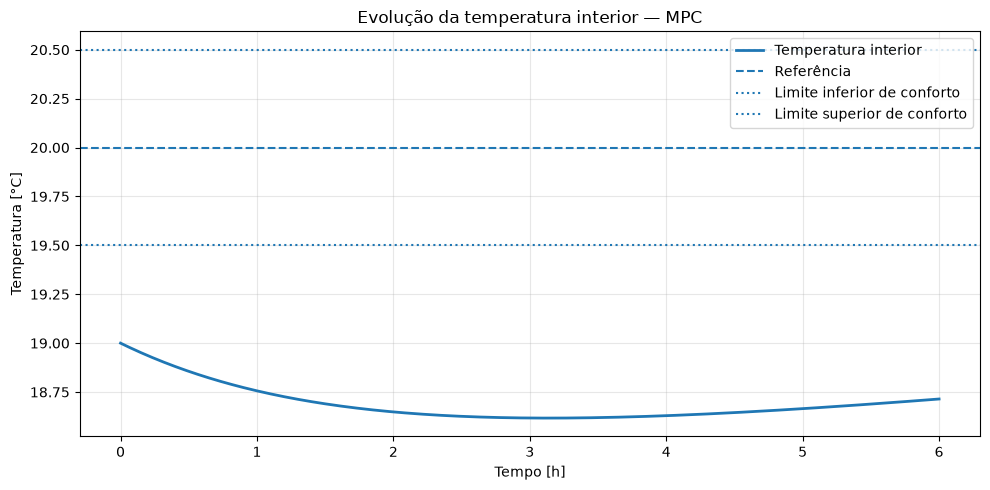

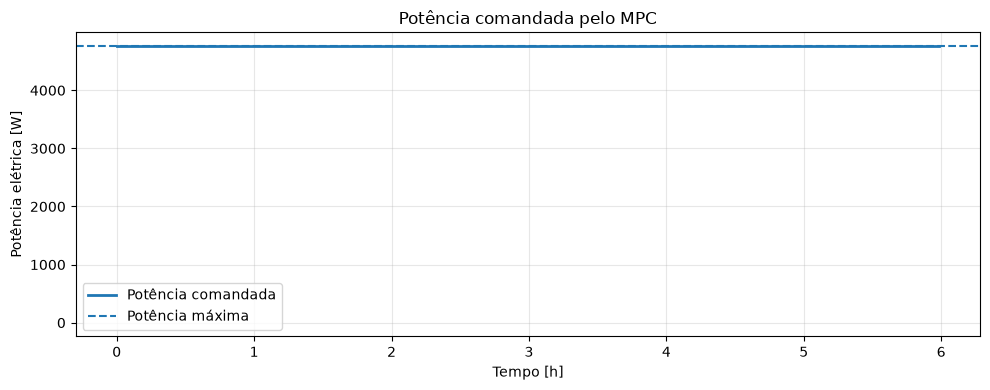

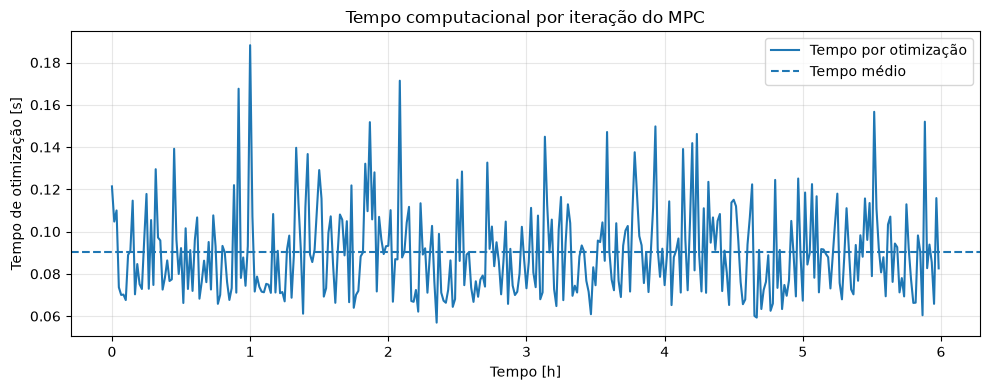

EXPORTAÇÃO DAS FIGURAS DA SIMULAÇÃO SINTÉTICA
Figura guardada: MPC_Sintetico_Temperatura.png
Figura guardada: MPC_Sintetico_Potencia.png
Figura guardada: MPC_Sintetico_Tempo_Otimizacao.png

Pasta de destino: C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras

Figuras da simulação sintética geradas e guardadas com sucesso.


In [10]:
# ============================================================
# Célula 9 — Visualização da simulação sintética MPC
# ============================================================

# ------------------------------------------------------------
# Vetores temporais
# ------------------------------------------------------------

tempo_estados_h = (
    np.arange(
        resultado_simulacao_mpc
        .temperatura_interior_c.size
    )
    * PERIODO_AMOSTRAGEM_S
    / 3600.0
)

tempo_controlo_h = (
    np.arange(
        resultado_simulacao_mpc
        .potencia_aplicada_w.size
    )
    * PERIODO_AMOSTRAGEM_S
    / 3600.0
)


# ------------------------------------------------------------
# Figura 1 — Evolução da temperatura interior
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    tempo_estados_h,
    resultado_simulacao_mpc
    .temperatura_interior_c,
    label="Temperatura interior",
    linewidth=2.0,
)

plt.axhline(
    configuracao_mpc.temperatura_referencia,
    linestyle="--",
    label="Referência",
)

plt.axhline(
    configuracao_mpc.temperatura_minima,
    linestyle=":",
    label="Limite inferior de conforto",
)

plt.axhline(
    configuracao_mpc.temperatura_maxima,
    linestyle=":",
    label="Limite superior de conforto",
)

plt.xlabel(
    "Tempo [h]"
)

plt.ylabel(
    "Temperatura [°C]"
)

plt.title(
    "Evolução da temperatura interior — MPC"
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

caminho_figura_temperatura = (
    PASTA_FIGURAS
    / "MPC_Sintetico_Temperatura.png"
)

plt.savefig(
    caminho_figura_temperatura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figura 2 — Potência comandada pelo MPC
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 4)
)

plt.step(
    tempo_controlo_h,
    resultado_simulacao_mpc
    .potencia_aplicada_w,
    where="post",
    linewidth=2.0,
    label="Potência comandada",
)

plt.axhline(
    configuracao_mpc.potencia_maxima_w,
    linestyle="--",
    label="Potência máxima",
)

plt.xlabel(
    "Tempo [h]"
)

plt.ylabel(
    "Potência elétrica [W]"
)

plt.title(
    "Potência comandada pelo MPC"
)

# Limites adequados à escala física do atuador
margem_potencia_w = (
    0.05
    * configuracao_mpc.potencia_maxima_w
)

plt.ylim(
    configuracao_mpc.potencia_minima_w
    - margem_potencia_w,
    configuracao_mpc.potencia_maxima_w
    + margem_potencia_w,
)

plt.ticklabel_format(
    axis="y",
    style="plain",
    useOffset=False,
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

caminho_figura_potencia = (
    PASTA_FIGURAS
    / "MPC_Sintetico_Potencia.png"
)

plt.savefig(
    caminho_figura_potencia,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# Figura 3 — Esforço computacional
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    tempo_controlo_h,
    resultado_simulacao_mpc
    .tempo_otimizacao_s,
    linewidth=1.5,
    label="Tempo por otimização",
)

plt.axhline(
    resultado_simulacao_mpc
    .tempo_otimizacao_medio_s,
    linestyle="--",
    label="Tempo médio",
)

plt.xlabel(
    "Tempo [h]"
)

plt.ylabel(
    "Tempo de otimização [s]"
)

plt.title(
    "Tempo computacional por iteração do MPC"
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

caminho_figura_tempo = (
    PASTA_FIGURAS
    / "MPC_Sintetico_Tempo_Otimizacao.png"
)

plt.savefig(
    caminho_figura_tempo,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Confirmação da exportação
# ------------------------------------------------------------

figuras_geradas = (
    caminho_figura_temperatura,
    caminho_figura_potencia,
    caminho_figura_tempo,
)

print("=" * 70)
print("EXPORTAÇÃO DAS FIGURAS DA SIMULAÇÃO SINTÉTICA")
print("=" * 70)

for caminho_figura in figuras_geradas:

    if not caminho_figura.is_file():

        raise FileNotFoundError(
            "A figura não foi corretamente guardada:\n"
            f"{caminho_figura}"
        )

    print(
        f"Figura guardada: "
        f"{caminho_figura.name}"
    )

print()

print(
    f"Pasta de destino: "
    f"{PASTA_FIGURAS}"
)

print()

print(
    "Figuras da simulação sintética "
    "geradas e guardadas com sucesso."
)

print("=" * 70)

In [11]:
# ============================================================
# Célula 10 — Carregamento dos dados experimentais
# sincronizados
# ============================================================

# ------------------------------------------------------------
# Caminho do ficheiro final sincronizado
# ------------------------------------------------------------

CAMINHO_DADOS_SINCRONIZADOS = (
    RAIZ_PROJETO
    / "Aquisicao_Dados"
    / "Dados_Sincronizados"
    / "Utilizados"
    / "dados_experimentais_sincronizados.csv"
)


# ------------------------------------------------------------
# Validação da existência do ficheiro
# ------------------------------------------------------------

if not CAMINHO_DADOS_SINCRONIZADOS.is_file():

    raise FileNotFoundError(
        "O ficheiro de dados sincronizados não foi encontrado.\n"
        f"Caminho esperado: "
        f"{CAMINHO_DADOS_SINCRONIZADOS}"
    )


# ------------------------------------------------------------
# Importação
# ------------------------------------------------------------

dados_experimentais = pd.read_csv(
    CAMINHO_DADOS_SINCRONIZADOS,
    sep=",",
    parse_dates=[
        "DataHora",
    ],
)


# ------------------------------------------------------------
# Validação das colunas necessárias
# ------------------------------------------------------------

COLUNAS_NECESSARIAS_MPC = (
    "DataHora",
    "T_int",
    "T_ext",
    "PSum",
)

colunas_em_falta = [
    coluna
    for coluna in COLUNAS_NECESSARIAS_MPC
    if coluna not in dados_experimentais.columns
]

if colunas_em_falta:

    raise ValueError(
        "Existem colunas necessárias ao MPC em falta:\n"
        + "\n".join(
            f"  - {coluna}"
            for coluna in colunas_em_falta
        )
    )


# ------------------------------------------------------------
# Seleção das variáveis relevantes
# ------------------------------------------------------------

dados_experimentais_mpc = (
    dados_experimentais[
        list(
            COLUNAS_NECESSARIAS_MPC
        )
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Validações de integridade
# ------------------------------------------------------------

numero_valores_em_falta = int(
    dados_experimentais_mpc
    .isna()
    .sum()
    .sum()
)

numero_instantes_duplicados = int(
    dados_experimentais_mpc[
        "DataHora"
    ]
    .duplicated()
    .sum()
)

sequencia_temporal_crescente = bool(
    dados_experimentais_mpc[
        "DataHora"
    ]
    .is_monotonic_increasing
)


# ------------------------------------------------------------
# Validação do período de amostragem
# ------------------------------------------------------------

intervalos_s = (
    dados_experimentais_mpc[
        "DataHora"
    ]
    .diff()
    .dropna()
    .dt.total_seconds()
    .to_numpy(dtype=float)
)

intervalo_mediano_s = float(
    np.median(
        intervalos_s
    )
)

intervalos_regulares = bool(
    np.allclose(
        intervalos_s,
        PERIODO_AMOSTRAGEM_S,
        atol=1.0e-9,
    )
)


# ------------------------------------------------------------
# Aprovação
# ------------------------------------------------------------

dados_experimentais_validos = (
    numero_valores_em_falta == 0
    and numero_instantes_duplicados == 0
    and sequencia_temporal_crescente
    and intervalos_regulares
)

if not dados_experimentais_validos:

    raise RuntimeError(
        "Os dados experimentais não foram validados "
        "para utilização pelo MPC."
    )


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 70)
print("DADOS EXPERIMENTAIS PARA APLICAÇÃO DO MPC")
print("=" * 70)

print(
    f"Ficheiro: "
    f"{CAMINHO_DADOS_SINCRONIZADOS.name}"
)

print(
    f"Número de registos: "
    f"{len(dados_experimentais_mpc)}"
)

print(
    f"Primeiro instante: "
    f"{dados_experimentais_mpc['DataHora'].iloc[0]}"
)

print(
    f"Último instante: "
    f"{dados_experimentais_mpc['DataHora'].iloc[-1]}"
)

print()

print(
    f"Intervalo mediano: "
    f"{intervalo_mediano_s:.2f} s"
)

print(
    f"Sequência temporal crescente: "
    f"{sequencia_temporal_crescente}"
)

print(
    f"Instantes duplicados: "
    f"{numero_instantes_duplicados}"
)

print(
    f"Valores em falta: "
    f"{numero_valores_em_falta}"
)

print(
    f"Intervalos regulares: "
    f"{intervalos_regulares}"
)

print()

print("Intervalos das variáveis:")

print(
    f"T_int: "
    f"{dados_experimentais_mpc['T_int'].min():.3f} "
    f"a "
    f"{dados_experimentais_mpc['T_int'].max():.3f} °C"
)

print(
    f"T_ext: "
    f"{dados_experimentais_mpc['T_ext'].min():.3f} "
    f"a "
    f"{dados_experimentais_mpc['T_ext'].max():.3f} °C"
)

print(
    f"PSum: "
    f"{dados_experimentais_mpc['PSum'].min():.3f} "
    f"a "
    f"{dados_experimentais_mpc['PSum'].max():.3f} kW"
)

print()

print(
    "Dados experimentais carregados e "
    "validados com sucesso."
)

print("=" * 70)

DADOS EXPERIMENTAIS PARA APLICAÇÃO DO MPC
Ficheiro: dados_experimentais_sincronizados.csv
Número de registos: 10080
Primeiro instante: 2026-05-16 16:45:55
Último instante: 2026-05-23 16:44:55

Intervalo mediano: 60.00 s
Sequência temporal crescente: True
Instantes duplicados: 0
Valores em falta: 0
Intervalos regulares: True

Intervalos das variáveis:
T_int: 21.279 a 24.518 °C
T_ext: 9.810 a 30.535 °C
PSum: 0.000 a 4.760 kW

Dados experimentais carregados e validados com sucesso.


In [12]:
# ============================================================
# Célula 11 — Seleção do período experimental de 24 h
# ============================================================

# ------------------------------------------------------------
# Duração do período experimental
# ------------------------------------------------------------

DURACAO_PERIODO_EXPERIMENTAL_H = 24

numero_passos_experimentais = int(
    DURACAO_PERIODO_EXPERIMENTAL_H
    * 3600
    / PERIODO_AMOSTRAGEM_S
)


# ------------------------------------------------------------
# Seleção inicial das primeiras 24 horas
# ------------------------------------------------------------

dados_periodo_experimental = (
    dados_experimentais_mpc
    .iloc[
        :numero_passos_experimentais
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Extração das variáveis
# ------------------------------------------------------------

instantes_experimentais = (
    dados_periodo_experimental[
        "DataHora"
    ]
    .to_numpy()
)

temperatura_interior_experimental_c = (
    dados_periodo_experimental[
        "T_int"
    ]
    .to_numpy(dtype=float)
)

temperatura_exterior_experimental_c = (
    dados_periodo_experimental[
        "T_ext"
    ]
    .to_numpy(dtype=float)
)

potencia_experimental_w = (
    dados_periodo_experimental[
        "PSum"
    ]
    .to_numpy(dtype=float)
    * 1000.0
)


# ------------------------------------------------------------
# Validação do número de amostras
# ------------------------------------------------------------

numero_amostras_periodo = (
    len(
        dados_periodo_experimental
    )
)

periodo_completo = (
    numero_amostras_periodo
    == numero_passos_experimentais
)

if not periodo_completo:

    raise RuntimeError(
        "O período experimental selecionado "
        "não contém as 24 horas completas."
    )


# ------------------------------------------------------------
# Validação da potência convertida
# ------------------------------------------------------------

potencia_experimental_valida = bool(
    np.all(
        (
            potencia_experimental_w
            >= configuracao_mpc.potencia_minima_w
            - 1.0e-6
        )
        & (
            potencia_experimental_w
            <= configuracao_mpc.potencia_maxima_w
            + 1.0e-6
        )
    )
)

if not potencia_experimental_valida:

    raise RuntimeError(
        "A potência experimental convertida para watt "
        "encontra-se fora dos limites esperados."
    )


# ------------------------------------------------------------
# Apresentação do período selecionado
# ------------------------------------------------------------

print("=" * 70)
print("PERÍODO EXPERIMENTAL SELECIONADO PARA O MPC")
print("=" * 70)

print(
    f"Duração: "
    f"{DURACAO_PERIODO_EXPERIMENTAL_H:.0f} h"
)

print(
    f"Número de amostras: "
    f"{numero_amostras_periodo}"
)

print(
    f"Primeiro instante: "
    f"{dados_periodo_experimental['DataHora'].iloc[0]}"
)

print(
    f"Último instante: "
    f"{dados_periodo_experimental['DataHora'].iloc[-1]}"
)

print()

print(
    "Temperatura interior experimental:"
)

print(
    f"Inicial = "
    f"{temperatura_interior_experimental_c[0]:.3f} °C"
)

print(
    f"Mínima = "
    f"{temperatura_interior_experimental_c.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_interior_experimental_c.max():.3f} °C"
)

print()

print(
    "Temperatura exterior experimental:"
)

print(
    f"Mínima = "
    f"{temperatura_exterior_experimental_c.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_exterior_experimental_c.max():.3f} °C"
)

print()

print(
    "Potência experimental:"
)

print(
    f"Mínima = "
    f"{potencia_experimental_w.min():.2f} W"
)

print(
    f"Máxima = "
    f"{potencia_experimental_w.max():.2f} W"
)

print(
    f"Média = "
    f"{potencia_experimental_w.mean():.2f} W"
)

print()

print(
    f"Potência experimental dentro dos limites: "
    f"{potencia_experimental_valida}"
)

print()

print(
    "Período experimental de 24 horas "
    "selecionado e validado com sucesso."
)

print("=" * 70)

PERÍODO EXPERIMENTAL SELECIONADO PARA O MPC
Duração: 24 h
Número de amostras: 1440
Primeiro instante: 2026-05-16 16:45:55
Último instante: 2026-05-17 16:44:55

Temperatura interior experimental:
Inicial = 22.490 °C
Mínima = 21.360 °C
Máxima = 22.490 °C

Temperatura exterior experimental:
Mínima = 10.470 °C
Máxima = 24.050 °C

Potência experimental:
Mínima = 0.00 W
Máxima = 4620.00 W
Média = 1345.68 W

Potência experimental dentro dos limites: True

Período experimental de 24 horas selecionado e validado com sucesso.


In [13]:
# ============================================================
# Célula 12 — Simulação MPC com condições experimentais
# ============================================================

# ------------------------------------------------------------
# Estado térmico inicial
#
# T_int é obtida diretamente da medição.
# T_m não é medida, pelo que se adota inicialmente:
#
# T_m(0) = T_int(0)
#
# mantendo a hipótese utilizada na identificação do modelo.
# ------------------------------------------------------------

estado_inicial_mpc_experimental = np.array(
    [
        temperatura_interior_experimental_c[0],
        temperatura_interior_experimental_c[0],
    ],
    dtype=float,
)


# ------------------------------------------------------------
# Potência imediatamente anterior
#
# Utiliza-se a primeira medição experimental como melhor
# aproximação disponível da condição inicial do atuador.
# ------------------------------------------------------------

potencia_inicial_mpc_experimental_w = float(
    potencia_experimental_w[0]
)


# ------------------------------------------------------------
# Execução da simulação MPC
# ------------------------------------------------------------

resultado_mpc_experimental = (
    simular_mpc_horizonte_deslizante(
        matrizes=(
            matrizes_discretas_2r2c_selecionadas
        ),
        estado_inicial=(
            estado_inicial_mpc_experimental
        ),
        temperatura_exterior_c=(
            temperatura_exterior_experimental_c
        ),
        configuracao=configuracao_mpc,
        temperatura_referencia=(
            configuracao_mpc.temperatura_referencia
        ),
        potencia_inicial_w=(
            potencia_inicial_mpc_experimental_w
        ),
        numero_passos=(
            numero_passos_experimentais
        ),
        maximo_iteracoes=300,
        utilizar_warm_start=True,
        interromper_em_falha=True,
    )
)


# ------------------------------------------------------------
# Validação estrutural e numérica
# ------------------------------------------------------------

validar_resultado_simulacao_mpc(
    resultado=resultado_mpc_experimental,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Resumo da simulação
# ------------------------------------------------------------

mostrar_resumo_simulacao_mpc(
    resultado=resultado_mpc_experimental,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Extração das variáveis principais
# ------------------------------------------------------------

temperatura_mpc_experimental_c = (
    resultado_mpc_experimental
    .temperatura_interior_c
)

potencia_mpc_experimental_w = (
    resultado_mpc_experimental
    .potencia_aplicada_w
)


# ------------------------------------------------------------
# Energia elétrica
# ------------------------------------------------------------

energia_mpc_experimental_kwh = (
    np.sum(
        potencia_mpc_experimental_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)

energia_convencional_experimental_kwh = (
    np.sum(
        potencia_experimental_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Análise preliminar de conforto do MPC
# ------------------------------------------------------------

temperatura_mpc_para_analise_c = (
    temperatura_mpc_experimental_c[1:]
)

dentro_conforto_mpc = (
    (
        temperatura_mpc_para_analise_c
        >= configuracao_mpc.temperatura_minima
    )
    & (
        temperatura_mpc_para_analise_c
        <= configuracao_mpc.temperatura_maxima
    )
)

percentagem_conforto_mpc = (
    100.0
    * np.mean(
        dentro_conforto_mpc
    )
)


# ------------------------------------------------------------
# Análise preliminar de conforto experimental
# ------------------------------------------------------------

dentro_conforto_experimental = (
    (
        temperatura_interior_experimental_c
        >= configuracao_mpc.temperatura_minima
    )
    & (
        temperatura_interior_experimental_c
        <= configuracao_mpc.temperatura_maxima
    )
)

percentagem_conforto_experimental = (
    100.0
    * np.mean(
        dentro_conforto_experimental
    )
)


# ------------------------------------------------------------
# Diferença de energia
# ------------------------------------------------------------

diferenca_energia_kwh = (
    energia_mpc_experimental_kwh
    - energia_convencional_experimental_kwh
)

if energia_convencional_experimental_kwh > 0:

    diferenca_energia_percentagem = (
        diferenca_energia_kwh
        / energia_convencional_experimental_kwh
        * 100.0
    )

else:

    diferenca_energia_percentagem = np.nan


# ------------------------------------------------------------
# Validação dos limites da potência
# ------------------------------------------------------------

potencia_mpc_dentro_limites = bool(
    np.all(
        (
            potencia_mpc_experimental_w
            >= configuracao_mpc.potencia_minima_w
            - 1.0e-6
        )
        & (
            potencia_mpc_experimental_w
            <= configuracao_mpc.potencia_maxima_w
            + 1.0e-6
        )
    )
)


# ------------------------------------------------------------
# Apresentação dos resultados preliminares
# ------------------------------------------------------------

print()
print("=" * 75)
print("APLICAÇÃO DO MPC ÀS CONDIÇÕES EXPERIMENTAIS — 24 H")
print("=" * 75)

print(
    f"Estado inicial:"
)

print(
    f"T_int(0) = "
    f"{estado_inicial_mpc_experimental[0]:.3f} °C"
)

print(
    f"T_m(0)   = "
    f"{estado_inicial_mpc_experimental[1]:.3f} °C"
)

print(
    f"P_anterior = "
    f"{potencia_inicial_mpc_experimental_w:.2f} W"
)

print()

print(
    f"Todas as otimizações convergiram: "
    f"{resultado_mpc_experimental.todas_otimizacoes_convergiram}"
)

print(
    f"Potência MPC dentro dos limites: "
    f"{potencia_mpc_dentro_limites}"
)

print()

print("Temperatura prevista com MPC:")

print(
    f"Inicial = "
    f"{temperatura_mpc_experimental_c[0]:.3f} °C"
)

print(
    f"Final = "
    f"{temperatura_mpc_experimental_c[-1]:.3f} °C"
)

print(
    f"Mínima = "
    f"{temperatura_mpc_experimental_c.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_mpc_experimental_c.max():.3f} °C"
)

print()

print("Potência comandada pelo MPC:")

print(
    f"Mínima = "
    f"{potencia_mpc_experimental_w.min():.2f} W"
)

print(
    f"Máxima = "
    f"{potencia_mpc_experimental_w.max():.2f} W"
)

print(
    f"Média = "
    f"{potencia_mpc_experimental_w.mean():.2f} W"
)

print()

print("Energia elétrica:")

print(
    f"MPC = "
    f"{energia_mpc_experimental_kwh:.3f} kWh"
)

print(
    f"Experimental = "
    f"{energia_convencional_experimental_kwh:.3f} kWh"
)

print(
    f"Diferença = "
    f"{diferenca_energia_kwh:.3f} kWh"
)

print(
    f"Diferença relativa = "
    f"{diferenca_energia_percentagem:.2f} %"
)

print()

print("Conforto térmico:")

print(
    f"MPC = "
    f"{percentagem_conforto_mpc:.2f} %"
)

print(
    f"Experimental = "
    f"{percentagem_conforto_experimental:.2f} %"
)

print()

validacao_aplicacao_experimental = (
    resultado_mpc_experimental
    .todas_otimizacoes_convergiram
    and potencia_mpc_dentro_limites
)

print(
    f"Validação da aplicação experimental: "
    f"{validacao_aplicacao_experimental}"
)

if not validacao_aplicacao_experimental:

    raise RuntimeError(
        "A aplicação do MPC às condições experimentais "
        "não foi validada."
    )

print()

print(
    "Aplicação preliminar do MPC às condições "
    "experimentais concluída com sucesso."
)

print("=" * 75)

SIMULAÇÃO MPC EM HORIZONTE DESLIZANTE
Número de passos simulados: 1440
Taxa de convergência: 100.00 %

Temperatura interior:
Inicial = 22.490 °C
Final = 21.571 °C
Mínima = 21.208 °C
Máxima = 22.493 °C

Potência aplicada:
Mínima = 0.00 W
Máxima = 0.00 W
Média = 0.00 W

Esforço computacional:
Iterações médias = 2.95
Avaliações médias = 13.00
Tempo médio por otimização = 0.0223 s
Tempo acumulado de otimização = 32.1495 s

APLICAÇÃO DO MPC ÀS CONDIÇÕES EXPERIMENTAIS — 24 H
Estado inicial:
T_int(0) = 22.490 °C
T_m(0)   = 22.490 °C
P_anterior = 0.00 W

Todas as otimizações convergiram: True
Potência MPC dentro dos limites: True

Temperatura prevista com MPC:
Inicial = 22.490 °C
Final = 21.571 °C
Mínima = 21.208 °C
Máxima = 22.493 °C

Potência comandada pelo MPC:
Mínima = 0.00 W
Máxima = 0.00 W
Média = 0.00 W

Energia elétrica:
MPC = 0.000 kWh
Experimental = 32.296 kWh
Diferença = -32.296 kWh
Diferença relativa = -100.00 %

Conforto térmico:
MPC = 0.00 %
Experimental = 0.00 %

Validação da ap

In [14]:
# ============================================================
# Célula 13 — Diagnóstico do funcionamento experimental
# ============================================================

# ------------------------------------------------------------
# Definição do estado de funcionamento
# ------------------------------------------------------------

LIMIAR_POTENCIA_ATIVA_W = 100.0

sistema_ativo = (
    potencia_experimental_w
    > LIMIAR_POTENCIA_ATIVA_W
)

numero_amostras_ativo = int(
    np.sum(
        sistema_ativo
    )
)

percentagem_tempo_ativo = (
    100.0
    * np.mean(
        sistema_ativo
    )
)


# ------------------------------------------------------------
# Energia durante o período
# ------------------------------------------------------------

energia_total_experimental_kwh = (
    np.sum(
        potencia_experimental_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Funcionamento acima da banda de conforto
# ------------------------------------------------------------

acima_limite_superior = (
    temperatura_interior_experimental_c
    > configuracao_mpc.temperatura_maxima
)

sistema_ativo_acima_conforto = (
    sistema_ativo
    & acima_limite_superior
)

numero_amostras_ativo_acima = int(
    np.sum(
        sistema_ativo_acima_conforto
    )
)

if numero_amostras_ativo > 0:

    percentagem_funcionamento_acima = (
        100.0
        * numero_amostras_ativo_acima
        / numero_amostras_ativo
    )

else:

    percentagem_funcionamento_acima = 0.0


energia_acima_conforto_kwh = (
    np.sum(
        potencia_experimental_w[
            acima_limite_superior
        ]
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Condições térmicas durante o funcionamento
# ------------------------------------------------------------

if numero_amostras_ativo > 0:

    temperatura_interior_ativa_media = float(
        np.mean(
            temperatura_interior_experimental_c[
                sistema_ativo
            ]
        )
    )

    temperatura_exterior_ativa_media = float(
        np.mean(
            temperatura_exterior_experimental_c[
                sistema_ativo
            ]
        )
    )

    potencia_ativa_media_w = float(
        np.mean(
            potencia_experimental_w[
                sistema_ativo
            ]
        )
    )

else:

    temperatura_interior_ativa_media = np.nan
    temperatura_exterior_ativa_media = np.nan
    potencia_ativa_media_w = np.nan


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 75)
print("DIAGNÓSTICO DO FUNCIONAMENTO EXPERIMENTAL — 24 H")
print("=" * 75)

print(
    f"Limiar adotado para funcionamento ativo: "
    f"{LIMIAR_POTENCIA_ATIVA_W:.0f} W"
)

print()

print(
    f"Tempo com sistema ativo: "
    f"{percentagem_tempo_ativo:.2f} %"
)

print(
    f"Número de amostras ativas: "
    f"{numero_amostras_ativo}"
)

print()

print(
    f"Temperatura interior média com sistema ativo: "
    f"{temperatura_interior_ativa_media:.3f} °C"
)

print(
    f"Temperatura exterior média com sistema ativo: "
    f"{temperatura_exterior_ativa_media:.3f} °C"
)

print(
    f"Potência média quando ativo: "
    f"{potencia_ativa_media_w:.2f} W"
)

print()

print(
    f"Funcionamento ativo com T_int > T_max: "
    f"{percentagem_funcionamento_acima:.2f} %"
)

print(
    f"Energia total experimental: "
    f"{energia_total_experimental_kwh:.3f} kWh"
)

print(
    f"Energia consumida com T_int > T_max: "
    f"{energia_acima_conforto_kwh:.3f} kWh"
)

print()

print(
    "Diagnóstico experimental concluído."
)

print("=" * 75)

DIAGNÓSTICO DO FUNCIONAMENTO EXPERIMENTAL — 24 H
Limiar adotado para funcionamento ativo: 100 W

Tempo com sistema ativo: 37.43 %
Número de amostras ativas: 539

Temperatura interior média com sistema ativo: 21.763 °C
Temperatura exterior média com sistema ativo: 15.078 °C
Potência média quando ativo: 3595.14 W

Funcionamento ativo com T_int > T_max: 100.00 %
Energia total experimental: 32.296 kWh
Energia consumida com T_int > T_max: 32.296 kWh

Diagnóstico experimental concluído.


In [15]:
# ============================================================
# Célula 14 — Análise dos arranques e resposta térmica
# experimental
# ============================================================

# ------------------------------------------------------------
# Preparação dos dados completos dos 7 dias
# ------------------------------------------------------------

instantes_completos = (
    dados_experimentais_mpc[
        "DataHora"
    ]
    .reset_index(drop=True)
)

temperatura_interior_completa_c = (
    dados_experimentais_mpc[
        "T_int"
    ]
    .to_numpy(dtype=float)
)

temperatura_exterior_completa_c = (
    dados_experimentais_mpc[
        "T_ext"
    ]
    .to_numpy(dtype=float)
)

potencia_completa_w = (
    dados_experimentais_mpc[
        "PSum"
    ]
    .to_numpy(dtype=float)
    * 1000.0
)


# ------------------------------------------------------------
# Definição do estado ativo
# ------------------------------------------------------------

LIMIAR_POTENCIA_ATIVA_W = 100.0

sistema_ativo_completo = (
    potencia_completa_w
    > LIMIAR_POTENCIA_ATIVA_W
)


# ------------------------------------------------------------
# Identificação dos arranques
#
# Um arranque corresponde à transição:
#
# sistema inativo -> sistema ativo
# ------------------------------------------------------------

indices_arranque = np.where(
    (~sistema_ativo_completo[:-1])
    & (sistema_ativo_completo[1:])
)[0] + 1


# ------------------------------------------------------------
# Horizontes para análise da resposta térmica
# ------------------------------------------------------------

HORIZONTES_ANALISE_MIN = (
    10,
    30,
    60,
    120,
    180,
)

resultados_arranques = []


# ------------------------------------------------------------
# Análise individual dos arranques
# ------------------------------------------------------------

for indice_arranque in indices_arranque:

    # É necessário garantir que existem pelo menos
    # 180 minutos de dados após o arranque.

    if (
        indice_arranque
        + max(HORIZONTES_ANALISE_MIN)
        >= len(
            temperatura_interior_completa_c
        )
    ):
        continue

    instante_arranque = (
        instantes_completos.iloc[
            indice_arranque
        ]
    )

    temperatura_inicial_c = float(
        temperatura_interior_completa_c[
            indice_arranque
        ]
    )

    temperatura_exterior_inicial_c = float(
        temperatura_exterior_completa_c[
            indice_arranque
        ]
    )

    potencia_arranque_w = float(
        potencia_completa_w[
            indice_arranque
        ]
    )

    resultado = {
        "DataHora": instante_arranque,
        "Hora": instante_arranque.hour,
        "Minuto": instante_arranque.minute,
        "T_int_arranque_C": temperatura_inicial_c,
        "T_ext_arranque_C": temperatura_exterior_inicial_c,
        "P_arranque_W": potencia_arranque_w,
    }

    for horizonte_min in HORIZONTES_ANALISE_MIN:

        temperatura_futura_c = float(
            temperatura_interior_completa_c[
                indice_arranque
                + horizonte_min
            ]
        )

        resultado[
            f"Delta_T_{horizonte_min}min_C"
        ] = (
            temperatura_futura_c
            - temperatura_inicial_c
        )

    resultados_arranques.append(
        resultado
    )


# ------------------------------------------------------------
# Construção da tabela
# ------------------------------------------------------------

tabela_arranques = pd.DataFrame(
    resultados_arranques
)


if tabela_arranques.empty:

    raise RuntimeError(
        "Não foram encontrados arranques válidos "
        "para a análise térmica."
    )


# ------------------------------------------------------------
# Distribuição horária dos arranques
# ------------------------------------------------------------

distribuicao_horaria_arranques = (
    tabela_arranques[
        "Hora"
    ]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# Estatísticas da resposta térmica
# ------------------------------------------------------------

estatisticas_resposta = []

for horizonte_min in HORIZONTES_ANALISE_MIN:

    coluna = (
        f"Delta_T_{horizonte_min}min_C"
    )

    estatisticas_resposta.append(
        {
            "Horizonte_min":
                horizonte_min,

            "Delta_T_medio_C":
                tabela_arranques[
                    coluna
                ].mean(),

            "Delta_T_mediano_C":
                tabela_arranques[
                    coluna
                ].median(),

            "Delta_T_minimo_C":
                tabela_arranques[
                    coluna
                ].min(),

            "Delta_T_maximo_C":
                tabela_arranques[
                    coluna
                ].max(),

            "Percentagem_aumento":
                100.0
                * np.mean(
                    tabela_arranques[
                        coluna
                    ]
                    > 0.0
                ),
        }
    )

tabela_resposta_termica = pd.DataFrame(
    estatisticas_resposta
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 85)
print("ANÁLISE DOS ARRANQUES E DA RESPOSTA TÉRMICA — 7 DIAS")
print("=" * 85)

print(
    f"Número total de arranques identificados: "
    f"{len(indices_arranque)}"
)

print(
    f"Número de arranques analisados: "
    f"{len(tabela_arranques)}"
)

print()

print(
    "DISTRIBUIÇÃO DOS ARRANQUES POR HORA"
)

print("-" * 45)

for hora, numero_arranques in (
    distribuicao_horaria_arranques.items()
):

    print(
        f"{hora:02d}:00–{hora:02d}:59 -> "
        f"{numero_arranques} arranques"
    )


print()
print(
    "RESPOSTA DA TEMPERATURA APÓS OS ARRANQUES"
)
print("-" * 85)

print(
    tabela_resposta_termica.to_string(
        index=False,
        formatters={
            "Delta_T_medio_C":
                "{:.4f}".format,

            "Delta_T_mediano_C":
                "{:.4f}".format,

            "Delta_T_minimo_C":
                "{:.4f}".format,

            "Delta_T_maximo_C":
                "{:.4f}".format,

            "Percentagem_aumento":
                "{:.2f}".format,
        },
    )
)


# ------------------------------------------------------------
# Arranques individuais
# ------------------------------------------------------------

print()
print(
    "PRIMEIROS 20 ARRANQUES IDENTIFICADOS"
)
print("-" * 85)

colunas_apresentacao = [
    "DataHora",
    "T_int_arranque_C",
    "T_ext_arranque_C",
    "P_arranque_W",
    "Delta_T_30min_C",
    "Delta_T_60min_C",
    "Delta_T_120min_C",
]

print(
    tabela_arranques[
        colunas_apresentacao
    ]
    .head(20)
    .to_string(
        index=False,
        formatters={
            "T_int_arranque_C":
                "{:.3f}".format,

            "T_ext_arranque_C":
                "{:.3f}".format,

            "P_arranque_W":
                "{:.0f}".format,

            "Delta_T_30min_C":
                "{:+.3f}".format,

            "Delta_T_60min_C":
                "{:+.3f}".format,

            "Delta_T_120min_C":
                "{:+.3f}".format,
        },
    )
)

print()
print(
    "Análise dos arranques concluída com sucesso."
)

print("=" * 85)

ANÁLISE DOS ARRANQUES E DA RESPOSTA TÉRMICA — 7 DIAS
Número total de arranques identificados: 239
Número de arranques analisados: 232

DISTRIBUIÇÃO DOS ARRANQUES POR HORA
---------------------------------------------
00:00–00:59 -> 8 arranques
01:00–01:59 -> 8 arranques
02:00–02:59 -> 8 arranques
03:00–03:59 -> 8 arranques
04:00–04:59 -> 7 arranques
05:00–05:59 -> 9 arranques
06:00–06:59 -> 5 arranques
07:00–07:59 -> 7 arranques
08:00–08:59 -> 8 arranques
09:00–09:59 -> 8 arranques
10:00–10:59 -> 13 arranques
11:00–11:59 -> 11 arranques
12:00–12:59 -> 14 arranques
13:00–13:59 -> 12 arranques
14:00–14:59 -> 12 arranques
15:00–15:59 -> 11 arranques
16:00–16:59 -> 12 arranques
17:00–17:59 -> 13 arranques
18:00–18:59 -> 10 arranques
19:00–19:59 -> 11 arranques
20:00–20:59 -> 10 arranques
21:00–21:59 -> 10 arranques
22:00–22:59 -> 7 arranques
23:00–23:59 -> 10 arranques

RESPOSTA DA TEMPERATURA APÓS OS ARRANQUES
-------------------------------------------------------------------------------

In [16]:
# ============================================================
# Célula 15 — Análise diária da tendência da temperatura
# interior
# ============================================================

# ------------------------------------------------------------
# Preparação dos dados completos
# ------------------------------------------------------------

dados_tendencia = (
    dados_experimentais_mpc[
        [
            "DataHora",
            "T_int",
            "T_ext",
            "PSum",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

dados_tendencia[
    "P_W"
] = (
    dados_tendencia[
        "PSum"
    ]
    * 1000.0
)


# ------------------------------------------------------------
# Suavização da temperatura interior
#
# Média móvel centrada de 30 minutos.
# Esta suavização é utilizada apenas para análise de tendência
# e não altera os dados utilizados pelo modelo ou pelo MPC.
# ------------------------------------------------------------

JANELA_SUAVIZACAO_MIN = 30

dados_tendencia[
    "T_int_suavizada"
] = (
    dados_tendencia[
        "T_int"
    ]
    .rolling(
        window=JANELA_SUAVIZACAO_MIN,
        center=True,
        min_periods=1,
    )
    .mean()
)


# ------------------------------------------------------------
# Variação da temperatura numa janela de 30 minutos
# ------------------------------------------------------------

JANELA_VARIACAO_MIN = 30

dados_tendencia[
    "Delta_T_30min"
] = (
    dados_tendencia[
        "T_int_suavizada"
    ]
    .diff(
        periods=JANELA_VARIACAO_MIN
    )
)


# ------------------------------------------------------------
# Classificação da tendência
#
# Introduz-se uma pequena zona neutra para evitar classificar
# ruído experimental como aquecimento/arrefecimento.
# ------------------------------------------------------------

LIMIAR_VARIACAO_C = 0.02

dados_tendencia[
    "Tendencia"
] = 0

dados_tendencia.loc[
    dados_tendencia[
        "Delta_T_30min"
    ] > LIMIAR_VARIACAO_C,
    "Tendencia",
] = 1

dados_tendencia.loc[
    dados_tendencia[
        "Delta_T_30min"
    ] < -LIMIAR_VARIACAO_C,
    "Tendencia",
] = -1


# ------------------------------------------------------------
# Variáveis temporais
# ------------------------------------------------------------

dados_tendencia[
    "Data"
] = (
    dados_tendencia[
        "DataHora"
    ]
    .dt.date
)

dados_tendencia[
    "Hora_decimal"
] = (
    dados_tendencia[
        "DataHora"
    ]
    .dt.hour
    + dados_tendencia[
        "DataHora"
    ]
    .dt.minute
    / 60.0
)


# ------------------------------------------------------------
# Resumo horário da evolução térmica
# ------------------------------------------------------------

dados_tendencia[
    "Hora"
] = (
    dados_tendencia[
        "DataHora"
    ]
    .dt.hour
)

resumo_horario = (
    dados_tendencia
    .groupby(
        "Hora"
    )
    .agg(
        T_int_media=(
            "T_int",
            "mean",
        ),
        T_int_suavizada_media=(
            "T_int_suavizada",
            "mean",
        ),
        Delta_T_30min_media=(
            "Delta_T_30min",
            "mean",
        ),
        P_media_W=(
            "P_W",
            "mean",
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------
# Percentagem de amostras com tendência crescente por hora
# ------------------------------------------------------------

percentagem_subida_horaria = (
    dados_tendencia
    .groupby(
        "Hora"
    )[
        "Tendencia"
    ]
    .apply(
        lambda x:
        100.0
        * np.mean(
            x == 1
        )
    )
)

resumo_horario[
    "Percentagem_subida"
] = (
    resumo_horario[
        "Hora"
    ]
    .map(
        percentagem_subida_horaria
    )
)


# ------------------------------------------------------------
# Apresentação do resumo
# ------------------------------------------------------------

print("=" * 90)
print("EVOLUÇÃO HORÁRIA DA TEMPERATURA INTERIOR — 7 DIAS")
print("=" * 90)

print(
    resumo_horario.to_string(
        index=False,
        formatters={
            "T_int_media":
                "{:.3f}".format,

            "T_int_suavizada_media":
                "{:.3f}".format,

            "Delta_T_30min_media":
                "{:+.4f}".format,

            "P_media_W":
                "{:.1f}".format,

            "Percentagem_subida":
                "{:.1f}".format,
        },
    )
)

print()

print(
    f"Janela de suavização: "
    f"{JANELA_SUAVIZACAO_MIN} min"
)

print(
    f"Janela de análise da variação: "
    f"{JANELA_VARIACAO_MIN} min"
)

print(
    f"Limiar de mudança térmica: "
    f"±{LIMIAR_VARIACAO_C:.3f} °C"
)

print()

print(
    "Análise da tendência térmica concluída com sucesso."
)

print("=" * 90)

EVOLUÇÃO HORÁRIA DA TEMPERATURA INTERIOR — 7 DIAS
 Hora T_int_media T_int_suavizada_media Delta_T_30min_media P_media_W Percentagem_subida
    0      22.450                22.450             -0.0253    1406.1               11.0
    1      22.420                22.420             -0.0142    1400.3                5.2
    2      22.358                22.358             -0.0364    1428.1                0.0
    3      22.321                22.320             -0.0106    1439.9                5.5
    4      22.276                22.278             -0.0233    1441.1                2.6
    5      22.273                22.272             +0.0007    1270.0               21.4
    6      22.248                22.250             -0.0179    1315.0                9.3
    7      22.229                22.226             -0.0078    1261.0               20.5
    8      22.199                22.201             -0.0035    1180.4               36.7
    9      22.274                22.275             +0.0474 

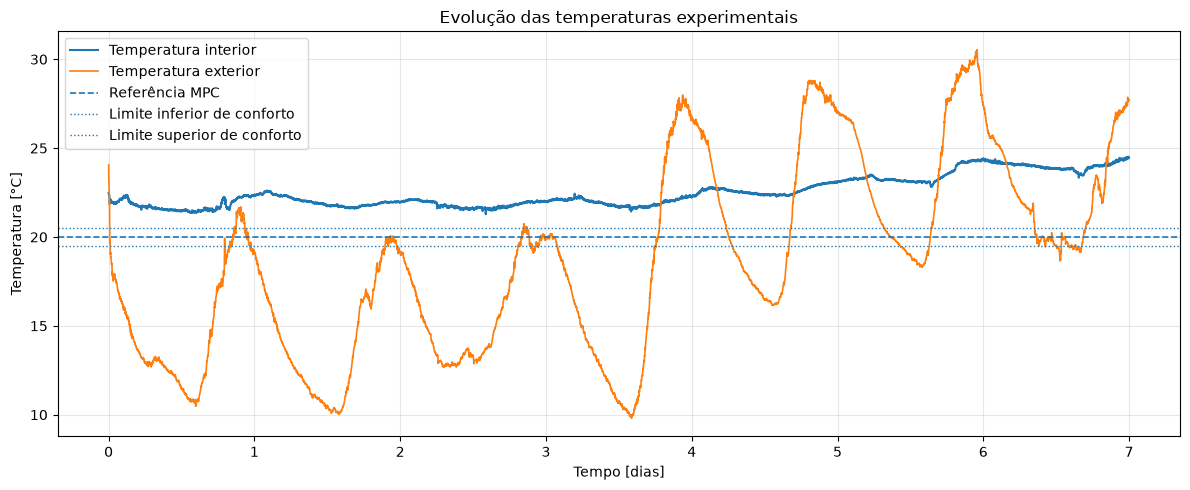

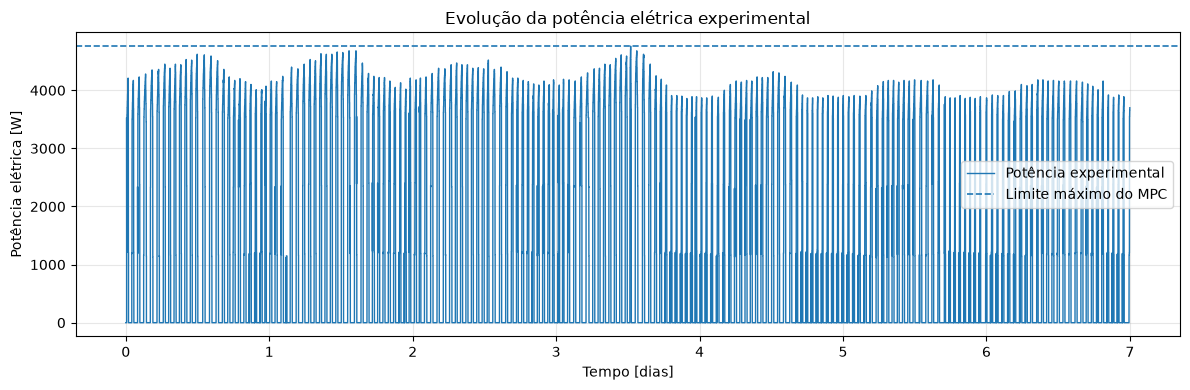

FIGURAS DOS DADOS EXPERIMENTAIS — 7 DIAS
Figura guardada: Experimental_7d_Temperaturas.png
Figura guardada: Experimental_7d_Potencia.png

Pasta de destino: C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras

Figuras experimentais geradas e guardadas com sucesso.


In [17]:
# ============================================================
# Célula 16 — Visualização global dos dados experimentais
# ============================================================

# ------------------------------------------------------------
# Preparação do eixo temporal
# ------------------------------------------------------------

tempo_experimental_dias = (
    (
        dados_experimentais_mpc["DataHora"]
        - dados_experimentais_mpc["DataHora"].iloc[0]
    )
    .dt.total_seconds()
    .to_numpy(dtype=float)
    / 86400.0
)

temperatura_interior_7d_c = (
    dados_experimentais_mpc[
        "T_int"
    ]
    .to_numpy(dtype=float)
)

temperatura_exterior_7d_c = (
    dados_experimentais_mpc[
        "T_ext"
    ]
    .to_numpy(dtype=float)
)

potencia_experimental_7d_w = (
    dados_experimentais_mpc[
        "PSum"
    ]
    .to_numpy(dtype=float)
    * 1000.0
)


# ------------------------------------------------------------
# Figura 1 — Temperaturas interior e exterior
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 5)
)

plt.plot(
    tempo_experimental_dias,
    temperatura_interior_7d_c,
    linewidth=1.5,
    label="Temperatura interior",
)

plt.plot(
    tempo_experimental_dias,
    temperatura_exterior_7d_c,
    linewidth=1.2,
    label="Temperatura exterior",
)

plt.axhline(
    configuracao_mpc.temperatura_referencia,
    linestyle="--",
    linewidth=1.2,
    label="Referência MPC",
)

plt.axhline(
    configuracao_mpc.temperatura_minima,
    linestyle=":",
    linewidth=1.0,
    label="Limite inferior de conforto",
)

plt.axhline(
    configuracao_mpc.temperatura_maxima,
    linestyle=":",
    linewidth=1.0,
    label="Limite superior de conforto",
)

plt.xlabel(
    "Tempo [dias]"
)

plt.ylabel(
    "Temperatura [°C]"
)

plt.title(
    "Evolução das temperaturas experimentais"
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    loc="best"
)

plt.tight_layout()

caminho_figura_temperaturas_7d = (
    PASTA_FIGURAS
    / "Experimental_7d_Temperaturas.png"
)

plt.savefig(
    caminho_figura_temperaturas_7d,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figura 2 — Potência elétrica experimental
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 4)
)

plt.step(
    tempo_experimental_dias,
    potencia_experimental_7d_w,
    where="post",
    linewidth=1.0,
    label="Potência experimental",
)

plt.axhline(
    configuracao_mpc.potencia_maxima_w,
    linestyle="--",
    linewidth=1.2,
    label="Limite máximo do MPC",
)

plt.xlabel(
    "Tempo [dias]"
)

plt.ylabel(
    "Potência elétrica [W]"
)

plt.title(
    "Evolução da potência elétrica experimental"
)

plt.ylim(
    -0.05
    * configuracao_mpc.potencia_maxima_w,
    1.05
    * configuracao_mpc.potencia_maxima_w,
)

plt.ticklabel_format(
    axis="y",
    style="plain",
    useOffset=False,
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    loc="best"
)

plt.tight_layout()

caminho_figura_potencia_7d = (
    PASTA_FIGURAS
    / "Experimental_7d_Potencia.png"
)

plt.savefig(
    caminho_figura_potencia_7d,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Validação da exportação
# ------------------------------------------------------------

figuras_experimentais_7d = (
    caminho_figura_temperaturas_7d,
    caminho_figura_potencia_7d,
)

print("=" * 75)
print("FIGURAS DOS DADOS EXPERIMENTAIS — 7 DIAS")
print("=" * 75)

for caminho_figura in figuras_experimentais_7d:

    if not caminho_figura.is_file():

        raise FileNotFoundError(
            "A figura não foi corretamente guardada:\n"
            f"{caminho_figura}"
        )

    print(
        f"Figura guardada: "
        f"{caminho_figura.name}"
    )

print()

print(
    f"Pasta de destino: "
    f"{PASTA_FIGURAS}"
)

print()

print(
    "Figuras experimentais geradas "
    "e guardadas com sucesso."
)

print("=" * 75)

In [18]:
# ============================================================
# Célula 17 — Análise do funcionamento segundo o horário
# programado
# ============================================================

# ------------------------------------------------------------
# Definição do horário programado
# ------------------------------------------------------------

HORA_INICIO_PROGRAMACAO = 22
HORA_FIM_PROGRAMACAO = 7


# ------------------------------------------------------------
# Preparação dos dados completos
# ------------------------------------------------------------

dados_programacao = (
    dados_experimentais_mpc[
        [
            "DataHora",
            "T_int",
            "T_ext",
            "PSum",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

dados_programacao[
    "P_W"
] = (
    dados_programacao[
        "PSum"
    ]
    * 1000.0
)


# ------------------------------------------------------------
# Identificação do período programado
#
# Como o intervalo atravessa a meia-noite:
#
# 22:00 <= hora < 24:00
# ou
# 00:00 <= hora < 07:00
# ------------------------------------------------------------

horas = (
    dados_programacao[
        "DataHora"
    ]
    .dt.hour
)

periodo_programado = (
    (horas >= HORA_INICIO_PROGRAMACAO)
    | (horas < HORA_FIM_PROGRAMACAO)
)

fora_periodo_programado = (
    ~periodo_programado
)


# ------------------------------------------------------------
# Identificação do funcionamento ativo
# ------------------------------------------------------------

LIMIAR_POTENCIA_ATIVA_W = 100.0

sistema_ativo = (
    dados_programacao[
        "P_W"
    ]
    > LIMIAR_POTENCIA_ATIVA_W
)


# ------------------------------------------------------------
# Número de amostras
# ------------------------------------------------------------

numero_amostras_total = len(
    dados_programacao
)

numero_amostras_programadas = int(
    np.sum(
        periodo_programado
    )
)

numero_amostras_fora_programacao = int(
    np.sum(
        fora_periodo_programado
    )
)


# ------------------------------------------------------------
# Tempo ativo dentro e fora da programação
# ------------------------------------------------------------

ativo_periodo_programado = (
    sistema_ativo
    & periodo_programado
)

ativo_fora_programacao = (
    sistema_ativo
    & fora_periodo_programado
)

percentagem_ativo_periodo_programado = (
    100.0
    * np.mean(
        sistema_ativo[
            periodo_programado
        ]
    )
)

percentagem_ativo_fora_programacao = (
    100.0
    * np.mean(
        sistema_ativo[
            fora_periodo_programado
        ]
    )
)


# ------------------------------------------------------------
# Energia elétrica
# ------------------------------------------------------------

energia_total_kwh = (
    dados_programacao[
        "P_W"
    ]
    .sum()
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)

energia_periodo_programado_kwh = (
    dados_programacao.loc[
        periodo_programado,
        "P_W",
    ]
    .sum()
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)

energia_fora_programacao_kwh = (
    dados_programacao.loc[
        fora_periodo_programado,
        "P_W",
    ]
    .sum()
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Fração da energia
# ------------------------------------------------------------

percentagem_energia_programada = (
    100.0
    * energia_periodo_programado_kwh
    / energia_total_kwh
)

percentagem_energia_fora_programacao = (
    100.0
    * energia_fora_programacao_kwh
    / energia_total_kwh
)


# ------------------------------------------------------------
# Temperaturas médias
# ------------------------------------------------------------

T_int_media_programacao = float(
    dados_programacao.loc[
        periodo_programado,
        "T_int",
    ]
    .mean()
)

T_int_media_fora_programacao = float(
    dados_programacao.loc[
        fora_periodo_programado,
        "T_int",
    ]
    .mean()
)

T_ext_media_programacao = float(
    dados_programacao.loc[
        periodo_programado,
        "T_ext",
    ]
    .mean()
)

T_ext_media_fora_programacao = float(
    dados_programacao.loc[
        fora_periodo_programado,
        "T_ext",
    ]
    .mean()
)


# ------------------------------------------------------------
# Potência média
# ------------------------------------------------------------

potencia_media_programacao_w = float(
    dados_programacao.loc[
        periodo_programado,
        "P_W",
    ]
    .mean()
)

potencia_media_fora_programacao_w = float(
    dados_programacao.loc[
        fora_periodo_programado,
        "P_W",
    ]
    .mean()
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 80)
print(
    "ANÁLISE DO FUNCIONAMENTO SEGUNDO "
    "O HORÁRIO PROGRAMADO — 7 DIAS"
)
print("=" * 80)

print(
    f"Horário programado: "
    f"{HORA_INICIO_PROGRAMACAO:02d}:00–"
    f"{HORA_FIM_PROGRAMACAO:02d}:00"
)

print()

print("Distribuição temporal:")

print(
    f"Amostras totais = "
    f"{numero_amostras_total}"
)

print(
    f"Amostras no período programado = "
    f"{numero_amostras_programadas}"
)

print(
    f"Amostras fora do período = "
    f"{numero_amostras_fora_programacao}"
)

print()

print("Funcionamento ativo:")

print(
    f"Dentro do horário programado = "
    f"{percentagem_ativo_periodo_programado:.2f} %"
)

print(
    f"Fora do horário programado = "
    f"{percentagem_ativo_fora_programacao:.2f} %"
)

print()

print("Energia elétrica:")

print(
    f"Total = "
    f"{energia_total_kwh:.3f} kWh"
)

print(
    f"22:00–07:00 = "
    f"{energia_periodo_programado_kwh:.3f} kWh "
    f"({percentagem_energia_programada:.2f} %)"
)

print(
    f"07:00–22:00 = "
    f"{energia_fora_programacao_kwh:.3f} kWh "
    f"({percentagem_energia_fora_programacao:.2f} %)"
)

print()

print("Potência média:")

print(
    f"22:00–07:00 = "
    f"{potencia_media_programacao_w:.2f} W"
)

print(
    f"07:00–22:00 = "
    f"{potencia_media_fora_programacao_w:.2f} W"
)

print()

print("Temperatura interior média:")

print(
    f"22:00–07:00 = "
    f"{T_int_media_programacao:.3f} °C"
)

print(
    f"07:00–22:00 = "
    f"{T_int_media_fora_programacao:.3f} °C"
)

print()

print("Temperatura exterior média:")

print(
    f"22:00–07:00 = "
    f"{T_ext_media_programacao:.3f} °C"
)

print(
    f"07:00–22:00 = "
    f"{T_ext_media_fora_programacao:.3f} °C"
)

print()

print(
    "Análise do horário programado "
    "concluída com sucesso."
)

print("=" * 80)

ANÁLISE DO FUNCIONAMENTO SEGUNDO O HORÁRIO PROGRAMADO — 7 DIAS
Horário programado: 22:00–07:00

Distribuição temporal:
Amostras totais = 10080
Amostras no período programado = 3780
Amostras fora do período = 6300

Funcionamento ativo:
Dentro do horário programado = 37.25 %
Fora do horário programado = 33.54 %

Energia elétrica:
Total = 197.325 kWh
22:00–07:00 = 86.224 kWh (43.70 %)
07:00–22:00 = 111.101 kWh (56.30 %)

Potência média:
22:00–07:00 = 1368.63 W
07:00–22:00 = 1058.10 W

Temperatura interior média:
22:00–07:00 = 22.383 °C
07:00–22:00 = 22.590 °C

Temperatura exterior média:
22:00–07:00 = 15.328 °C
07:00–22:00 = 20.771 °C

Análise do horário programado concluída com sucesso.


In [19]:
# ============================================================
# Célula 18 — Seleção automática de janelas experimentais
# termicamente exigentes
# ============================================================

# ------------------------------------------------------------
# Definição do comprimento da janela
# ------------------------------------------------------------

DURACAO_JANELA_H = 24

AMOSTRAS_JANELA = int(
    DURACAO_JANELA_H
    * 3600
    / PERIODO_AMOSTRAGEM_S
)


# ------------------------------------------------------------
# Dados completos
# ------------------------------------------------------------

dados_janelas = (
    dados_experimentais_mpc[
        [
            "DataHora",
            "T_int",
            "T_ext",
            "PSum",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Avaliação de janelas de 24 h
#
# Para evitar milhares de janelas quase idênticas,
# avaliamos uma nova janela a cada hora.
# ------------------------------------------------------------

PASSO_JANELA_H = 1

PASSO_JANELA_AMOSTRAS = int(
    PASSO_JANELA_H
    * 3600
    / PERIODO_AMOSTRAGEM_S
)

resultados_janelas = []


for indice_inicial in range(
    0,
    len(dados_janelas) - AMOSTRAS_JANELA + 1,
    PASSO_JANELA_AMOSTRAS,
):

    indice_final = (
        indice_inicial
        + AMOSTRAS_JANELA
    )

    janela = (
        dados_janelas
        .iloc[
            indice_inicial:indice_final
        ]
    )

    T_int_inicio = float(
        janela[
            "T_int"
        ]
        .iloc[0]
    )

    T_int_fim = float(
        janela[
            "T_int"
        ]
        .iloc[-1]
    )

    T_ext_media = float(
        janela[
            "T_ext"
        ]
        .mean()
    )

    T_ext_minima = float(
        janela[
            "T_ext"
        ]
        .min()
    )

    T_ext_maxima = float(
        janela[
            "T_ext"
        ]
        .max()
    )

    delta_T_int = (
        T_int_fim
        - T_int_inicio
    )

    energia_kwh = (
        janela[
            "PSum"
        ]
        .sum()
        * PERIODO_AMOSTRAGEM_S
        / 3600.0
    )

    resultados_janelas.append(
        {
            "Indice_inicial":
                indice_inicial,

            "Inicio":
                janela[
                    "DataHora"
                ]
                .iloc[0],

            "Fim":
                janela[
                    "DataHora"
                ]
                .iloc[-1],

            "T_int_inicio_C":
                T_int_inicio,

            "T_int_fim_C":
                T_int_fim,

            "Delta_T_int_C":
                delta_T_int,

            "T_ext_media_C":
                T_ext_media,

            "T_ext_minima_C":
                T_ext_minima,

            "T_ext_maxima_C":
                T_ext_maxima,

            "Energia_exp_kWh":
                energia_kwh,
        }
    )


# ------------------------------------------------------------
# Tabela das janelas
# ------------------------------------------------------------

tabela_janelas_24h = pd.DataFrame(
    resultados_janelas
)


# ------------------------------------------------------------
# Critério de exigência térmica
#
# É atribuída maior exigência a:
#   - menor T_ext média;
#   - menor T_ext mínima;
#   - maior descida de T_int.
#
# As variáveis são normalizadas apenas para permitir
# comparação entre grandezas distintas.
# ------------------------------------------------------------

def normalizar_serie(
    serie,
):

    amplitude = (
        serie.max()
        - serie.min()
    )

    if amplitude == 0:

        return np.zeros(
            len(serie),
            dtype=float,
        )

    return (
        serie
        - serie.min()
    ) / amplitude


temperatura_exterior_media_norm = (
    normalizar_serie(
        tabela_janelas_24h[
            "T_ext_media_C"
        ]
    )
)

temperatura_exterior_minima_norm = (
    normalizar_serie(
        tabela_janelas_24h[
            "T_ext_minima_C"
        ]
    )
)

descida_temperatura_interior = (
    -tabela_janelas_24h[
        "Delta_T_int_C"
    ]
)

descida_temperatura_interior_norm = (
    normalizar_serie(
        descida_temperatura_interior
    )
)


# ------------------------------------------------------------
# Índice simples de exigência térmica
#
# Maior valor = período mais exigente.
# ------------------------------------------------------------

tabela_janelas_24h[
    "Indice_exigencia"
] = (
    0.40
    * (
        1.0
        - temperatura_exterior_media_norm
    )
    + 0.30
    * (
        1.0
        - temperatura_exterior_minima_norm
    )
    + 0.30
    * descida_temperatura_interior_norm
)


# ------------------------------------------------------------
# Seleção das melhores candidatas
# ------------------------------------------------------------

NUMERO_CANDIDATOS = 10

candidatos_janelas_24h = (
    tabela_janelas_24h
    .sort_values(
        by="Indice_exigencia",
        ascending=False,
    )
    .head(
        NUMERO_CANDIDATOS
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 100)
print(
    "JANELAS EXPERIMENTAIS DE 24 H "
    "MAIS EXIGENTES TERMICAMENTE"
)
print("=" * 100)

colunas_apresentacao = [
    "Inicio",
    "Fim",
    "T_int_inicio_C",
    "T_int_fim_C",
    "Delta_T_int_C",
    "T_ext_media_C",
    "T_ext_minima_C",
    "Energia_exp_kWh",
    "Indice_exigencia",
]

print(
    candidatos_janelas_24h[
        colunas_apresentacao
    ]
    .to_string(
        index=True,
        formatters={
            "T_int_inicio_C":
                "{:.3f}".format,

            "T_int_fim_C":
                "{:.3f}".format,

            "Delta_T_int_C":
                "{:+.3f}".format,

            "T_ext_media_C":
                "{:.3f}".format,

            "T_ext_minima_C":
                "{:.3f}".format,

            "Energia_exp_kWh":
                "{:.3f}".format,

            "Indice_exigencia":
                "{:.4f}".format,
        },
    )
)

print()

print(
    f"Número total de janelas avaliadas: "
    f"{len(tabela_janelas_24h)}"
)

print(
    f"Passo entre janelas: "
    f"{PASSO_JANELA_H} h"
)

print(
    f"Duração de cada janela: "
    f"{DURACAO_JANELA_H} h"
)

print()

print(
    "Seleção de períodos candidatos "
    "concluída com sucesso."
)

print("=" * 100)

JANELAS EXPERIMENTAIS DE 24 H MAIS EXIGENTES TERMICAMENTE
               Inicio                 Fim T_int_inicio_C T_int_fim_C Delta_T_int_C T_ext_media_C T_ext_minima_C Energia_exp_kWh Indice_exigencia
0 2026-05-17 18:45:55 2026-05-18 18:44:55         22.542      22.086        -0.456        14.506         10.044          31.927           0.9903
1 2026-05-17 16:45:55 2026-05-18 16:44:55         22.381      21.945        -0.436        14.468         10.044          32.169           0.9884
2 2026-05-17 17:45:55 2026-05-18 17:44:55         22.469      22.043        -0.426        14.482         10.044          32.092           0.9860
3 2026-05-17 11:45:55 2026-05-18 11:44:55         22.201      21.790        -0.411        14.735         10.044          31.816           0.9728
4 2026-05-17 15:45:55 2026-05-18 15:44:55         22.300      21.960        -0.340        14.464         10.044          32.109           0.9721
5 2026-05-18 00:45:55 2026-05-19 00:44:55         22.009      21.627    

In [20]:
# ============================================================
# Célula 19 — Seleção da janela experimental de referência
# para avaliação do MPC
# ============================================================

# ------------------------------------------------------------
# Instante inicial selecionado
# ------------------------------------------------------------

INICIO_JANELA_MPC = pd.Timestamp(
    "2026-05-17 16:45:55"
)

DURACAO_JANELA_MPC_H = 24

NUMERO_AMOSTRAS_JANELA_MPC = int(
    DURACAO_JANELA_MPC_H
    * 3600
    / PERIODO_AMOSTRAGEM_S
)


# ------------------------------------------------------------
# Localização do instante inicial
# ------------------------------------------------------------

indices_inicio = np.where(
    dados_experimentais_mpc[
        "DataHora"
    ].to_numpy()
    == np.datetime64(
        INICIO_JANELA_MPC
    )
)[0]


if len(indices_inicio) != 1:

    raise RuntimeError(
        "O instante inicial da janela MPC não foi "
        "identificado de forma única."
    )


indice_inicio_janela_mpc = int(
    indices_inicio[0]
)

indice_fim_janela_mpc = (
    indice_inicio_janela_mpc
    + NUMERO_AMOSTRAS_JANELA_MPC
)


# ------------------------------------------------------------
# Validação da disponibilidade de dados
# ------------------------------------------------------------

if indice_fim_janela_mpc > len(
    dados_experimentais_mpc
):

    raise RuntimeError(
        "Não existem dados suficientes para construir "
        "a janela MPC selecionada."
    )


# ------------------------------------------------------------
# Extração da janela
# ------------------------------------------------------------

dados_janela_mpc = (
    dados_experimentais_mpc
    .iloc[
        indice_inicio_janela_mpc:
        indice_fim_janela_mpc
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Extração das variáveis
# ------------------------------------------------------------

instantes_janela_mpc = (
    dados_janela_mpc[
        "DataHora"
    ]
    .to_numpy()
)

temperatura_interior_janela_mpc_c = (
    dados_janela_mpc[
        "T_int"
    ]
    .to_numpy(dtype=float)
)

temperatura_exterior_janela_mpc_c = (
    dados_janela_mpc[
        "T_ext"
    ]
    .to_numpy(dtype=float)
)

potencia_experimental_janela_mpc_w = (
    dados_janela_mpc[
        "PSum"
    ]
    .to_numpy(dtype=float)
    * 1000.0
)


# ------------------------------------------------------------
# Energia experimental
# ------------------------------------------------------------

energia_experimental_janela_mpc_kwh = (
    np.sum(
        potencia_experimental_janela_mpc_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Estatísticas térmicas
# ------------------------------------------------------------

delta_temperatura_interior_janela_c = (
    temperatura_interior_janela_mpc_c[-1]
    - temperatura_interior_janela_mpc_c[0]
)


# ------------------------------------------------------------
# Validações
# ------------------------------------------------------------

janela_tem_dimensao_correta = (
    len(
        dados_janela_mpc
    )
    == NUMERO_AMOSTRAS_JANELA_MPC
)

janela_sem_valores_em_falta = bool(
    not dados_janela_mpc
    .isna()
    .any()
    .any()
)

janela_mpc_valida = (
    janela_tem_dimensao_correta
    and janela_sem_valores_em_falta
)


if not janela_mpc_valida:

    raise RuntimeError(
        "A janela experimental selecionada para o MPC "
        "não foi validada."
    )


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 80)
print("JANELA EXPERIMENTAL DE REFERÊNCIA PARA O MPC")
print("=" * 80)

print(
    f"Início: "
    f"{dados_janela_mpc['DataHora'].iloc[0]}"
)

print(
    f"Fim: "
    f"{dados_janela_mpc['DataHora'].iloc[-1]}"
)

print(
    f"Duração: "
    f"{DURACAO_JANELA_MPC_H} h"
)

print(
    f"Número de amostras: "
    f"{len(dados_janela_mpc)}"
)

print()

print("Temperatura interior:")

print(
    f"Inicial = "
    f"{temperatura_interior_janela_mpc_c[0]:.3f} °C"
)

print(
    f"Final = "
    f"{temperatura_interior_janela_mpc_c[-1]:.3f} °C"
)

print(
    f"Mínima = "
    f"{temperatura_interior_janela_mpc_c.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_interior_janela_mpc_c.max():.3f} °C"
)

print(
    f"Variação total = "
    f"{delta_temperatura_interior_janela_c:+.3f} °C"
)

print()

print("Temperatura exterior:")

print(
    f"Média = "
    f"{temperatura_exterior_janela_mpc_c.mean():.3f} °C"
)

print(
    f"Mínima = "
    f"{temperatura_exterior_janela_mpc_c.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_exterior_janela_mpc_c.max():.3f} °C"
)

print()

print("Potência experimental:")

print(
    f"Mínima = "
    f"{potencia_experimental_janela_mpc_w.min():.2f} W"
)

print(
    f"Máxima = "
    f"{potencia_experimental_janela_mpc_w.max():.2f} W"
)

print(
    f"Média = "
    f"{potencia_experimental_janela_mpc_w.mean():.2f} W"
)

print(
    f"Energia = "
    f"{energia_experimental_janela_mpc_kwh:.3f} kWh"
)

print()

print(
    f"Janela validada: "
    f"{janela_mpc_valida}"
)

print()

print(
    "Janela experimental de referência "
    "selecionada com sucesso."
)

print("=" * 80)

JANELA EXPERIMENTAL DE REFERÊNCIA PARA O MPC
Início: 2026-05-17 16:45:55
Fim: 2026-05-18 16:44:55
Duração: 24 h
Número de amostras: 1440

Temperatura interior:
Inicial = 22.381 °C
Final = 21.945 °C
Mínima = 21.594 °C
Máxima = 22.615 °C
Variação total = -0.436 °C

Temperatura exterior:
Média = 14.468 °C
Mínima = 10.044 °C
Máxima = 20.073 °C

Potência experimental:
Mínima = 0.00 W
Máxima = 4680.00 W
Média = 1340.36 W
Energia = 32.169 kWh

Janela validada: True

Janela experimental de referência selecionada com sucesso.


In [21]:
# ============================================================
# Célula 20 — Simulação MPC na janela experimental
# de referência
# ============================================================

# ------------------------------------------------------------
# Estado inicial
# ------------------------------------------------------------

estado_inicial_janela_mpc = np.array(
    [
        temperatura_interior_janela_mpc_c[0],
        temperatura_interior_janela_mpc_c[0],
    ],
    dtype=float,
)


# ------------------------------------------------------------
# Potência anterior
# ------------------------------------------------------------

potencia_anterior_janela_mpc_w = float(
    potencia_experimental_janela_mpc_w[0]
)


# ------------------------------------------------------------
# Simulação MPC em horizonte deslizante
# ------------------------------------------------------------

resultado_janela_mpc = (
    simular_mpc_horizonte_deslizante(
        matrizes=(
            matrizes_discretas_2r2c_selecionadas
        ),
        estado_inicial=(
            estado_inicial_janela_mpc
        ),
        temperatura_exterior_c=(
            temperatura_exterior_janela_mpc_c
        ),
        configuracao=configuracao_mpc,
        temperatura_referencia=(
            configuracao_mpc.temperatura_referencia
        ),
        potencia_inicial_w=(
            potencia_anterior_janela_mpc_w
        ),
        numero_passos=(
            NUMERO_AMOSTRAS_JANELA_MPC
        ),
        maximo_iteracoes=300,
        utilizar_warm_start=True,
        interromper_em_falha=True,
    )
)


# ------------------------------------------------------------
# Validação
# ------------------------------------------------------------

validar_resultado_simulacao_mpc(
    resultado=resultado_janela_mpc,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Resumo
# ------------------------------------------------------------

mostrar_resumo_simulacao_mpc(
    resultado=resultado_janela_mpc,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Extração dos sinais
# ------------------------------------------------------------

temperatura_janela_mpc_c = (
    resultado_janela_mpc
    .temperatura_interior_c
)

potencia_janela_mpc_w = (
    resultado_janela_mpc
    .potencia_aplicada_w
)


# ------------------------------------------------------------
# Identificação do primeiro instante de aquecimento
# ------------------------------------------------------------

LIMIAR_AQUECIMENTO_MPC_W = 100.0

indices_aquecimento_mpc = np.where(
    potencia_janela_mpc_w
    > LIMIAR_AQUECIMENTO_MPC_W
)[0]


if indices_aquecimento_mpc.size > 0:

    indice_primeiro_aquecimento = int(
        indices_aquecimento_mpc[0]
    )

    instante_primeiro_aquecimento = (
        dados_janela_mpc[
            "DataHora"
        ]
        .iloc[
            indice_primeiro_aquecimento
        ]
    )

    temperatura_primeiro_aquecimento_c = float(
        temperatura_janela_mpc_c[
            indice_primeiro_aquecimento
        ]
    )

    temperatura_exterior_primeiro_aquecimento_c = float(
        temperatura_exterior_janela_mpc_c[
            indice_primeiro_aquecimento
        ]
    )

    potencia_primeiro_aquecimento_w = float(
        potencia_janela_mpc_w[
            indice_primeiro_aquecimento
        ]
    )

    minutos_ate_primeiro_aquecimento = (
        indice_primeiro_aquecimento
        * PERIODO_AMOSTRAGEM_S
        / 60.0
    )

else:

    indice_primeiro_aquecimento = None
    instante_primeiro_aquecimento = None
    temperatura_primeiro_aquecimento_c = np.nan
    temperatura_exterior_primeiro_aquecimento_c = np.nan
    potencia_primeiro_aquecimento_w = 0.0
    minutos_ate_primeiro_aquecimento = np.nan


# ------------------------------------------------------------
# Energia MPC
# ------------------------------------------------------------

energia_janela_mpc_kwh = (
    np.sum(
        potencia_janela_mpc_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Tempo dentro da banda definida para o MPC
# ------------------------------------------------------------

temperatura_controlo_janela_mpc_c = (
    temperatura_janela_mpc_c[1:]
)

dentro_banda_janela_mpc = (
    (
        temperatura_controlo_janela_mpc_c
        >= configuracao_mpc.temperatura_minima
    )
    & (
        temperatura_controlo_janela_mpc_c
        <= configuracao_mpc.temperatura_maxima
    )
)

percentagem_banda_janela_mpc = (
    100.0
    * np.mean(
        dentro_banda_janela_mpc
    )
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print()
print("=" * 80)
print("MPC NA JANELA EXPERIMENTAL DE REFERÊNCIA")
print("=" * 80)

print(
    f"Início da janela: "
    f"{dados_janela_mpc['DataHora'].iloc[0]}"
)

print(
    f"Fim da janela: "
    f"{dados_janela_mpc['DataHora'].iloc[-1]}"
)

print()

print("Estado inicial:")

print(
    f"T_int(0) = "
    f"{estado_inicial_janela_mpc[0]:.3f} °C"
)

print(
    f"T_m(0) = "
    f"{estado_inicial_janela_mpc[1]:.3f} °C"
)

print(
    f"P_anterior = "
    f"{potencia_anterior_janela_mpc_w:.2f} W"
)

print()

print("Temperatura MPC:")

print(
    f"Final = "
    f"{temperatura_janela_mpc_c[-1]:.3f} °C"
)

print(
    f"Mínima = "
    f"{temperatura_janela_mpc_c.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_janela_mpc_c.max():.3f} °C"
)

print()

print("Potência MPC:")

print(
    f"Mínima = "
    f"{potencia_janela_mpc_w.min():.2f} W"
)

print(
    f"Máxima = "
    f"{potencia_janela_mpc_w.max():.2f} W"
)

print(
    f"Média = "
    f"{potencia_janela_mpc_w.mean():.2f} W"
)

print(
    f"Energia = "
    f"{energia_janela_mpc_kwh:.3f} kWh"
)

print()

if indice_primeiro_aquecimento is not None:

    print("Primeiro pedido de aquecimento:")

    print(
        f"Instante = "
        f"{instante_primeiro_aquecimento}"
    )

    print(
        f"Tempo após início da janela = "
        f"{minutos_ate_primeiro_aquecimento:.0f} min"
    )

    print(
        f"T_int = "
        f"{temperatura_primeiro_aquecimento_c:.3f} °C"
    )

    print(
        f"T_ext = "
        f"{temperatura_exterior_primeiro_aquecimento_c:.3f} °C"
    )

    print(
        f"P_MPC = "
        f"{potencia_primeiro_aquecimento_w:.2f} W"
    )

else:

    print(
        "O MPC não solicitou aquecimento "
        "durante as 24 h."
    )

print()

print(
    f"Tempo dentro da banda "
    f"[{configuracao_mpc.temperatura_minima:.1f}, "
    f"{configuracao_mpc.temperatura_maxima:.1f}] °C = "
    f"{percentagem_banda_janela_mpc:.2f} %"
)

print()

print(
    f"Todas as otimizações convergiram: "
    f"{resultado_janela_mpc.todas_otimizacoes_convergiram}"
)

print("=" * 80)

SIMULAÇÃO MPC EM HORIZONTE DESLIZANTE
Número de passos simulados: 1440
Taxa de convergência: 100.00 %

Temperatura interior:
Inicial = 22.381 °C
Final = 21.377 °C
Mínima = 21.055 °C
Máxima = 22.381 °C

Potência aplicada:
Mínima = 0.00 W
Máxima = 0.00 W
Média = 0.00 W

Esforço computacional:
Iterações médias = 2.95
Avaliações médias = 13.00
Tempo médio por otimização = 0.0215 s
Tempo acumulado de otimização = 30.9336 s

MPC NA JANELA EXPERIMENTAL DE REFERÊNCIA
Início da janela: 2026-05-17 16:45:55
Fim da janela: 2026-05-18 16:44:55

Estado inicial:
T_int(0) = 22.381 °C
T_m(0) = 22.381 °C
P_anterior = 0.00 W

Temperatura MPC:
Final = 21.377 °C
Mínima = 21.055 °C
Máxima = 22.381 °C

Potência MPC:
Mínima = 0.00 W
Máxima = 0.00 W
Média = 0.00 W
Energia = 0.000 kWh

O MPC não solicitou aquecimento durante as 24 h.

Tempo dentro da banda [19.5, 20.5] °C = 0.00 %

Todas as otimizações convergiram: True


In [22]:
# ============================================================
# Célula 21 — Simulação dos 7 dias sem aquecimento
# ============================================================

# ------------------------------------------------------------
# Condições iniciais
# ------------------------------------------------------------

temperatura_interior_inicial_7d_c = float(
    dados_experimentais_mpc[
        "T_int"
    ]
    .iloc[0]
)

estado_inicial_sem_aquecimento_7d = np.array(
    [
        temperatura_interior_inicial_7d_c,
        temperatura_interior_inicial_7d_c,
    ],
    dtype=float,
)


# ------------------------------------------------------------
# Temperatura exterior experimental
# ------------------------------------------------------------

temperatura_exterior_7d_c = (
    dados_experimentais_mpc[
        "T_ext"
    ]
    .to_numpy(dtype=float)
)


# ------------------------------------------------------------
# Potência nula durante os 7 dias
# ------------------------------------------------------------

potencia_nula_7d_w = np.zeros(
    len(
        temperatura_exterior_7d_c
    ),
    dtype=float,
)


# ------------------------------------------------------------
# Simulação aberta do modelo 2R2C
# ------------------------------------------------------------

(
    estados_sem_aquecimento_7d,
    temperatura_sem_aquecimento_7d_c,
) = prever_trajetoria_mpc(
    matrizes=(
        matrizes_discretas_2r2c_selecionadas
    ),
    estado_inicial=(
        estado_inicial_sem_aquecimento_7d
    ),
    temperatura_exterior_prevista=(
        temperatura_exterior_7d_c
    ),
    potencia_w=(
        potencia_nula_7d_w
    ),
)


# ------------------------------------------------------------
# Função auxiliar para localizar a primeira ultrapassagem
# descendente de um limite térmico
# ------------------------------------------------------------

def localizar_primeira_descida(
    temperatura_c,
    limite_c,
):

    indices = np.where(
        temperatura_c
        <= limite_c
    )[0]

    if indices.size == 0:

        return None

    return int(
        indices[0]
    )


# ------------------------------------------------------------
# Instantes relevantes
# ------------------------------------------------------------

indice_20_5 = localizar_primeira_descida(
    temperatura_sem_aquecimento_7d_c,
    configuracao_mpc.temperatura_maxima,
)

indice_20_0 = localizar_primeira_descida(
    temperatura_sem_aquecimento_7d_c,
    configuracao_mpc.temperatura_referencia,
)

indice_19_5 = localizar_primeira_descida(
    temperatura_sem_aquecimento_7d_c,
    configuracao_mpc.temperatura_minima,
)


# ------------------------------------------------------------
# Conversão dos índices para instantes reais
# ------------------------------------------------------------

def obter_instante(
    indice,
):

    if indice is None:

        return None

    return (
        dados_experimentais_mpc[
            "DataHora"
        ]
        .iloc[
            indice
        ]
    )


instante_20_5 = obter_instante(
    indice_20_5
)

instante_20_0 = obter_instante(
    indice_20_0
)

instante_19_5 = obter_instante(
    indice_19_5
)


# ------------------------------------------------------------
# Tempos decorridos
# ------------------------------------------------------------

def obter_tempo_horas(
    indice,
):

    if indice is None:

        return np.nan

    return (
        indice
        * PERIODO_AMOSTRAGEM_S
        / 3600.0
    )


tempo_20_5_h = obter_tempo_horas(
    indice_20_5
)

tempo_20_0_h = obter_tempo_horas(
    indice_20_0
)

tempo_19_5_h = obter_tempo_horas(
    indice_19_5
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 80)
print("EVOLUÇÃO TÉRMICA DOS 7 DIAS SEM AQUECIMENTO")
print("=" * 80)

print(
    f"Temperatura inicial = "
    f"{temperatura_sem_aquecimento_7d_c[0]:.3f} °C"
)

print(
    f"Temperatura final = "
    f"{temperatura_sem_aquecimento_7d_c[-1]:.3f} °C"
)

print(
    f"Temperatura mínima = "
    f"{temperatura_sem_aquecimento_7d_c.min():.3f} °C"
)

print(
    f"Temperatura máxima = "
    f"{temperatura_sem_aquecimento_7d_c.max():.3f} °C"
)

print()


# ------------------------------------------------------------
# Limite superior
# ------------------------------------------------------------

if indice_20_5 is not None:

    print(
        f"Primeira descida até "
        f"{configuracao_mpc.temperatura_maxima:.1f} °C:"
    )

    print(
        f"  Instante = "
        f"{instante_20_5}"
    )

    print(
        f"  Tempo decorrido = "
        f"{tempo_20_5_h:.2f} h"
    )

else:

    print(
        f"A temperatura nunca atingiu "
        f"{configuracao_mpc.temperatura_maxima:.1f} °C."
    )

print()


# ------------------------------------------------------------
# Referência
# ------------------------------------------------------------

if indice_20_0 is not None:

    print(
        f"Primeira descida até "
        f"{configuracao_mpc.temperatura_referencia:.1f} °C:"
    )

    print(
        f"  Instante = "
        f"{instante_20_0}"
    )

    print(
        f"  Tempo decorrido = "
        f"{tempo_20_0_h:.2f} h"
    )

else:

    print(
        f"A temperatura nunca atingiu "
        f"{configuracao_mpc.temperatura_referencia:.1f} °C."
    )

print()


# ------------------------------------------------------------
# Limite inferior
# ------------------------------------------------------------

if indice_19_5 is not None:

    print(
        f"Primeira descida até "
        f"{configuracao_mpc.temperatura_minima:.1f} °C:"
    )

    print(
        f"  Instante = "
        f"{instante_19_5}"
    )

    print(
        f"  Tempo decorrido = "
        f"{tempo_19_5_h:.2f} h"
    )

else:

    print(
        f"A temperatura nunca atingiu "
        f"{configuracao_mpc.temperatura_minima:.1f} °C."
    )

print()

print(
    "Simulação sem aquecimento concluída "
    "com sucesso."
)

print("=" * 80)

EVOLUÇÃO TÉRMICA DOS 7 DIAS SEM AQUECIMENTO
Temperatura inicial = 22.491 °C
Temperatura final = 21.180 °C
Temperatura mínima = 19.369 °C
Temperatura máxima = 22.493 °C

Primeira descida até 20.5 °C:
  Instante = 2026-05-18 06:50:55
  Tempo decorrido = 38.08 h

Primeira descida até 20.0 °C:
  Instante = 2026-05-19 23:38:55
  Tempo decorrido = 78.88 h

Primeira descida até 19.5 °C:
  Instante = 2026-05-20 05:53:55
  Tempo decorrido = 85.13 h

Simulação sem aquecimento concluída com sucesso.


In [23]:
# ============================================================
# Célula 22 — Simulação MPC de 96 h com condições
# experimentais
# ============================================================

# ------------------------------------------------------------
# Duração da simulação
# ------------------------------------------------------------

DURACAO_SIMULACAO_MPC_H = 96

NUMERO_PASSOS_SIMULACAO_MPC = int(
    DURACAO_SIMULACAO_MPC_H
    * 3600
    / PERIODO_AMOSTRAGEM_S
)


# ------------------------------------------------------------
# Seleção dos dados experimentais necessários
# ------------------------------------------------------------

dados_simulacao_mpc_96h = (
    dados_experimentais_mpc
    .iloc[
        :NUMERO_PASSOS_SIMULACAO_MPC
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Validação da dimensão
# ------------------------------------------------------------

if len(
    dados_simulacao_mpc_96h
) != NUMERO_PASSOS_SIMULACAO_MPC:

    raise RuntimeError(
        "Não existem dados suficientes para a "
        "simulação MPC de 96 horas."
    )


# ------------------------------------------------------------
# Variáveis experimentais
# ------------------------------------------------------------

instantes_simulacao_mpc_96h = (
    dados_simulacao_mpc_96h[
        "DataHora"
    ]
    .to_numpy()
)

temperatura_interior_experimental_96h_c = (
    dados_simulacao_mpc_96h[
        "T_int"
    ]
    .to_numpy(dtype=float)
)

temperatura_exterior_experimental_96h_c = (
    dados_simulacao_mpc_96h[
        "T_ext"
    ]
    .to_numpy(dtype=float)
)

potencia_experimental_96h_w = (
    dados_simulacao_mpc_96h[
        "PSum"
    ]
    .to_numpy(dtype=float)
    * 1000.0
)


# ------------------------------------------------------------
# Estado inicial
#
# T_m não é medida diretamente.
# Mantém-se a hipótese:
#
# T_m(0) = T_int(0)
# ------------------------------------------------------------

estado_inicial_mpc_96h = np.array(
    [
        temperatura_interior_experimental_96h_c[0],
        temperatura_interior_experimental_96h_c[0],
    ],
    dtype=float,
)


# ------------------------------------------------------------
# Potência anterior
# ------------------------------------------------------------

potencia_anterior_mpc_96h_w = float(
    potencia_experimental_96h_w[0]
)


# ------------------------------------------------------------
# Execução da simulação MPC
# ------------------------------------------------------------

resultado_mpc_96h = (
    simular_mpc_horizonte_deslizante(
        matrizes=(
            matrizes_discretas_2r2c_selecionadas
        ),
        estado_inicial=(
            estado_inicial_mpc_96h
        ),
        temperatura_exterior_c=(
            temperatura_exterior_experimental_96h_c
        ),
        configuracao=configuracao_mpc,
        temperatura_referencia=(
            configuracao_mpc.temperatura_referencia
        ),
        potencia_inicial_w=(
            potencia_anterior_mpc_96h_w
        ),
        numero_passos=(
            NUMERO_PASSOS_SIMULACAO_MPC
        ),
        maximo_iteracoes=300,
        utilizar_warm_start=True,
        interromper_em_falha=True,
    )
)


# ------------------------------------------------------------
# Validação do resultado
# ------------------------------------------------------------

validar_resultado_simulacao_mpc(
    resultado=resultado_mpc_96h,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Resumo global
# ------------------------------------------------------------

mostrar_resumo_simulacao_mpc(
    resultado=resultado_mpc_96h,
    configuracao=configuracao_mpc,
)


# ------------------------------------------------------------
# Extração dos resultados
# ------------------------------------------------------------

temperatura_mpc_96h_c = (
    resultado_mpc_96h
    .temperatura_interior_c
)

potencia_mpc_96h_w = (
    resultado_mpc_96h
    .potencia_aplicada_w
)


# ------------------------------------------------------------
# Primeiro pedido efetivo de aquecimento
# ------------------------------------------------------------

LIMIAR_AQUECIMENTO_MPC_W = 100.0

indices_aquecimento_96h = np.where(
    potencia_mpc_96h_w
    > LIMIAR_AQUECIMENTO_MPC_W
)[0]


if indices_aquecimento_96h.size > 0:

    indice_primeiro_aquecimento_96h = int(
        indices_aquecimento_96h[0]
    )

    instante_primeiro_aquecimento_96h = (
        dados_simulacao_mpc_96h[
            "DataHora"
        ]
        .iloc[
            indice_primeiro_aquecimento_96h
        ]
    )

    tempo_primeiro_aquecimento_96h_h = (
        indice_primeiro_aquecimento_96h
        * PERIODO_AMOSTRAGEM_S
        / 3600.0
    )

    temperatura_primeiro_aquecimento_96h_c = float(
        temperatura_mpc_96h_c[
            indice_primeiro_aquecimento_96h
        ]
    )

    temperatura_exterior_primeiro_aquecimento_96h_c = float(
        temperatura_exterior_experimental_96h_c[
            indice_primeiro_aquecimento_96h
        ]
    )

    potencia_primeiro_aquecimento_96h_w = float(
        potencia_mpc_96h_w[
            indice_primeiro_aquecimento_96h
        ]
    )

else:

    indice_primeiro_aquecimento_96h = None
    instante_primeiro_aquecimento_96h = None
    tempo_primeiro_aquecimento_96h_h = np.nan
    temperatura_primeiro_aquecimento_96h_c = np.nan
    temperatura_exterior_primeiro_aquecimento_96h_c = np.nan
    potencia_primeiro_aquecimento_96h_w = 0.0


# ------------------------------------------------------------
# Energia
# ------------------------------------------------------------

energia_mpc_96h_kwh = (
    np.sum(
        potencia_mpc_96h_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)

energia_experimental_96h_kwh = (
    np.sum(
        potencia_experimental_96h_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Tempo dentro da banda definida para o MPC
# ------------------------------------------------------------

temperatura_mpc_controlo_96h_c = (
    temperatura_mpc_96h_c[1:]
)

dentro_banda_mpc_96h = (
    (
        temperatura_mpc_controlo_96h_c
        >= configuracao_mpc.temperatura_minima
    )
    & (
        temperatura_mpc_controlo_96h_c
        <= configuracao_mpc.temperatura_maxima
    )
)

percentagem_banda_mpc_96h = (
    100.0
    * np.mean(
        dentro_banda_mpc_96h
    )
)


# ------------------------------------------------------------
# Tempo acima e abaixo da banda
# ------------------------------------------------------------

percentagem_acima_banda_96h = (
    100.0
    * np.mean(
        temperatura_mpc_controlo_96h_c
        > configuracao_mpc.temperatura_maxima
    )
)

percentagem_abaixo_banda_96h = (
    100.0
    * np.mean(
        temperatura_mpc_controlo_96h_c
        < configuracao_mpc.temperatura_minima
    )
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print()
print("=" * 85)
print("SIMULAÇÃO MPC COM CONDIÇÕES EXPERIMENTAIS — 96 H")
print("=" * 85)

print(
    f"Início: "
    f"{dados_simulacao_mpc_96h['DataHora'].iloc[0]}"
)

print(
    f"Fim: "
    f"{dados_simulacao_mpc_96h['DataHora'].iloc[-1]}"
)

print(
    f"Duração: "
    f"{DURACAO_SIMULACAO_MPC_H} h"
)

print()

print("Estado inicial:")

print(
    f"T_int(0) = "
    f"{estado_inicial_mpc_96h[0]:.3f} °C"
)

print(
    f"T_m(0) = "
    f"{estado_inicial_mpc_96h[1]:.3f} °C"
)

print(
    f"P_anterior = "
    f"{potencia_anterior_mpc_96h_w:.2f} W"
)

print()

print("Temperatura MPC:")

print(
    f"Final = "
    f"{temperatura_mpc_96h_c[-1]:.3f} °C"
)

print(
    f"Mínima = "
    f"{temperatura_mpc_96h_c.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_mpc_96h_c.max():.3f} °C"
)

print()

print("Potência MPC:")

print(
    f"Mínima = "
    f"{potencia_mpc_96h_w.min():.2f} W"
)

print(
    f"Máxima = "
    f"{potencia_mpc_96h_w.max():.2f} W"
)

print(
    f"Média = "
    f"{potencia_mpc_96h_w.mean():.2f} W"
)

print()

print("Energia elétrica:")

print(
    f"MPC = "
    f"{energia_mpc_96h_kwh:.3f} kWh"
)

print(
    f"Experimental = "
    f"{energia_experimental_96h_kwh:.3f} kWh"
)

print()

if indice_primeiro_aquecimento_96h is not None:

    print("Primeiro pedido de aquecimento do MPC:")

    print(
        f"Instante = "
        f"{instante_primeiro_aquecimento_96h}"
    )

    print(
        f"Tempo após início = "
        f"{tempo_primeiro_aquecimento_96h_h:.2f} h"
    )

    print(
        f"T_int = "
        f"{temperatura_primeiro_aquecimento_96h_c:.3f} °C"
    )

    print(
        f"T_ext = "
        f"{temperatura_exterior_primeiro_aquecimento_96h_c:.3f} °C"
    )

    print(
        f"P_MPC = "
        f"{potencia_primeiro_aquecimento_96h_w:.2f} W"
    )

else:

    print(
        "O MPC não solicitou aquecimento "
        "durante as 96 horas."
    )

print()

print("Distribuição térmica:")

print(
    f"Acima de "
    f"{configuracao_mpc.temperatura_maxima:.1f} °C = "
    f"{percentagem_acima_banda_96h:.2f} %"
)

print(
    f"Dentro da banda = "
    f"{percentagem_banda_mpc_96h:.2f} %"
)

print(
    f"Abaixo de "
    f"{configuracao_mpc.temperatura_minima:.1f} °C = "
    f"{percentagem_abaixo_banda_96h:.2f} %"
)

print()

print(
    f"Todas as otimizações convergiram: "
    f"{resultado_mpc_96h.todas_otimizacoes_convergiram}"
)

print("=" * 85)

SIMULAÇÃO MPC EM HORIZONTE DESLIZANTE
Número de passos simulados: 5760
Taxa de convergência: 100.00 %

Temperatura interior:
Inicial = 22.490 °C
Final = 20.789 °C
Mínima = 19.663 °C
Máxima = 22.493 °C

Potência aplicada:
Mínima = 0.00 W
Máxima = 2609.90 W
Média = 197.00 W

Esforço computacional:
Iterações médias = 2.02
Avaliações médias = 17.98
Tempo médio por otimização = 0.0287 s
Tempo acumulado de otimização = 165.3548 s

SIMULAÇÃO MPC COM CONDIÇÕES EXPERIMENTAIS — 96 H
Início: 2026-05-16 16:45:55
Fim: 2026-05-20 16:44:55
Duração: 96 h

Estado inicial:
T_int(0) = 22.490 °C
T_m(0) = 22.490 °C
P_anterior = 0.00 W

Temperatura MPC:
Final = 20.789 °C
Mínima = 19.663 °C
Máxima = 22.493 °C

Potência MPC:
Mínima = 0.00 W
Máxima = 2609.90 W
Média = 197.00 W

Energia elétrica:
MPC = 18.912 kWh
Experimental = 125.189 kWh

Primeiro pedido de aquecimento do MPC:
Instante = 2026-05-19 22:31:55
Tempo após início = 77.77 h
T_int = 20.097 °C
T_ext = 14.990 °C
P_MPC = 107.98 W

Distribuição térmica:

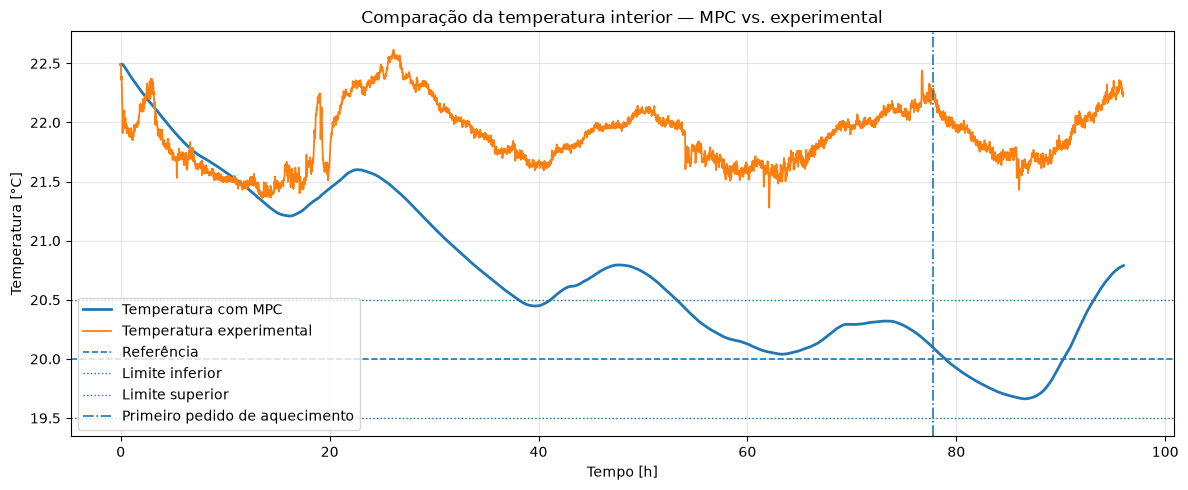

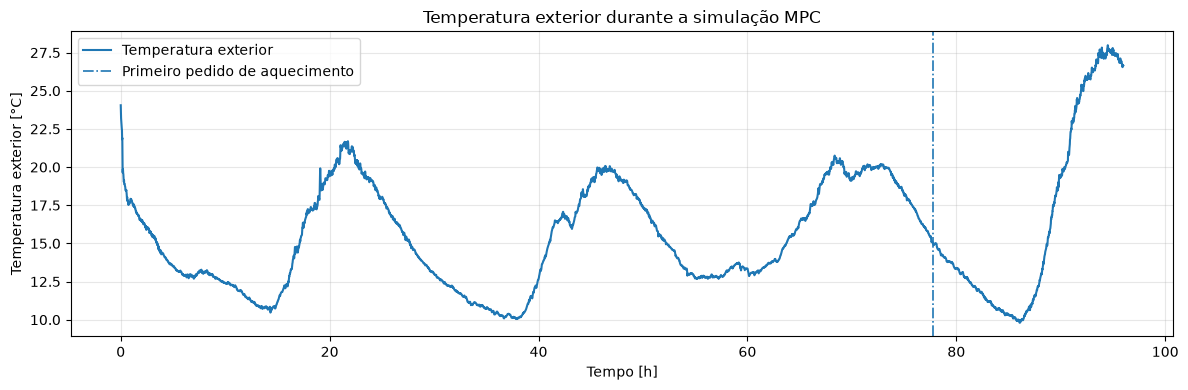

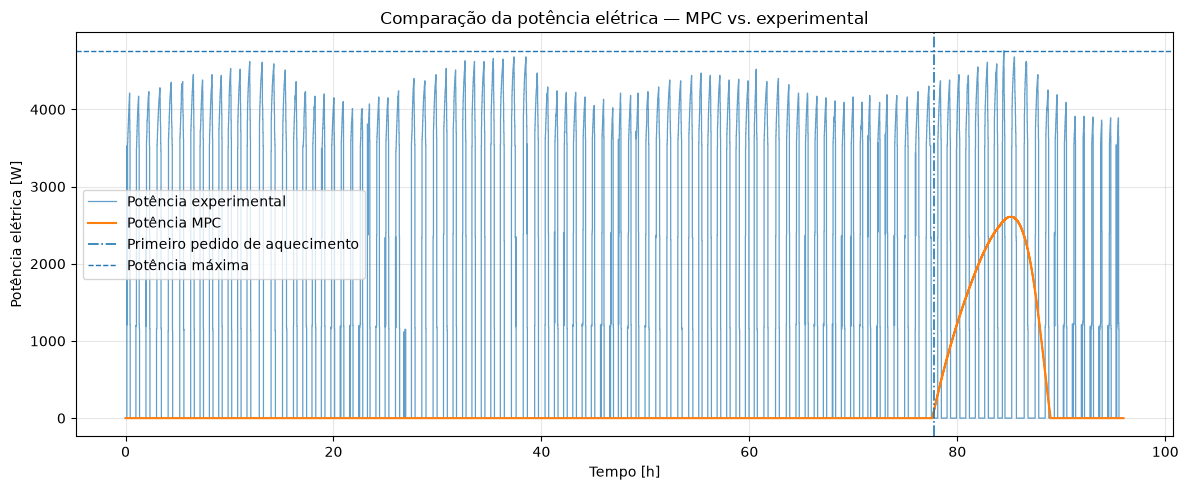

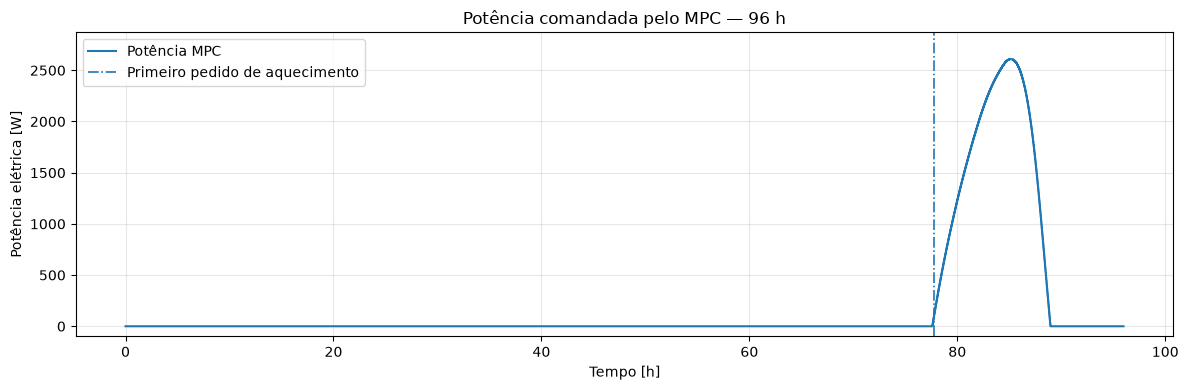

FIGURAS DA SIMULAÇÃO MPC — 96 H
Figura guardada: MPC_96h_Temperatura_Comparacao.png
Figura guardada: MPC_96h_Temperatura_Exterior.png
Figura guardada: MPC_96h_Potencia_Comparacao.png
Figura guardada: MPC_96h_Potencia_MPC.png

Pasta de destino: C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras

Figuras da simulação MPC de 96 h geradas e guardadas com sucesso.


In [24]:
# ============================================================
# Célula 23 — Visualização da simulação MPC de 96 h
# ============================================================

# ------------------------------------------------------------
# Vetores temporais
# ------------------------------------------------------------

tempo_mpc_96h_h = (
    np.arange(
        temperatura_mpc_96h_c.size
    )
    * PERIODO_AMOSTRAGEM_S
    / 3600.0
)

tempo_controlo_96h_h = (
    np.arange(
        potencia_mpc_96h_w.size
    )
    * PERIODO_AMOSTRAGEM_S
    / 3600.0
)


# ------------------------------------------------------------
# Ajuste de dimensão da temperatura experimental
#
# A temperatura MPC contém o estado inicial e possui N + 1
# valores, enquanto a temperatura experimental possui N.
# ------------------------------------------------------------

tempo_experimental_96h_h = (
    np.arange(
        temperatura_interior_experimental_96h_c.size
    )
    * PERIODO_AMOSTRAGEM_S
    / 3600.0
)


# ------------------------------------------------------------
# Figura 1 — Temperatura MPC vs. experimental
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 5)
)

plt.plot(
    tempo_mpc_96h_h,
    temperatura_mpc_96h_c,
    linewidth=2.0,
    label="Temperatura com MPC",
)

plt.plot(
    tempo_experimental_96h_h,
    temperatura_interior_experimental_96h_c,
    linewidth=1.3,
    label="Temperatura experimental",
)

plt.axhline(
    configuracao_mpc.temperatura_referencia,
    linestyle="--",
    linewidth=1.2,
    label="Referência",
)

plt.axhline(
    configuracao_mpc.temperatura_minima,
    linestyle=":",
    linewidth=1.0,
    label="Limite inferior",
)

plt.axhline(
    configuracao_mpc.temperatura_maxima,
    linestyle=":",
    linewidth=1.0,
    label="Limite superior",
)

if indice_primeiro_aquecimento_96h is not None:

    plt.axvline(
        tempo_primeiro_aquecimento_96h_h,
        linestyle="-.",
        linewidth=1.2,
        label="Primeiro pedido de aquecimento",
    )

plt.xlabel(
    "Tempo [h]"
)

plt.ylabel(
    "Temperatura [°C]"
)

plt.title(
    "Comparação da temperatura interior — MPC vs. experimental"
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    loc="best"
)

plt.tight_layout()

caminho_figura_temperatura_96h = (
    PASTA_FIGURAS
    / "MPC_96h_Temperatura_Comparacao.png"
)

plt.savefig(
    caminho_figura_temperatura_96h,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figura 2 — Temperatura exterior
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 4)
)

plt.plot(
    tempo_experimental_96h_h,
    temperatura_exterior_experimental_96h_c,
    linewidth=1.5,
    label="Temperatura exterior",
)

if indice_primeiro_aquecimento_96h is not None:

    plt.axvline(
        tempo_primeiro_aquecimento_96h_h,
        linestyle="-.",
        linewidth=1.2,
        label="Primeiro pedido de aquecimento",
    )

plt.xlabel(
    "Tempo [h]"
)

plt.ylabel(
    "Temperatura exterior [°C]"
)

plt.title(
    "Temperatura exterior durante a simulação MPC"
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    loc="best"
)

plt.tight_layout()

caminho_figura_temperatura_exterior_96h = (
    PASTA_FIGURAS
    / "MPC_96h_Temperatura_Exterior.png"
)

plt.savefig(
    caminho_figura_temperatura_exterior_96h,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figura 3 — Potência MPC vs. experimental
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 5)
)

plt.step(
    tempo_controlo_96h_h,
    potencia_experimental_96h_w,
    where="post",
    linewidth=0.9,
    alpha=0.7,
    label="Potência experimental",
)

plt.step(
    tempo_controlo_96h_h,
    potencia_mpc_96h_w,
    where="post",
    linewidth=1.5,
    label="Potência MPC",
)

if indice_primeiro_aquecimento_96h is not None:

    plt.axvline(
        tempo_primeiro_aquecimento_96h_h,
        linestyle="-.",
        linewidth=1.2,
        label="Primeiro pedido de aquecimento",
    )

plt.axhline(
    configuracao_mpc.potencia_maxima_w,
    linestyle="--",
    linewidth=1.0,
    label="Potência máxima",
)

plt.xlabel(
    "Tempo [h]"
)

plt.ylabel(
    "Potência elétrica [W]"
)

plt.title(
    "Comparação da potência elétrica — MPC vs. experimental"
)

plt.ylim(
    -0.05
    * configuracao_mpc.potencia_maxima_w,
    1.05
    * configuracao_mpc.potencia_maxima_w,
)

plt.ticklabel_format(
    axis="y",
    style="plain",
    useOffset=False,
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    loc="best"
)

plt.tight_layout()

caminho_figura_potencia_96h = (
    PASTA_FIGURAS
    / "MPC_96h_Potencia_Comparacao.png"
)

plt.savefig(
    caminho_figura_potencia_96h,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figura 4 — Potência MPC isolada
#
# Esta figura permite analisar melhor a forma da ação de
# controlo, que pode ficar pouco visível quando representada
# juntamente com a potência experimental.
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 4)
)

plt.step(
    tempo_controlo_96h_h,
    potencia_mpc_96h_w,
    where="post",
    linewidth=1.5,
    label="Potência MPC",
)

if indice_primeiro_aquecimento_96h is not None:

    plt.axvline(
        tempo_primeiro_aquecimento_96h_h,
        linestyle="-.",
        linewidth=1.2,
        label="Primeiro pedido de aquecimento",
    )

plt.xlabel(
    "Tempo [h]"
)

plt.ylabel(
    "Potência elétrica [W]"
)

plt.title(
    "Potência comandada pelo MPC — 96 h"
)

plt.ylim(
    -100.0,
    max(
        500.0,
        1.10
        * potencia_mpc_96h_w.max(),
    ),
)

plt.ticklabel_format(
    axis="y",
    style="plain",
    useOffset=False,
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    loc="best"
)

plt.tight_layout()

caminho_figura_potencia_mpc_96h = (
    PASTA_FIGURAS
    / "MPC_96h_Potencia_MPC.png"
)

plt.savefig(
    caminho_figura_potencia_mpc_96h,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Validação da exportação
# ------------------------------------------------------------

figuras_mpc_96h = (
    caminho_figura_temperatura_96h,
    caminho_figura_temperatura_exterior_96h,
    caminho_figura_potencia_96h,
    caminho_figura_potencia_mpc_96h,
)

print("=" * 80)
print("FIGURAS DA SIMULAÇÃO MPC — 96 H")
print("=" * 80)

for caminho_figura in figuras_mpc_96h:

    if not caminho_figura.is_file():

        raise FileNotFoundError(
            "A figura não foi corretamente guardada:\n"
            f"{caminho_figura}"
        )

    print(
        f"Figura guardada: "
        f"{caminho_figura.name}"
    )

print()

print(
    f"Pasta de destino: "
    f"{PASTA_FIGURAS}"
)

print()

print(
    "Figuras da simulação MPC de 96 h "
    "geradas e guardadas com sucesso."
)

print("=" * 80)

In [25]:
# ============================================================
# Célula 24 — Análise de sensibilidade ao peso da
# temperatura q_T
# ============================================================

# ------------------------------------------------------------
# Janela crítica da simulação
#
# São analisadas as últimas 24 h da simulação anterior:
#
# 72 h -> 96 h
#
# Esta região contém o primeiro pedido de aquecimento e
# concentra a atuação efetiva do controlador.
# ------------------------------------------------------------

INICIO_JANELA_SENSIBILIDADE_H = 72
DURACAO_JANELA_SENSIBILIDADE_H = 24

indice_inicio_sensibilidade = int(
    INICIO_JANELA_SENSIBILIDADE_H
    * 3600
    / PERIODO_AMOSTRAGEM_S
)

numero_passos_sensibilidade = int(
    DURACAO_JANELA_SENSIBILIDADE_H
    * 3600
    / PERIODO_AMOSTRAGEM_S
)

indice_fim_sensibilidade = (
    indice_inicio_sensibilidade
    + numero_passos_sensibilidade
)


# ------------------------------------------------------------
# Estado inicial da janela
#
# Utiliza-se diretamente o estado calculado na simulação
# MPC de 96 h, preservando T_int e T_m.
# ------------------------------------------------------------

estado_inicial_sensibilidade = (
    resultado_mpc_96h
    .estados[
        indice_inicio_sensibilidade
    ]
    .copy()
)


# ------------------------------------------------------------
# Potência imediatamente anterior ao início da janela
# ------------------------------------------------------------

if indice_inicio_sensibilidade > 0:

    potencia_anterior_sensibilidade_w = float(
        potencia_mpc_96h_w[
            indice_inicio_sensibilidade - 1
        ]
    )

else:

    potencia_anterior_sensibilidade_w = (
        potencia_anterior_mpc_96h_w
    )


# ------------------------------------------------------------
# Temperatura exterior da janela crítica
# ------------------------------------------------------------

temperatura_exterior_sensibilidade_c = (
    temperatura_exterior_experimental_96h_c[
        indice_inicio_sensibilidade:
        indice_fim_sensibilidade
    ]
    .copy()
)


# ------------------------------------------------------------
# Valores de q_T a analisar
# ------------------------------------------------------------

VALORES_Q_T = (
    0.5,
    1.0,
    2.0,
    5.0,
    10.0,
)


# ------------------------------------------------------------
# Armazenamento dos resultados
# ------------------------------------------------------------

resultados_sensibilidade_qT = {}

linhas_sensibilidade_qT = []


# ------------------------------------------------------------
# Execução das diferentes configurações
# ------------------------------------------------------------

for valor_q_T in VALORES_Q_T:

    configuracao_teste = replace(
        configuracao_mpc,
        peso_temperatura=float(
            valor_q_T
        ),
    )

    validar_configuracao_mpc(
        configuracao_teste
    )

    resultado_teste = (
        simular_mpc_horizonte_deslizante(
            matrizes=(
                matrizes_discretas_2r2c_selecionadas
            ),
            estado_inicial=(
                estado_inicial_sensibilidade
            ),
            temperatura_exterior_c=(
                temperatura_exterior_sensibilidade_c
            ),
            configuracao=(
                configuracao_teste
            ),
            temperatura_referencia=(
                configuracao_teste
                .temperatura_referencia
            ),
            potencia_inicial_w=(
                potencia_anterior_sensibilidade_w
            ),
            numero_passos=(
                numero_passos_sensibilidade
            ),
            maximo_iteracoes=300,
            utilizar_warm_start=True,
            interromper_em_falha=True,
        )
    )

    validar_resultado_simulacao_mpc(
        resultado=resultado_teste,
        configuracao=configuracao_teste,
    )

    resultados_sensibilidade_qT[
        valor_q_T
    ] = resultado_teste


    # --------------------------------------------------------
    # Extração dos sinais
    # --------------------------------------------------------

    temperatura_teste_c = (
        resultado_teste
        .temperatura_interior_c[1:]
    )

    potencia_teste_w = (
        resultado_teste
        .potencia_aplicada_w
    )


    # --------------------------------------------------------
    # Energia
    # --------------------------------------------------------

    energia_teste_kwh = (
        np.sum(
            potencia_teste_w
        )
        * PERIODO_AMOSTRAGEM_S
        / 3.6e6
    )


    # --------------------------------------------------------
    # Erros relativamente à referência
    # --------------------------------------------------------

    erro_temperatura_c = (
        temperatura_teste_c
        - configuracao_teste
        .temperatura_referencia
    )

    rmse_temperatura_c = float(
        np.sqrt(
            np.mean(
                erro_temperatura_c ** 2
            )
        )
    )

    mae_temperatura_c = float(
        np.mean(
            np.abs(
                erro_temperatura_c
            )
        )
    )


    # --------------------------------------------------------
    # Conforto
    # --------------------------------------------------------

    dentro_banda = (
        (
            temperatura_teste_c
            >= configuracao_teste
            .temperatura_minima
        )
        & (
            temperatura_teste_c
            <= configuracao_teste
            .temperatura_maxima
        )
    )

    abaixo_banda = (
        temperatura_teste_c
        < configuracao_teste
        .temperatura_minima
    )

    acima_banda = (
        temperatura_teste_c
        > configuracao_teste
        .temperatura_maxima
    )

    percentagem_dentro_banda = (
        100.0
        * np.mean(
            dentro_banda
        )
    )

    percentagem_abaixo_banda = (
        100.0
        * np.mean(
            abaixo_banda
        )
    )

    percentagem_acima_banda = (
        100.0
        * np.mean(
            acima_banda
        )
    )


    # --------------------------------------------------------
    # Variação da potência
    # --------------------------------------------------------

    variacoes_potencia_w = np.diff(
        np.concatenate(
            (
                np.array(
                    [
                        potencia_anterior_sensibilidade_w
                    ],
                    dtype=float,
                ),
                potencia_teste_w,
            )
        )
    )

    variacao_media_absoluta_w = float(
        np.mean(
            np.abs(
                variacoes_potencia_w
            )
        )
    )

    variacao_maxima_absoluta_w = float(
        np.max(
            np.abs(
                variacoes_potencia_w
            )
        )
    )


    # --------------------------------------------------------
    # Armazenamento dos indicadores
    # --------------------------------------------------------

    linhas_sensibilidade_qT.append(
        {
            "q_T":
                valor_q_T,

            "T_min_C":
                temperatura_teste_c.min(),

            "T_final_C":
                temperatura_teste_c[-1],

            "RMSE_ref_C":
                rmse_temperatura_c,

            "MAE_ref_C":
                mae_temperatura_c,

            "Dentro_banda_%":
                percentagem_dentro_banda,

            "Abaixo_banda_%":
                percentagem_abaixo_banda,

            "Acima_banda_%":
                percentagem_acima_banda,

            "P_media_W":
                potencia_teste_w.mean(),

            "P_max_W":
                potencia_teste_w.max(),

            "Energia_kWh":
                energia_teste_kwh,

            "DeltaP_medio_W":
                variacao_media_absoluta_w,

            "DeltaP_max_W":
                variacao_maxima_absoluta_w,

            "Iteracoes_medias":
                resultado_teste
                .numero_iteracoes
                .mean(),

            "Tempo_medio_s":
                resultado_teste
                .tempo_otimizacao_medio_s,

            "Convergencia_%":
                resultado_teste
                .taxa_convergencia_percentagem,
        }
    )


# ------------------------------------------------------------
# Construção da tabela de sensibilidade
# ------------------------------------------------------------

tabela_sensibilidade_qT = pd.DataFrame(
    linhas_sensibilidade_qT
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 120)
print(
    "ANÁLISE DE SENSIBILIDADE DO MPC "
    "AO PESO DA TEMPERATURA q_T"
)
print("=" * 120)

print(
    f"Janela analisada: "
    f"{INICIO_JANELA_SENSIBILIDADE_H}–"
    f"{INICIO_JANELA_SENSIBILIDADE_H + DURACAO_JANELA_SENSIBILIDADE_H} h"
)

print(
    f"Estado inicial da janela: "
    f"T_int = {estado_inicial_sensibilidade[0]:.3f} °C, "
    f"T_m = {estado_inicial_sensibilidade[1]:.3f} °C"
)

print(
    f"Potência anterior = "
    f"{potencia_anterior_sensibilidade_w:.2f} W"
)

print()

print(
    tabela_sensibilidade_qT.to_string(
        index=False,
        formatters={
            "q_T":
                "{:.2f}".format,

            "T_min_C":
                "{:.3f}".format,

            "T_final_C":
                "{:.3f}".format,

            "RMSE_ref_C":
                "{:.3f}".format,

            "MAE_ref_C":
                "{:.3f}".format,

            "Dentro_banda_%":
                "{:.2f}".format,

            "Abaixo_banda_%":
                "{:.2f}".format,

            "Acima_banda_%":
                "{:.2f}".format,

            "P_media_W":
                "{:.2f}".format,

            "P_max_W":
                "{:.2f}".format,

            "Energia_kWh":
                "{:.3f}".format,

            "DeltaP_medio_W":
                "{:.2f}".format,

            "DeltaP_max_W":
                "{:.2f}".format,

            "Iteracoes_medias":
                "{:.2f}".format,

            "Tempo_medio_s":
                "{:.4f}".format,

            "Convergencia_%":
                "{:.2f}".format,
        },
    )
)

print()

todas_configuracoes_convergiram = bool(
    np.allclose(
        tabela_sensibilidade_qT[
            "Convergencia_%"
        ],
        100.0,
        atol=1.0e-9,
    )
)

print(
    f"Todas as configurações apresentaram "
    f"100 % de convergência: "
    f"{todas_configuracoes_convergiram}"
)

print()

print(
    "Análise de sensibilidade a q_T "
    "concluída com sucesso."
)

print("=" * 120)

ANÁLISE DE SENSIBILIDADE DO MPC AO PESO DA TEMPERATURA q_T
Janela analisada: 72–96 h
Estado inicial da janela: T_int = 20.311 °C, T_m = 20.358 °C
Potência anterior = 0.00 W

  q_T T_min_C T_final_C RMSE_ref_C MAE_ref_C Dentro_banda_% Abaixo_banda_% Acima_banda_% P_media_W P_max_W Energia_kWh DeltaP_medio_W DeltaP_max_W Iteracoes_medias Tempo_medio_s Convergencia_%
 0.50  19.553    20.654      0.320     0.281          92.29           0.00          7.71    528.07 1714.87      12.674           2.38        11.14             2.37        0.0491         100.00
 1.00  19.663    20.789      0.329     0.275          88.19           0.00         11.81    788.02 2609.90      18.912           3.62        19.54             2.54        0.0500         100.00
 2.00  19.788    20.912      0.353     0.271          84.86           0.00         15.14   1026.32 3393.57      24.632           4.71        34.45             2.85        0.0529         100.00
 5.00  19.908    20.998      0.378     0.261          

In [26]:
# ============================================================
# Célula 25 — Análise de sensibilidade ao peso da
# potência q_P
# ============================================================

# ------------------------------------------------------------
# Valor de q_T selecionado para esta fase
# ------------------------------------------------------------

Q_T_REFERENCIA = 0.5


# ------------------------------------------------------------
# Valores de q_P a analisar
# ------------------------------------------------------------

VALORES_Q_P = (
    0.01,
    0.025,
    0.05,
    0.10,
    0.20,
)


# ------------------------------------------------------------
# Armazenamento dos resultados
# ------------------------------------------------------------

resultados_sensibilidade_qP = {}

linhas_sensibilidade_qP = []


# ------------------------------------------------------------
# Execução das diferentes configurações
# ------------------------------------------------------------

for valor_q_P in VALORES_Q_P:

    configuracao_teste = replace(
        configuracao_mpc,
        peso_temperatura=Q_T_REFERENCIA,
        peso_potencia=float(
            valor_q_P
        ),
    )

    validar_configuracao_mpc(
        configuracao_teste
    )

    resultado_teste = (
        simular_mpc_horizonte_deslizante(
            matrizes=(
                matrizes_discretas_2r2c_selecionadas
            ),
            estado_inicial=(
                estado_inicial_sensibilidade
            ),
            temperatura_exterior_c=(
                temperatura_exterior_sensibilidade_c
            ),
            configuracao=(
                configuracao_teste
            ),
            temperatura_referencia=(
                configuracao_teste
                .temperatura_referencia
            ),
            potencia_inicial_w=(
                potencia_anterior_sensibilidade_w
            ),
            numero_passos=(
                numero_passos_sensibilidade
            ),
            maximo_iteracoes=300,
            utilizar_warm_start=True,
            interromper_em_falha=True,
        )
    )

    validar_resultado_simulacao_mpc(
        resultado=resultado_teste,
        configuracao=configuracao_teste,
    )

    resultados_sensibilidade_qP[
        valor_q_P
    ] = resultado_teste


    # --------------------------------------------------------
    # Extração dos sinais
    # --------------------------------------------------------

    temperatura_teste_c = (
        resultado_teste
        .temperatura_interior_c[1:]
    )

    potencia_teste_w = (
        resultado_teste
        .potencia_aplicada_w
    )


    # --------------------------------------------------------
    # Energia
    # --------------------------------------------------------

    energia_teste_kwh = (
        np.sum(
            potencia_teste_w
        )
        * PERIODO_AMOSTRAGEM_S
        / 3.6e6
    )


    # --------------------------------------------------------
    # Erros relativamente à referência
    # --------------------------------------------------------

    erro_temperatura_c = (
        temperatura_teste_c
        - configuracao_teste
        .temperatura_referencia
    )

    rmse_temperatura_c = float(
        np.sqrt(
            np.mean(
                erro_temperatura_c ** 2
            )
        )
    )

    mae_temperatura_c = float(
        np.mean(
            np.abs(
                erro_temperatura_c
            )
        )
    )


    # --------------------------------------------------------
    # Banda térmica
    # --------------------------------------------------------

    dentro_banda = (
        (
            temperatura_teste_c
            >= configuracao_teste
            .temperatura_minima
        )
        & (
            temperatura_teste_c
            <= configuracao_teste
            .temperatura_maxima
        )
    )

    abaixo_banda = (
        temperatura_teste_c
        < configuracao_teste
        .temperatura_minima
    )

    acima_banda = (
        temperatura_teste_c
        > configuracao_teste
        .temperatura_maxima
    )

    percentagem_dentro_banda = (
        100.0
        * np.mean(
            dentro_banda
        )
    )

    percentagem_abaixo_banda = (
        100.0
        * np.mean(
            abaixo_banda
        )
    )

    percentagem_acima_banda = (
        100.0
        * np.mean(
            acima_banda
        )
    )


    # --------------------------------------------------------
    # Variação da potência
    # --------------------------------------------------------

    variacoes_potencia_w = np.diff(
        np.concatenate(
            (
                np.array(
                    [
                        potencia_anterior_sensibilidade_w
                    ],
                    dtype=float,
                ),
                potencia_teste_w,
            )
        )
    )

    variacao_media_absoluta_w = float(
        np.mean(
            np.abs(
                variacoes_potencia_w
            )
        )
    )

    variacao_maxima_absoluta_w = float(
        np.max(
            np.abs(
                variacoes_potencia_w
            )
        )
    )


    # --------------------------------------------------------
    # Armazenamento dos indicadores
    # --------------------------------------------------------

    linhas_sensibilidade_qP.append(
        {
            "q_P":
                valor_q_P,

            "T_min_C":
                temperatura_teste_c.min(),

            "T_final_C":
                temperatura_teste_c[-1],

            "RMSE_ref_C":
                rmse_temperatura_c,

            "MAE_ref_C":
                mae_temperatura_c,

            "Dentro_banda_%":
                percentagem_dentro_banda,

            "Abaixo_banda_%":
                percentagem_abaixo_banda,

            "Acima_banda_%":
                percentagem_acima_banda,

            "P_media_W":
                potencia_teste_w.mean(),

            "P_max_W":
                potencia_teste_w.max(),

            "Energia_kWh":
                energia_teste_kwh,

            "DeltaP_medio_W":
                variacao_media_absoluta_w,

            "DeltaP_max_W":
                variacao_maxima_absoluta_w,

            "Iteracoes_medias":
                resultado_teste
                .numero_iteracoes
                .mean(),

            "Tempo_medio_s":
                resultado_teste
                .tempo_otimizacao_medio_s,

            "Convergencia_%":
                resultado_teste
                .taxa_convergencia_percentagem,
        }
    )


# ------------------------------------------------------------
# Construção da tabela
# ------------------------------------------------------------

tabela_sensibilidade_qP = pd.DataFrame(
    linhas_sensibilidade_qP
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 120)
print(
    "ANÁLISE DE SENSIBILIDADE DO MPC "
    "AO PESO DA POTÊNCIA q_P"
)
print("=" * 120)

print(
    f"q_T fixado em: "
    f"{Q_T_REFERENCIA:.2f}"
)

print(
    f"Janela analisada: "
    f"{INICIO_JANELA_SENSIBILIDADE_H}–"
    f"{INICIO_JANELA_SENSIBILIDADE_H + DURACAO_JANELA_SENSIBILIDADE_H} h"
)

print(
    f"Estado inicial da janela: "
    f"T_int = {estado_inicial_sensibilidade[0]:.3f} °C, "
    f"T_m = {estado_inicial_sensibilidade[1]:.3f} °C"
)

print()

print(
    tabela_sensibilidade_qP.to_string(
        index=False,
        formatters={
            "q_P":
                "{:.3f}".format,

            "T_min_C":
                "{:.3f}".format,

            "T_final_C":
                "{:.3f}".format,

            "RMSE_ref_C":
                "{:.3f}".format,

            "MAE_ref_C":
                "{:.3f}".format,

            "Dentro_banda_%":
                "{:.2f}".format,

            "Abaixo_banda_%":
                "{:.2f}".format,

            "Acima_banda_%":
                "{:.2f}".format,

            "P_media_W":
                "{:.2f}".format,

            "P_max_W":
                "{:.2f}".format,

            "Energia_kWh":
                "{:.3f}".format,

            "DeltaP_medio_W":
                "{:.2f}".format,

            "DeltaP_max_W":
                "{:.2f}".format,

            "Iteracoes_medias":
                "{:.2f}".format,

            "Tempo_medio_s":
                "{:.4f}".format,

            "Convergencia_%":
                "{:.2f}".format,
        },
    )
)

print()

todas_configuracoes_qP_convergiram = bool(
    np.allclose(
        tabela_sensibilidade_qP[
            "Convergencia_%"
        ],
        100.0,
        atol=1.0e-9,
    )
)

print(
    f"Todas as configurações apresentaram "
    f"100 % de convergência: "
    f"{todas_configuracoes_qP_convergiram}"
)

print()

print(
    "Análise de sensibilidade a q_P "
    "concluída com sucesso."
)

print("=" * 120)

ANÁLISE DE SENSIBILIDADE DO MPC AO PESO DA POTÊNCIA q_P
q_T fixado em: 0.50
Janela analisada: 72–96 h
Estado inicial da janela: T_int = 20.311 °C, T_m = 20.358 °C

  q_P T_min_C T_final_C RMSE_ref_C MAE_ref_C Dentro_banda_% Abaixo_banda_% Acima_banda_% P_media_W P_max_W Energia_kWh DeltaP_medio_W DeltaP_max_W Iteracoes_medias Tempo_medio_s Convergencia_%
0.010  19.814    20.933      0.358     0.270          84.38           0.00         15.62   1067.09 3512.56      25.610           4.88        36.02             3.53        0.0660         100.00
0.025  19.660    20.785      0.329     0.275          88.26           0.00         11.74    780.22 2583.20      18.725           3.59        19.32             2.49        0.0494         100.00
0.050  19.553    20.654      0.320     0.281          92.29           0.00          7.71    528.07 1714.87      12.674           2.38        11.14             2.37        0.0520         100.00
0.100  19.497    20.574      0.324     0.287          92.22     

In [27]:
# ============================================================
# Célula 26 — Análise de sensibilidade ao peso da
# variação de potência q_delta_P
# ============================================================

# ------------------------------------------------------------
# Valores de referência já selecionados
# ------------------------------------------------------------

Q_T_REFERENCIA = 0.5
Q_P_REFERENCIA = 0.05


# ------------------------------------------------------------
# Valores de q_delta_P a analisar
# ------------------------------------------------------------

VALORES_Q_DELTA_P = (
    0.01,
    0.05,
    0.10,
    0.25,
    0.50,
)


# ------------------------------------------------------------
# Armazenamento dos resultados
# ------------------------------------------------------------

resultados_sensibilidade_qDeltaP = {}

linhas_sensibilidade_qDeltaP = []


# ------------------------------------------------------------
# Execução das diferentes configurações
# ------------------------------------------------------------

for valor_q_delta_P in VALORES_Q_DELTA_P:

    configuracao_teste = replace(
        configuracao_mpc,
        peso_temperatura=(
            Q_T_REFERENCIA
        ),
        peso_potencia=(
            Q_P_REFERENCIA
        ),
        peso_variacao_potencia=float(
            valor_q_delta_P
        ),
    )

    validar_configuracao_mpc(
        configuracao_teste
    )

    resultado_teste = (
        simular_mpc_horizonte_deslizante(
            matrizes=(
                matrizes_discretas_2r2c_selecionadas
            ),
            estado_inicial=(
                estado_inicial_sensibilidade
            ),
            temperatura_exterior_c=(
                temperatura_exterior_sensibilidade_c
            ),
            configuracao=(
                configuracao_teste
            ),
            temperatura_referencia=(
                configuracao_teste
                .temperatura_referencia
            ),
            potencia_inicial_w=(
                potencia_anterior_sensibilidade_w
            ),
            numero_passos=(
                numero_passos_sensibilidade
            ),
            maximo_iteracoes=300,
            utilizar_warm_start=True,
            interromper_em_falha=True,
        )
    )

    validar_resultado_simulacao_mpc(
        resultado=resultado_teste,
        configuracao=configuracao_teste,
    )

    resultados_sensibilidade_qDeltaP[
        valor_q_delta_P
    ] = resultado_teste


    # --------------------------------------------------------
    # Extração dos sinais
    # --------------------------------------------------------

    temperatura_teste_c = (
        resultado_teste
        .temperatura_interior_c[1:]
    )

    potencia_teste_w = (
        resultado_teste
        .potencia_aplicada_w
    )


    # --------------------------------------------------------
    # Energia
    # --------------------------------------------------------

    energia_teste_kwh = (
        np.sum(
            potencia_teste_w
        )
        * PERIODO_AMOSTRAGEM_S
        / 3.6e6
    )


    # --------------------------------------------------------
    # Erros relativamente à referência
    # --------------------------------------------------------

    erro_temperatura_c = (
        temperatura_teste_c
        - configuracao_teste
        .temperatura_referencia
    )

    rmse_temperatura_c = float(
        np.sqrt(
            np.mean(
                erro_temperatura_c ** 2
            )
        )
    )

    mae_temperatura_c = float(
        np.mean(
            np.abs(
                erro_temperatura_c
            )
        )
    )


    # --------------------------------------------------------
    # Banda térmica
    # --------------------------------------------------------

    dentro_banda = (
        (
            temperatura_teste_c
            >= configuracao_teste
            .temperatura_minima
        )
        & (
            temperatura_teste_c
            <= configuracao_teste
            .temperatura_maxima
        )
    )

    abaixo_banda = (
        temperatura_teste_c
        < configuracao_teste
        .temperatura_minima
    )

    acima_banda = (
        temperatura_teste_c
        > configuracao_teste
        .temperatura_maxima
    )

    percentagem_dentro_banda = (
        100.0
        * np.mean(
            dentro_banda
        )
    )

    percentagem_abaixo_banda = (
        100.0
        * np.mean(
            abaixo_banda
        )
    )

    percentagem_acima_banda = (
        100.0
        * np.mean(
            acima_banda
        )
    )


    # --------------------------------------------------------
    # Variações da potência
    # --------------------------------------------------------

    variacoes_potencia_w = np.diff(
        np.concatenate(
            (
                np.array(
                    [
                        potencia_anterior_sensibilidade_w
                    ],
                    dtype=float,
                ),
                potencia_teste_w,
            )
        )
    )

    variacao_media_absoluta_w = float(
        np.mean(
            np.abs(
                variacoes_potencia_w
            )
        )
    )

    variacao_mediana_absoluta_w = float(
        np.median(
            np.abs(
                variacoes_potencia_w
            )
        )
    )

    variacao_maxima_absoluta_w = float(
        np.max(
            np.abs(
                variacoes_potencia_w
            )
        )
    )


    # --------------------------------------------------------
    # Número de transições significativas
    #
    # Considera-se significativa uma alteração absoluta
    # superior a 100 W entre amostras consecutivas.
    # --------------------------------------------------------

    LIMIAR_TRANSICAO_SIGNIFICATIVA_W = 100.0

    numero_transicoes_significativas = int(
        np.sum(
            np.abs(
                variacoes_potencia_w
            )
            > LIMIAR_TRANSICAO_SIGNIFICATIVA_W
        )
    )


    # --------------------------------------------------------
    # Armazenamento dos indicadores
    # --------------------------------------------------------

    linhas_sensibilidade_qDeltaP.append(
        {
            "q_delta_P":
                valor_q_delta_P,

            "T_min_C":
                temperatura_teste_c.min(),

            "T_final_C":
                temperatura_teste_c[-1],

            "RMSE_ref_C":
                rmse_temperatura_c,

            "MAE_ref_C":
                mae_temperatura_c,

            "Dentro_banda_%":
                percentagem_dentro_banda,

            "Abaixo_banda_%":
                percentagem_abaixo_banda,

            "Acima_banda_%":
                percentagem_acima_banda,

            "P_media_W":
                potencia_teste_w.mean(),

            "P_max_W":
                potencia_teste_w.max(),

            "Energia_kWh":
                energia_teste_kwh,

            "DeltaP_medio_W":
                variacao_media_absoluta_w,

            "DeltaP_mediano_W":
                variacao_mediana_absoluta_w,

            "DeltaP_max_W":
                variacao_maxima_absoluta_w,

            "Transicoes_maiores_100W":
                numero_transicoes_significativas,

            "Iteracoes_medias":
                resultado_teste
                .numero_iteracoes
                .mean(),

            "Tempo_medio_s":
                resultado_teste
                .tempo_otimizacao_medio_s,

            "Convergencia_%":
                resultado_teste
                .taxa_convergencia_percentagem,
        }
    )


# ------------------------------------------------------------
# Construção da tabela
# ------------------------------------------------------------

tabela_sensibilidade_qDeltaP = pd.DataFrame(
    linhas_sensibilidade_qDeltaP
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 130)
print(
    "ANÁLISE DE SENSIBILIDADE DO MPC "
    "AO PESO DA VARIAÇÃO DE POTÊNCIA q_delta_P"
)
print("=" * 130)

print(
    f"q_T fixado em: "
    f"{Q_T_REFERENCIA:.2f}"
)

print(
    f"q_P fixado em: "
    f"{Q_P_REFERENCIA:.3f}"
)

print(
    f"Janela analisada: "
    f"{INICIO_JANELA_SENSIBILIDADE_H}–"
    f"{INICIO_JANELA_SENSIBILIDADE_H + DURACAO_JANELA_SENSIBILIDADE_H} h"
)

print()

print(
    tabela_sensibilidade_qDeltaP.to_string(
        index=False,
        formatters={
            "q_delta_P":
                "{:.2f}".format,

            "T_min_C":
                "{:.3f}".format,

            "T_final_C":
                "{:.3f}".format,

            "RMSE_ref_C":
                "{:.3f}".format,

            "MAE_ref_C":
                "{:.3f}".format,

            "Dentro_banda_%":
                "{:.2f}".format,

            "Abaixo_banda_%":
                "{:.2f}".format,

            "Acima_banda_%":
                "{:.2f}".format,

            "P_media_W":
                "{:.2f}".format,

            "P_max_W":
                "{:.2f}".format,

            "Energia_kWh":
                "{:.3f}".format,

            "DeltaP_medio_W":
                "{:.2f}".format,

            "DeltaP_mediano_W":
                "{:.2f}".format,

            "DeltaP_max_W":
                "{:.2f}".format,

            "Iteracoes_medias":
                "{:.2f}".format,

            "Tempo_medio_s":
                "{:.4f}".format,

            "Convergencia_%":
                "{:.2f}".format,
        },
    )
)

print()

todas_configuracoes_qDeltaP_convergiram = bool(
    np.allclose(
        tabela_sensibilidade_qDeltaP[
            "Convergencia_%"
        ],
        100.0,
        atol=1.0e-9,
    )
)

print(
    f"Todas as configurações apresentaram "
    f"100 % de convergência: "
    f"{todas_configuracoes_qDeltaP_convergiram}"
)

print()

print(
    "Análise de sensibilidade a q_delta_P "
    "concluída com sucesso."
)

print("=" * 130)

ANÁLISE DE SENSIBILIDADE DO MPC AO PESO DA VARIAÇÃO DE POTÊNCIA q_delta_P
q_T fixado em: 0.50
q_P fixado em: 0.050
Janela analisada: 72–96 h

q_delta_P T_min_C T_final_C RMSE_ref_C MAE_ref_C Dentro_banda_% Abaixo_banda_% Acima_banda_% P_media_W P_max_W Energia_kWh DeltaP_medio_W DeltaP_mediano_W DeltaP_max_W  Transicoes_maiores_100W Iteracoes_medias Tempo_medio_s Convergencia_%
     0.01  19.556    20.658      0.321     0.281          92.15           0.00          7.85    535.90 1741.55      12.862           2.42             0.27        11.46                        0             1.90        0.0410         100.00
     0.05  19.555    20.656      0.321     0.281          92.22           0.00          7.78    532.14 1728.77      12.771           2.40             0.34        11.33                        0             1.99        0.0420         100.00
     0.10  19.553    20.654      0.320     0.281          92.29           0.00          7.71    528.07 1714.87      12.674           2.38    

In [28]:
# ============================================================
# Célula 27 — Análise de sensibilidade ao peso da
# violação de conforto q_epsilon
# ============================================================

# ------------------------------------------------------------
# Pesos candidatos selecionados nas análises anteriores
# ------------------------------------------------------------

Q_T_REFERENCIA = 0.5
Q_P_REFERENCIA = 0.05
Q_DELTA_P_REFERENCIA = 0.10


# ------------------------------------------------------------
# Valores de q_epsilon a analisar
# ------------------------------------------------------------

VALORES_Q_EPSILON = (
    10.0,
    25.0,
    50.0,
    100.0,
    250.0,
    500.0,
)


# ------------------------------------------------------------
# Armazenamento dos resultados
# ------------------------------------------------------------

resultados_sensibilidade_qEpsilon = {}
linhas_sensibilidade_qEpsilon = []


# ------------------------------------------------------------
# Execução das diferentes configurações
# ------------------------------------------------------------

for valor_q_epsilon in VALORES_Q_EPSILON:

    configuracao_teste = replace(
        configuracao_mpc,
        peso_temperatura=Q_T_REFERENCIA,
        peso_potencia=Q_P_REFERENCIA,
        peso_variacao_potencia=Q_DELTA_P_REFERENCIA,
        peso_violacao_conforto=float(
            valor_q_epsilon
        ),
    )

    validar_configuracao_mpc(
        configuracao_teste
    )

    resultado_teste = (
        simular_mpc_horizonte_deslizante(
            matrizes=(
                matrizes_discretas_2r2c_selecionadas
            ),
            estado_inicial=(
                estado_inicial_sensibilidade
            ),
            temperatura_exterior_c=(
                temperatura_exterior_sensibilidade_c
            ),
            configuracao=(
                configuracao_teste
            ),
            temperatura_referencia=(
                configuracao_teste
                .temperatura_referencia
            ),
            potencia_inicial_w=(
                potencia_anterior_sensibilidade_w
            ),
            numero_passos=(
                numero_passos_sensibilidade
            ),
            maximo_iteracoes=300,
            utilizar_warm_start=True,
            interromper_em_falha=True,
        )
    )

    validar_resultado_simulacao_mpc(
        resultado=resultado_teste,
        configuracao=configuracao_teste,
    )

    resultados_sensibilidade_qEpsilon[
        valor_q_epsilon
    ] = resultado_teste


    # --------------------------------------------------------
    # Extração dos sinais
    # --------------------------------------------------------

    temperatura_teste_c = (
        resultado_teste
        .temperatura_interior_c[1:]
    )

    potencia_teste_w = (
        resultado_teste
        .potencia_aplicada_w
    )


    # --------------------------------------------------------
    # Energia
    # ------------------------------------------------------------

    energia_teste_kwh = (
        np.sum(
            potencia_teste_w
        )
        * PERIODO_AMOSTRAGEM_S
        / 3.6e6
    )


    # --------------------------------------------------------
    # Erro relativamente à referência
    # ------------------------------------------------------------

    erro_temperatura_c = (
        temperatura_teste_c
        - configuracao_teste
        .temperatura_referencia
    )

    rmse_temperatura_c = float(
        np.sqrt(
            np.mean(
                erro_temperatura_c ** 2
            )
        )
    )

    mae_temperatura_c = float(
        np.mean(
            np.abs(
                erro_temperatura_c
            )
        )
    )


    # --------------------------------------------------------
    # Condições de conforto
    # ------------------------------------------------------------

    dentro_banda = (
        (
            temperatura_teste_c
            >= configuracao_teste
            .temperatura_minima
        )
        & (
            temperatura_teste_c
            <= configuracao_teste
            .temperatura_maxima
        )
    )

    abaixo_banda = (
        temperatura_teste_c
        < configuracao_teste
        .temperatura_minima
    )

    acima_banda = (
        temperatura_teste_c
        > configuracao_teste
        .temperatura_maxima
    )

    percentagem_dentro_banda = (
        100.0 * np.mean(
            dentro_banda
        )
    )

    percentagem_abaixo_banda = (
        100.0 * np.mean(
            abaixo_banda
        )
    )

    percentagem_acima_banda = (
        100.0 * np.mean(
            acima_banda
        )
    )


    # --------------------------------------------------------
    # Magnitude das violações da banda
    # ------------------------------------------------------------

    violacao_inferior_c = np.maximum(
        configuracao_teste.temperatura_minima
        - temperatura_teste_c,
        0.0,
    )

    violacao_superior_c = np.maximum(
        temperatura_teste_c
        - configuracao_teste.temperatura_maxima,
        0.0,
    )

    violacao_maxima_inferior_c = float(
        np.max(
            violacao_inferior_c
        )
    )

    violacao_maxima_superior_c = float(
        np.max(
            violacao_superior_c
        )
    )


    # --------------------------------------------------------
    # Variação da potência
    # ------------------------------------------------------------

    variacoes_potencia_w = np.diff(
        np.concatenate(
            (
                np.array(
                    [
                        potencia_anterior_sensibilidade_w
                    ],
                    dtype=float,
                ),
                potencia_teste_w,
            )
        )
    )

    variacao_media_absoluta_w = float(
        np.mean(
            np.abs(
                variacoes_potencia_w
            )
        )
    )


    # --------------------------------------------------------
    # Armazenamento dos indicadores
    # ------------------------------------------------------------

    linhas_sensibilidade_qEpsilon.append(
        {
            "q_epsilon":
                valor_q_epsilon,

            "T_min_C":
                temperatura_teste_c.min(),

            "T_final_C":
                temperatura_teste_c[-1],

            "RMSE_ref_C":
                rmse_temperatura_c,

            "MAE_ref_C":
                mae_temperatura_c,

            "Dentro_banda_%":
                percentagem_dentro_banda,

            "Abaixo_banda_%":
                percentagem_abaixo_banda,

            "Acima_banda_%":
                percentagem_acima_banda,

            "Violacao_inf_max_C":
                violacao_maxima_inferior_c,

            "Violacao_sup_max_C":
                violacao_maxima_superior_c,

            "P_media_W":
                potencia_teste_w.mean(),

            "P_max_W":
                potencia_teste_w.max(),

            "Energia_kWh":
                energia_teste_kwh,

            "DeltaP_medio_W":
                variacao_media_absoluta_w,

            "Iteracoes_medias":
                resultado_teste
                .numero_iteracoes
                .mean(),

            "Tempo_medio_s":
                resultado_teste
                .tempo_otimizacao_medio_s,

            "Convergencia_%":
                resultado_teste
                .taxa_convergencia_percentagem,
        }
    )


# ------------------------------------------------------------
# Construção da tabela
# ------------------------------------------------------------

tabela_sensibilidade_qEpsilon = pd.DataFrame(
    linhas_sensibilidade_qEpsilon
)


# ------------------------------------------------------------
# Apresentação dos resultados
# ------------------------------------------------------------

print("=" * 135)

print(
    "ANÁLISE DE SENSIBILIDADE DO MPC "
    "AO PESO DA VIOLAÇÃO DE CONFORTO q_epsilon"
)

print("=" * 135)

print(
    f"q_T fixado em: "
    f"{Q_T_REFERENCIA:.2f}"
)

print(
    f"q_P fixado em: "
    f"{Q_P_REFERENCIA:.3f}"
)

print(
    f"q_delta_P fixado em: "
    f"{Q_DELTA_P_REFERENCIA:.2f}"
)

print(
    f"Janela analisada: "
    f"{INICIO_JANELA_SENSIBILIDADE_H}–"
    f"{INICIO_JANELA_SENSIBILIDADE_H + DURACAO_JANELA_SENSIBILIDADE_H} h"
)

print()

print(
    tabela_sensibilidade_qEpsilon.to_string(
        index=False,
        formatters={
            "q_epsilon":
                "{:.1f}".format,

            "T_min_C":
                "{:.3f}".format,

            "T_final_C":
                "{:.3f}".format,

            "RMSE_ref_C":
                "{:.3f}".format,

            "MAE_ref_C":
                "{:.3f}".format,

            "Dentro_banda_%":
                "{:.2f}".format,

            "Abaixo_banda_%":
                "{:.2f}".format,

            "Acima_banda_%":
                "{:.2f}".format,

            "Violacao_inf_max_C":
                "{:.4f}".format,

            "Violacao_sup_max_C":
                "{:.4f}".format,

            "P_media_W":
                "{:.2f}".format,

            "P_max_W":
                "{:.2f}".format,

            "Energia_kWh":
                "{:.3f}".format,

            "DeltaP_medio_W":
                "{:.2f}".format,

            "Iteracoes_medias":
                "{:.2f}".format,

            "Tempo_medio_s":
                "{:.4f}".format,

            "Convergencia_%":
                "{:.2f}".format,
        },
    )
)

print()

todas_configuracoes_qEpsilon_convergiram = bool(
    np.allclose(
        tabela_sensibilidade_qEpsilon[
            "Convergencia_%"
        ],
        100.0,
        atol=1.0e-9,
    )
)

print(
    "Todas as configurações apresentaram "
    "100 % de convergência: "
    f"{todas_configuracoes_qEpsilon_convergiram}"
)

print()

print(
    "Análise de sensibilidade a q_epsilon "
    "concluída com sucesso."
)

print("=" * 135)

ANÁLISE DE SENSIBILIDADE DO MPC AO PESO DA VIOLAÇÃO DE CONFORTO q_epsilon
q_T fixado em: 0.50
q_P fixado em: 0.050
q_delta_P fixado em: 0.10
Janela analisada: 72–96 h

q_epsilon T_min_C T_final_C RMSE_ref_C MAE_ref_C Dentro_banda_% Abaixo_banda_% Acima_banda_% Violacao_inf_max_C Violacao_sup_max_C P_media_W P_max_W Energia_kWh DeltaP_medio_W Iteracoes_medias Tempo_medio_s Convergencia_%
     10.0  19.553    20.654      0.320     0.281          92.29           0.00          7.71             0.0000             0.1540    528.07 1714.87      12.674           2.38             2.37        0.0473         100.00
     25.0  19.553    20.654      0.320     0.281          92.29           0.00          7.71             0.0000             0.1540    528.07 1714.87      12.674           2.38             2.37        0.0473         100.00
     50.0  19.553    20.654      0.320     0.281          92.29           0.00          7.71             0.0000             0.1540    528.07 1714.87      12.674      

In [29]:
# ============================================================
# Célula 28 — Configuração final do controlador MPC
# ============================================================

# ------------------------------------------------------------
# Pesos finais selecionados
# ------------------------------------------------------------

Q_T_FINAL = 0.50
Q_P_FINAL = 0.05
Q_DELTA_P_FINAL = 0.10
Q_EPSILON_FINAL = 100.0


# ------------------------------------------------------------
# Construção da configuração final
# ------------------------------------------------------------

configuracao_mpc_final = replace(
    configuracao_mpc,
    peso_temperatura=Q_T_FINAL,
    peso_potencia=Q_P_FINAL,
    peso_variacao_potencia=Q_DELTA_P_FINAL,
    peso_violacao_conforto=Q_EPSILON_FINAL,
)


# ------------------------------------------------------------
# Validação
# ------------------------------------------------------------

validar_configuracao_mpc(
    configuracao_mpc_final
)


# ------------------------------------------------------------
# Verificação explícita
# ------------------------------------------------------------

configuracao_final_valida = (
    configuracao_mpc_final.horizonte_predicao == 120
    and configuracao_mpc_final.horizonte_controlo == 12
    and configuracao_mpc_final.temperatura_referencia == 20.0
    and configuracao_mpc_final.temperatura_minima == 19.5
    and configuracao_mpc_final.temperatura_maxima == 20.5
    and configuracao_mpc_final.potencia_minima_w == 0.0
    and configuracao_mpc_final.potencia_maxima_w == 4760.0
    and configuracao_mpc_final.peso_temperatura == Q_T_FINAL
    and configuracao_mpc_final.peso_potencia == Q_P_FINAL
    and configuracao_mpc_final.peso_variacao_potencia
        == Q_DELTA_P_FINAL
    and configuracao_mpc_final.peso_violacao_conforto
        == Q_EPSILON_FINAL
)


if not configuracao_final_valida:

    raise RuntimeError(
        "A configuração final do MPC não foi "
        "validada corretamente."
    )


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 75)
print("CONFIGURAÇÃO FINAL DO CONTROLADOR MPC")
print("=" * 75)

print(
    f"Período de amostragem: "
    f"{PERIODO_AMOSTRAGEM_S:.0f} s"
)

print(
    f"Horizonte de predição (Np): "
    f"{configuracao_mpc_final.horizonte_predicao}"
)

print(
    f"Horizonte de controlo (Nc): "
    f"{configuracao_mpc_final.horizonte_controlo}"
)

print()

print("Referência e banda térmica:")

print(
    f"T_ref = "
    f"{configuracao_mpc_final.temperatura_referencia:.2f} °C"
)

print(
    f"T_min = "
    f"{configuracao_mpc_final.temperatura_minima:.2f} °C"
)

print(
    f"T_max = "
    f"{configuracao_mpc_final.temperatura_maxima:.2f} °C"
)

print()

print("Limites da potência:")

print(
    f"P_min = "
    f"{configuracao_mpc_final.potencia_minima_w:.2f} W"
)

print(
    f"P_max = "
    f"{configuracao_mpc_final.potencia_maxima_w:.2f} W"
)

print()

print("Pesos finais da função objetivo:")

print(
    f"q_T = "
    f"{configuracao_mpc_final.peso_temperatura:.3f}"
)

print(
    f"q_P = "
    f"{configuracao_mpc_final.peso_potencia:.3f}"
)

print(
    f"q_delta_P = "
    f"{configuracao_mpc_final.peso_variacao_potencia:.3f}"
)

print(
    f"q_epsilon = "
    f"{configuracao_mpc_final.peso_violacao_conforto:.1f}"
)

print()

print(
    f"Configuração final validada: "
    f"{configuracao_final_valida}"
)

print()

print(
    "Configuração final do controlador MPC "
    "definida com sucesso."
)

print("=" * 75)

CONFIGURAÇÃO FINAL DO CONTROLADOR MPC
Período de amostragem: 60 s
Horizonte de predição (Np): 120
Horizonte de controlo (Nc): 12

Referência e banda térmica:
T_ref = 20.00 °C
T_min = 19.50 °C
T_max = 20.50 °C

Limites da potência:
P_min = 0.00 W
P_max = 4760.00 W

Pesos finais da função objetivo:
q_T = 0.500
q_P = 0.050
q_delta_P = 0.100
q_epsilon = 100.0

Configuração final validada: True

Configuração final do controlador MPC definida com sucesso.


In [30]:
# ============================================================
# Célula 29 — Simulação final de 96 h com o MPC afinado
# ============================================================

# ------------------------------------------------------------
# Execução da simulação final
# ------------------------------------------------------------

resultado_mpc_final_96h = (
    simular_mpc_horizonte_deslizante(
        matrizes=(
            matrizes_discretas_2r2c_selecionadas
        ),
        estado_inicial=(
            estado_inicial_mpc_96h
        ),
        temperatura_exterior_c=(
            temperatura_exterior_experimental_96h_c
        ),
        configuracao=(
            configuracao_mpc_final
        ),
        temperatura_referencia=(
            configuracao_mpc_final
            .temperatura_referencia
        ),
        potencia_inicial_w=(
            potencia_anterior_mpc_96h_w
        ),
        numero_passos=(
            NUMERO_PASSOS_SIMULACAO_MPC
        ),
        maximo_iteracoes=300,
        utilizar_warm_start=True,
        interromper_em_falha=True,
    )
)


# ------------------------------------------------------------
# Validação
# ------------------------------------------------------------

validar_resultado_simulacao_mpc(
    resultado=resultado_mpc_final_96h,
    configuracao=configuracao_mpc_final,
)


# ------------------------------------------------------------
# Extração dos sinais
# ------------------------------------------------------------

temperatura_mpc_final_96h_c = (
    resultado_mpc_final_96h
    .temperatura_interior_c
)

potencia_mpc_final_96h_w = (
    resultado_mpc_final_96h
    .potencia_aplicada_w
)


# ------------------------------------------------------------
# Energia elétrica
# ------------------------------------------------------------

energia_mpc_final_96h_kwh = (
    np.sum(
        potencia_mpc_final_96h_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)

energia_experimental_96h_kwh = (
    np.sum(
        potencia_experimental_96h_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Classificação térmica
# ------------------------------------------------------------

temperatura_controlo_final_96h_c = (
    temperatura_mpc_final_96h_c[1:]
)

dentro_banda_final_96h = (
    (
        temperatura_controlo_final_96h_c
        >= configuracao_mpc_final.temperatura_minima
    )
    & (
        temperatura_controlo_final_96h_c
        <= configuracao_mpc_final.temperatura_maxima
    )
)

abaixo_banda_final_96h = (
    temperatura_controlo_final_96h_c
    < configuracao_mpc_final.temperatura_minima
)

acima_banda_final_96h = (
    temperatura_controlo_final_96h_c
    > configuracao_mpc_final.temperatura_maxima
)


percentagem_dentro_banda_final_96h = (
    100.0
    * np.mean(
        dentro_banda_final_96h
    )
)

percentagem_abaixo_banda_final_96h = (
    100.0
    * np.mean(
        abaixo_banda_final_96h
    )
)

percentagem_acima_banda_final_96h = (
    100.0
    * np.mean(
        acima_banda_final_96h
    )
)


# ------------------------------------------------------------
# Primeiro pedido de aquecimento
# ------------------------------------------------------------

LIMIAR_AQUECIMENTO_FINAL_W = 100.0

indices_aquecimento_final_96h = np.where(
    potencia_mpc_final_96h_w
    > LIMIAR_AQUECIMENTO_FINAL_W
)[0]


if indices_aquecimento_final_96h.size > 0:

    indice_primeiro_aquecimento_final_96h = int(
        indices_aquecimento_final_96h[0]
    )

    instante_primeiro_aquecimento_final_96h = (
        dados_simulacao_mpc_96h[
            "DataHora"
        ]
        .iloc[
            indice_primeiro_aquecimento_final_96h
        ]
    )

    tempo_primeiro_aquecimento_final_96h_h = (
        indice_primeiro_aquecimento_final_96h
        * PERIODO_AMOSTRAGEM_S
        / 3600.0
    )

    temperatura_primeiro_aquecimento_final_96h_c = float(
        temperatura_mpc_final_96h_c[
            indice_primeiro_aquecimento_final_96h
        ]
    )

    potencia_primeiro_aquecimento_final_96h_w = float(
        potencia_mpc_final_96h_w[
            indice_primeiro_aquecimento_final_96h
        ]
    )

else:

    indice_primeiro_aquecimento_final_96h = None
    instante_primeiro_aquecimento_final_96h = None
    tempo_primeiro_aquecimento_final_96h_h = np.nan
    temperatura_primeiro_aquecimento_final_96h_c = np.nan
    potencia_primeiro_aquecimento_final_96h_w = 0.0


# ------------------------------------------------------------
# Variação da potência
# ------------------------------------------------------------

variacoes_potencia_final_96h_w = np.diff(
    np.concatenate(
        (
            np.array(
                [
                    potencia_anterior_mpc_96h_w
                ],
                dtype=float,
            ),
            potencia_mpc_final_96h_w,
        )
    )
)

delta_p_medio_final_96h_w = float(
    np.mean(
        np.abs(
            variacoes_potencia_final_96h_w
        )
    )
)

delta_p_maximo_final_96h_w = float(
    np.max(
        np.abs(
            variacoes_potencia_final_96h_w
        )
    )
)


# ------------------------------------------------------------
# Resumo principal
# ------------------------------------------------------------

print("=" * 85)
print("RESULTADO FINAL DO MPC AFINADO — 96 H")
print("=" * 85)

print(
    f"Início: "
    f"{dados_simulacao_mpc_96h['DataHora'].iloc[0]}"
)

print(
    f"Fim: "
    f"{dados_simulacao_mpc_96h['DataHora'].iloc[-1]}"
)

print()

print("Temperatura interior:")

print(
    f"Inicial = "
    f"{temperatura_mpc_final_96h_c[0]:.3f} °C"
)

print(
    f"Final = "
    f"{temperatura_mpc_final_96h_c[-1]:.3f} °C"
)

print(
    f"Mínima = "
    f"{temperatura_mpc_final_96h_c.min():.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_mpc_final_96h_c.max():.3f} °C"
)

print()

print("Distribuição térmica:")

print(
    f"Dentro da banda = "
    f"{percentagem_dentro_banda_final_96h:.2f} %"
)

print(
    f"Abaixo de "
    f"{configuracao_mpc_final.temperatura_minima:.1f} °C = "
    f"{percentagem_abaixo_banda_final_96h:.2f} %"
)

print(
    f"Acima de "
    f"{configuracao_mpc_final.temperatura_maxima:.1f} °C = "
    f"{percentagem_acima_banda_final_96h:.2f} %"
)

print()

print("Potência MPC:")

print(
    f"Mínima = "
    f"{potencia_mpc_final_96h_w.min():.2f} W"
)

print(
    f"Máxima = "
    f"{potencia_mpc_final_96h_w.max():.2f} W"
)

print(
    f"Média = "
    f"{potencia_mpc_final_96h_w.mean():.2f} W"
)

print(
    f"|Delta P| médio = "
    f"{delta_p_medio_final_96h_w:.2f} W"
)

print(
    f"|Delta P| máximo = "
    f"{delta_p_maximo_final_96h_w:.2f} W"
)

print()

print("Energia elétrica:")

print(
    f"MPC afinado = "
    f"{energia_mpc_final_96h_kwh:.3f} kWh"
)

print(
    f"Experimental = "
    f"{energia_experimental_96h_kwh:.3f} kWh"
)

print()

if indice_primeiro_aquecimento_final_96h is not None:

    print("Primeiro pedido de aquecimento:")

    print(
        f"Instante = "
        f"{instante_primeiro_aquecimento_final_96h}"
    )

    print(
        f"Tempo após início = "
        f"{tempo_primeiro_aquecimento_final_96h_h:.2f} h"
    )

    print(
        f"T_int = "
        f"{temperatura_primeiro_aquecimento_final_96h_c:.3f} °C"
    )

    print(
        f"P_MPC = "
        f"{potencia_primeiro_aquecimento_final_96h_w:.2f} W"
    )

print()

print("Desempenho computacional:")

print(
    f"Convergência = "
    f"{resultado_mpc_final_96h.taxa_convergencia_percentagem:.2f} %"
)

print(
    f"Iterações médias = "
    f"{resultado_mpc_final_96h.numero_iteracoes.mean():.2f}"
)

print(
    f"Avaliações médias = "
    f"{resultado_mpc_final_96h.numero_avaliacoes.mean():.2f}"
)

print(
    f"Tempo médio por otimização = "
    f"{resultado_mpc_final_96h.tempo_otimizacao_medio_s:.4f} s"
)

print(
    f"Tempo total de otimização = "
    f"{resultado_mpc_final_96h.tempo_otimizacao_total_s:.2f} s"
)

print()

validacao_final_96h = (
    resultado_mpc_final_96h
    .todas_otimizacoes_convergiram
    and percentagem_abaixo_banda_final_96h
    == 0.0
)

print(
    f"Validação final das 96 h: "
    f"{validacao_final_96h}"
)

if not validacao_final_96h:

    raise RuntimeError(
        "A simulação final de 96 h não cumpriu "
        "os critérios definidos."
    )

print()

print(
    "Simulação final de 96 h validada com sucesso."
)

print("=" * 85)

RESULTADO FINAL DO MPC AFINADO — 96 H
Início: 2026-05-16 16:45:55
Fim: 2026-05-20 16:44:55

Temperatura interior:
Inicial = 22.490 °C
Final = 20.654 °C
Mínima = 19.553 °C
Máxima = 22.493 °C

Distribuição térmica:
Dentro da banda = 45.82 %
Abaixo de 19.5 °C = 0.00 %
Acima de 20.5 °C = 54.18 %

Potência MPC:
Mínima = 0.00 W
Máxima = 1714.87 W
Média = 132.02 W
|Delta P| médio = 0.60 W
|Delta P| máximo = 11.14 W

Energia elétrica:
MPC afinado = 12.674 kWh
Experimental = 125.189 kWh

Primeiro pedido de aquecimento:
Instante = 2026-05-19 22:40:55
Tempo após início = 77.92 h
T_int = 20.083 °C
P_MPC = 102.12 W

Desempenho computacional:
Convergência = 100.00 %
Iterações médias = 2.01
Avaliações médias = 17.51
Tempo médio por otimização = 0.0282 s
Tempo total de otimização = 162.29 s

Validação final das 96 h: True

Simulação final de 96 h validada com sucesso.


In [31]:
# ============================================================
# Célula 30 — Simulação final do MPC nos 7 dias completos
# ============================================================

# ------------------------------------------------------------
# Número de passos
# ------------------------------------------------------------

NUMERO_PASSOS_MPC_7D = len(
    dados_experimentais_mpc
)


# ------------------------------------------------------------
# Sinais experimentais
# ------------------------------------------------------------

temperatura_interior_experimental_7d_c = (
    dados_experimentais_mpc[
        "T_int"
    ]
    .to_numpy(dtype=float)
)

temperatura_exterior_experimental_7d_c = (
    dados_experimentais_mpc[
        "T_ext"
    ]
    .to_numpy(dtype=float)
)

potencia_experimental_7d_w = (
    dados_experimentais_mpc[
        "PSum"
    ]
    .to_numpy(dtype=float)
    * 1000.0
)


# ------------------------------------------------------------
# Estado inicial
# ------------------------------------------------------------

estado_inicial_mpc_final_7d = np.array(
    [
        temperatura_interior_experimental_7d_c[0],
        temperatura_interior_experimental_7d_c[0],
    ],
    dtype=float,
)


# ------------------------------------------------------------
# Potência anterior
# ------------------------------------------------------------

potencia_anterior_mpc_final_7d_w = float(
    potencia_experimental_7d_w[0]
)


# ------------------------------------------------------------
# Execução da simulação
# ------------------------------------------------------------

resultado_mpc_final_7d = (
    simular_mpc_horizonte_deslizante(
        matrizes=(
            matrizes_discretas_2r2c_selecionadas
        ),
        estado_inicial=(
            estado_inicial_mpc_final_7d
        ),
        temperatura_exterior_c=(
            temperatura_exterior_experimental_7d_c
        ),
        configuracao=(
            configuracao_mpc_final
        ),
        temperatura_referencia=(
            configuracao_mpc_final
            .temperatura_referencia
        ),
        potencia_inicial_w=(
            potencia_anterior_mpc_final_7d_w
        ),
        numero_passos=(
            NUMERO_PASSOS_MPC_7D
        ),
        maximo_iteracoes=300,
        utilizar_warm_start=True,
        interromper_em_falha=True,
    )
)


# ------------------------------------------------------------
# Validação estrutural e numérica
# ------------------------------------------------------------

validar_resultado_simulacao_mpc(
    resultado=resultado_mpc_final_7d,
    configuracao=configuracao_mpc_final,
)


# ------------------------------------------------------------
# Extração dos resultados
# ------------------------------------------------------------

temperatura_mpc_final_7d_c = (
    resultado_mpc_final_7d
    .temperatura_interior_c
)

potencia_mpc_final_7d_w = (
    resultado_mpc_final_7d
    .potencia_aplicada_w
)


# ------------------------------------------------------------
# Validação dos limites da potência
# ------------------------------------------------------------

potencia_final_7d_dentro_limites = bool(
    np.all(
        (
            potencia_mpc_final_7d_w
            >= configuracao_mpc_final.potencia_minima_w
            - 1.0e-6
        )
        & (
            potencia_mpc_final_7d_w
            <= configuracao_mpc_final.potencia_maxima_w
            + 1.0e-6
        )
    )
)


# ------------------------------------------------------------
# Validação geral
# ------------------------------------------------------------

validacao_numerica_mpc_final_7d = (
    resultado_mpc_final_7d
    .todas_otimizacoes_convergiram
    and potencia_final_7d_dentro_limites
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 85)
print("SIMULAÇÃO FINAL DO MPC — 7 DIAS COMPLETOS")
print("=" * 85)

print(
    f"Número de passos: "
    f"{NUMERO_PASSOS_MPC_7D}"
)

print(
    f"Início: "
    f"{dados_experimentais_mpc['DataHora'].iloc[0]}"
)

print(
    f"Fim: "
    f"{dados_experimentais_mpc['DataHora'].iloc[-1]}"
)

print()

print(
    f"Todas as otimizações convergiram: "
    f"{resultado_mpc_final_7d.todas_otimizacoes_convergiram}"
)

print(
    f"Taxa de convergência: "
    f"{resultado_mpc_final_7d.taxa_convergencia_percentagem:.2f} %"
)

print(
    f"Potência dentro dos limites: "
    f"{potencia_final_7d_dentro_limites}"
)

print()

print(
    f"Temperatura final: "
    f"{temperatura_mpc_final_7d_c[-1]:.3f} °C"
)

print(
    f"Temperatura mínima: "
    f"{temperatura_mpc_final_7d_c.min():.3f} °C"
)

print(
    f"Temperatura máxima: "
    f"{temperatura_mpc_final_7d_c.max():.3f} °C"
)

print()

print(
    f"Potência mínima: "
    f"{potencia_mpc_final_7d_w.min():.2f} W"
)

print(
    f"Potência máxima: "
    f"{potencia_mpc_final_7d_w.max():.2f} W"
)

print(
    f"Potência média: "
    f"{potencia_mpc_final_7d_w.mean():.2f} W"
)

print()

print(
    f"Iterações médias: "
    f"{resultado_mpc_final_7d.numero_iteracoes.mean():.2f}"
)

print(
    f"Avaliações médias: "
    f"{resultado_mpc_final_7d.numero_avaliacoes.mean():.2f}"
)

print(
    f"Tempo médio por otimização: "
    f"{resultado_mpc_final_7d.tempo_otimizacao_medio_s:.4f} s"
)

print(
    f"Tempo total de otimização: "
    f"{resultado_mpc_final_7d.tempo_otimizacao_total_s:.2f} s"
)

print()

print(
    f"Validação numérica global: "
    f"{validacao_numerica_mpc_final_7d}"
)

if not validacao_numerica_mpc_final_7d:

    raise RuntimeError(
        "A simulação final do MPC nos 7 dias "
        "não foi validada numericamente."
    )

print()

print(
    "Simulação final do MPC nos 7 dias "
    "validada com sucesso."
)

print("=" * 85)

SIMULAÇÃO FINAL DO MPC — 7 DIAS COMPLETOS
Número de passos: 10080
Início: 2026-05-16 16:45:55
Fim: 2026-05-23 16:44:55

Todas as otimizações convergiram: True
Taxa de convergência: 100.00 %
Potência dentro dos limites: True

Temperatura final: 21.375 °C
Temperatura mínima: 19.553 °C
Temperatura máxima: 22.493 °C

Potência mínima: 0.00 W
Potência máxima: 1714.87 W
Potência média: 75.44 W

Iterações médias: 1.99
Avaliações médias: 15.58
Tempo médio por otimização: 0.0252 s
Tempo total de otimização: 254.46 s

Validação numérica global: True

Simulação final do MPC nos 7 dias validada com sucesso.


In [32]:
# ============================================================
# Célula 31 — Análise quantitativa final dos 7 dias
# ============================================================

# ------------------------------------------------------------
# Alinhamento temporal da temperatura
# ------------------------------------------------------------

# O vetor de estados contém o estado inicial e, por isso,
# possui uma amostra adicional relativamente à potência.
temperatura_mpc_controle_7d_c = (
    temperatura_mpc_final_7d_c[1:]
)


# ------------------------------------------------------------
# Verificação das dimensões
# ------------------------------------------------------------

dimensoes_validas_7d = (
    len(temperatura_mpc_controle_7d_c)
    == NUMERO_PASSOS_MPC_7D
    and len(potencia_mpc_final_7d_w)
    == NUMERO_PASSOS_MPC_7D
    and len(temperatura_interior_experimental_7d_c)
    == NUMERO_PASSOS_MPC_7D
    and len(temperatura_exterior_experimental_7d_c)
    == NUMERO_PASSOS_MPC_7D
    and len(potencia_experimental_7d_w)
    == NUMERO_PASSOS_MPC_7D
)

if not dimensoes_validas_7d:
    raise RuntimeError(
        "As séries temporais da análise final "
        "dos 7 dias não estão corretamente alinhadas."
    )


# ------------------------------------------------------------
# Banda de conforto
# ------------------------------------------------------------

T_MIN_FINAL_C = (
    configuracao_mpc_final.temperatura_minima
)

T_MAX_FINAL_C = (
    configuracao_mpc_final.temperatura_maxima
)

T_REF_FINAL_C = (
    configuracao_mpc_final.temperatura_referencia
)


dentro_banda_mpc_7d = (
    (temperatura_mpc_controle_7d_c >= T_MIN_FINAL_C)
    & (temperatura_mpc_controle_7d_c <= T_MAX_FINAL_C)
)

abaixo_banda_mpc_7d = (
    temperatura_mpc_controle_7d_c
    < T_MIN_FINAL_C
)

acima_banda_mpc_7d = (
    temperatura_mpc_controle_7d_c
    > T_MAX_FINAL_C
)


percentagem_dentro_banda_mpc_7d = (
    100.0 * np.mean(dentro_banda_mpc_7d)
)

percentagem_abaixo_banda_mpc_7d = (
    100.0 * np.mean(abaixo_banda_mpc_7d)
)

percentagem_acima_banda_mpc_7d = (
    100.0 * np.mean(acima_banda_mpc_7d)
)


# ------------------------------------------------------------
# Magnitude máxima das violações
# ------------------------------------------------------------

violacao_inferior_mpc_7d_c = np.maximum(
    T_MIN_FINAL_C
    - temperatura_mpc_controle_7d_c,
    0.0,
)

violacao_superior_mpc_7d_c = np.maximum(
    temperatura_mpc_controle_7d_c
    - T_MAX_FINAL_C,
    0.0,
)


violacao_inferior_maxima_mpc_7d_c = float(
    np.max(violacao_inferior_mpc_7d_c)
)

violacao_superior_maxima_mpc_7d_c = float(
    np.max(violacao_superior_mpc_7d_c)
)


# ------------------------------------------------------------
# Erro relativamente à referência
# ------------------------------------------------------------

erro_referencia_mpc_7d_c = (
    temperatura_mpc_controle_7d_c
    - T_REF_FINAL_C
)


rmse_referencia_mpc_7d_c = float(
    np.sqrt(
        np.mean(
            erro_referencia_mpc_7d_c ** 2
        )
    )
)

mae_referencia_mpc_7d_c = float(
    np.mean(
        np.abs(
            erro_referencia_mpc_7d_c
        )
    )
)


# ------------------------------------------------------------
# Energia elétrica
# ------------------------------------------------------------

energia_mpc_final_7d_kwh = (
    np.sum(potencia_mpc_final_7d_w)
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)

energia_experimental_7d_kwh = (
    np.sum(potencia_experimental_7d_w)
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


diferenca_energia_observada_7d_kwh = (
    energia_experimental_7d_kwh
    - energia_mpc_final_7d_kwh
)

diferenca_energia_observada_7d_percentagem = (
    100.0
    * diferenca_energia_observada_7d_kwh
    / energia_experimental_7d_kwh
)


# ------------------------------------------------------------
# Variações da potência do MPC
# ------------------------------------------------------------

variacoes_potencia_mpc_7d_w = np.diff(
    np.concatenate(
        (
            np.array(
                [
                    potencia_anterior_mpc_final_7d_w
                ],
                dtype=float,
            ),
            potencia_mpc_final_7d_w,
        )
    )
)


delta_p_absoluto_mpc_7d_w = np.abs(
    variacoes_potencia_mpc_7d_w
)


delta_p_medio_mpc_7d_w = float(
    np.mean(delta_p_absoluto_mpc_7d_w)
)

delta_p_mediano_mpc_7d_w = float(
    np.median(delta_p_absoluto_mpc_7d_w)
)

delta_p_maximo_mpc_7d_w = float(
    np.max(delta_p_absoluto_mpc_7d_w)
)


# ------------------------------------------------------------
# Atuação do MPC
# ------------------------------------------------------------

LIMIAR_ATUACAO_MPC_W = 100.0

mpc_ativo_7d = (
    potencia_mpc_final_7d_w
    > LIMIAR_ATUACAO_MPC_W
)

percentagem_tempo_mpc_ativo_7d = (
    100.0 * np.mean(mpc_ativo_7d)
)

numero_amostras_mpc_ativo_7d = int(
    np.sum(mpc_ativo_7d)
)


# ------------------------------------------------------------
# Primeiro pedido de aquecimento
# ------------------------------------------------------------

indices_primeira_atuacao_7d = np.where(
    mpc_ativo_7d
)[0]


if indices_primeira_atuacao_7d.size > 0:

    indice_primeira_atuacao_7d = int(
        indices_primeira_atuacao_7d[0]
    )

    instante_primeira_atuacao_7d = (
        dados_experimentais_mpc[
            "DataHora"
        ]
        .iloc[
            indice_primeira_atuacao_7d
        ]
    )

    tempo_primeira_atuacao_7d_h = (
        indice_primeira_atuacao_7d
        * PERIODO_AMOSTRAGEM_S
        / 3600.0
    )

    temperatura_primeira_atuacao_7d_c = float(
        temperatura_mpc_final_7d_c[
            indice_primeira_atuacao_7d
        ]
    )

    temperatura_exterior_primeira_atuacao_7d_c = float(
        temperatura_exterior_experimental_7d_c[
            indice_primeira_atuacao_7d
        ]
    )

    potencia_primeira_atuacao_7d_w = float(
        potencia_mpc_final_7d_w[
            indice_primeira_atuacao_7d
        ]
    )

else:

    indice_primeira_atuacao_7d = None
    instante_primeira_atuacao_7d = None
    tempo_primeira_atuacao_7d_h = np.nan
    temperatura_primeira_atuacao_7d_c = np.nan
    temperatura_exterior_primeira_atuacao_7d_c = np.nan
    potencia_primeira_atuacao_7d_w = 0.0


# ------------------------------------------------------------
# Estatísticas computacionais
# ------------------------------------------------------------

iteracoes_medias_mpc_7d = float(
    np.mean(
        resultado_mpc_final_7d.numero_iteracoes
    )
)

avaliacoes_medias_mpc_7d = float(
    np.mean(
        resultado_mpc_final_7d.numero_avaliacoes
    )
)


# ------------------------------------------------------------
# Validação térmica final
# ------------------------------------------------------------

validacao_termica_mpc_7d = (
    violacao_inferior_maxima_mpc_7d_c
    <= 1.0e-9
)

validacao_global_resultados_7d = (
    validacao_numerica_mpc_final_7d
    and validacao_termica_mpc_7d
)


# ------------------------------------------------------------
# Apresentação dos resultados
# ------------------------------------------------------------

print("=" * 100)
print("ANÁLISE QUANTITATIVA FINAL DO MPC — 7 DIAS")
print("=" * 100)

print()
print("CONFIGURAÇÃO:")
print(
    f"T_ref = {T_REF_FINAL_C:.2f} °C | "
    f"Banda = [{T_MIN_FINAL_C:.2f}, "
    f"{T_MAX_FINAL_C:.2f}] °C"
)
print(
    f"q_T = "
    f"{configuracao_mpc_final.peso_temperatura:.2f} | "
    f"q_P = "
    f"{configuracao_mpc_final.peso_potencia:.3f} | "
    f"q_delta_P = "
    f"{configuracao_mpc_final.peso_variacao_potencia:.2f} | "
    f"q_epsilon = "
    f"{configuracao_mpc_final.peso_violacao_conforto:.1f}"
)

print()
print("TEMPERATURA INTERIOR MPC:")
print(
    f"Inicial = "
    f"{temperatura_mpc_final_7d_c[0]:.3f} °C"
)
print(
    f"Final = "
    f"{temperatura_mpc_final_7d_c[-1]:.3f} °C"
)
print(
    f"Mínima = "
    f"{temperatura_mpc_final_7d_c.min():.3f} °C"
)
print(
    f"Máxima = "
    f"{temperatura_mpc_final_7d_c.max():.3f} °C"
)

print()
print("CONFORTO TÉRMICO:")
print(
    f"Dentro da banda = "
    f"{percentagem_dentro_banda_mpc_7d:.2f} %"
)
print(
    f"Abaixo da banda = "
    f"{percentagem_abaixo_banda_mpc_7d:.2f} %"
)
print(
    f"Acima da banda = "
    f"{percentagem_acima_banda_mpc_7d:.2f} %"
)
print(
    f"Violação inferior máxima = "
    f"{violacao_inferior_maxima_mpc_7d_c:.4f} °C"
)
print(
    f"Violação superior máxima = "
    f"{violacao_superior_maxima_mpc_7d_c:.4f} °C"
)
print(
    f"RMSE relativamente à referência = "
    f"{rmse_referencia_mpc_7d_c:.3f} °C"
)
print(
    f"MAE relativamente à referência = "
    f"{mae_referencia_mpc_7d_c:.3f} °C"
)

print()
print("POTÊNCIA MPC:")
print(
    f"Média = "
    f"{potencia_mpc_final_7d_w.mean():.2f} W"
)
print(
    f"Máxima = "
    f"{potencia_mpc_final_7d_w.max():.2f} W"
)
print(
    f"Tempo com P > "
    f"{LIMIAR_ATUACAO_MPC_W:.0f} W = "
    f"{percentagem_tempo_mpc_ativo_7d:.2f} %"
)
print(
    f"Número de amostras ativas = "
    f"{numero_amostras_mpc_ativo_7d}"
)

print()
print("VARIAÇÃO DA POTÊNCIA MPC:")
print(
    f"|Delta P| médio = "
    f"{delta_p_medio_mpc_7d_w:.2f} W"
)
print(
    f"|Delta P| mediano = "
    f"{delta_p_mediano_mpc_7d_w:.2f} W"
)
print(
    f"|Delta P| máximo = "
    f"{delta_p_maximo_mpc_7d_w:.2f} W"
)

print()
print("ENERGIA ELÉTRICA:")
print(
    f"MPC = "
    f"{energia_mpc_final_7d_kwh:.3f} kWh"
)
print(
    f"Experimental = "
    f"{energia_experimental_7d_kwh:.3f} kWh"
)
print(
    f"Diferença observada = "
    f"{diferenca_energia_observada_7d_kwh:.3f} kWh"
)
print(
    f"Diferença observada relativa = "
    f"{diferenca_energia_observada_7d_percentagem:.2f} %"
)

print()
print(
    "Nota: a diferença energética acima é apenas "
    "descritiva e não é ainda interpretada como "
    "poupança energética."
)

if indice_primeira_atuacao_7d is not None:

    print()
    print("PRIMEIRO PEDIDO DE AQUECIMENTO:")
    print(
        f"Instante = "
        f"{instante_primeira_atuacao_7d}"
    )
    print(
        f"Tempo após o início = "
        f"{tempo_primeira_atuacao_7d_h:.2f} h"
    )
    print(
        f"T_int = "
        f"{temperatura_primeira_atuacao_7d_c:.3f} °C"
    )
    print(
        f"T_ext = "
        f"{temperatura_exterior_primeira_atuacao_7d_c:.3f} °C"
    )
    print(
        f"P_MPC = "
        f"{potencia_primeira_atuacao_7d_w:.2f} W"
    )

print()
print("DESEMPENHO COMPUTACIONAL:")
print(
    f"Convergência = "
    f"{resultado_mpc_final_7d.taxa_convergencia_percentagem:.2f} %"
)
print(
    f"Iterações médias = "
    f"{iteracoes_medias_mpc_7d:.2f}"
)
print(
    f"Avaliações médias = "
    f"{avaliacoes_medias_mpc_7d:.2f}"
)
print(
    f"Tempo médio por otimização = "
    f"{resultado_mpc_final_7d.tempo_otimizacao_medio_s:.4f} s"
)
print(
    f"Período disponível por controlo = "
    f"{PERIODO_AMOSTRAGEM_S:.0f} s"
)

print()
print(
    f"Ausência de violações inferiores: "
    f"{validacao_termica_mpc_7d}"
)
print(
    f"Validação global dos resultados: "
    f"{validacao_global_resultados_7d}"
)

if not validacao_global_resultados_7d:

    raise RuntimeError(
        "Os resultados finais do MPC nos 7 dias "
        "não cumpriram os critérios de validação."
    )

print()
print(
    "Análise quantitativa final dos 7 dias "
    "concluída com sucesso."
)

print("=" * 100)

ANÁLISE QUANTITATIVA FINAL DO MPC — 7 DIAS

CONFIGURAÇÃO:
T_ref = 20.00 °C | Banda = [19.50, 20.50] °C
q_T = 0.50 | q_P = 0.050 | q_delta_P = 0.10 | q_epsilon = 100.0

TEMPERATURA INTERIOR MPC:
Inicial = 22.490 °C
Final = 21.375 °C
Mínima = 19.553 °C
Máxima = 22.493 °C

CONFORTO TÉRMICO:
Dentro da banda = 33.55 %
Abaixo da banda = 0.00 %
Acima da banda = 66.45 %
Violação inferior máxima = 0.0000 °C
Violação superior máxima = 1.9926 °C
RMSE relativamente à referência = 0.936 °C
MAE relativamente à referência = 0.780 °C

POTÊNCIA MPC:
Média = 75.44 W
Máxima = 1714.87 W
Tempo com P > 100 W = 6.97 %
Número de amostras ativas = 703

VARIAÇÃO DA POTÊNCIA MPC:
|Delta P| médio = 0.34 W
|Delta P| mediano = 0.00 W
|Delta P| máximo = 11.14 W

ENERGIA ELÉTRICA:
MPC = 12.674 kWh
Experimental = 197.325 kWh
Diferença observada = 184.651 kWh
Diferença observada relativa = 93.58 %

Nota: a diferença energética acima é apenas descritiva e não é ainda interpretada como poupança energética.

PRIMEIRO PEDI

In [33]:
# ============================================================
# Célula 32 — Desempenho térmico após entrada na banda
#             de conforto
# ============================================================

# ------------------------------------------------------------
# Identificação da primeira entrada na banda
# ------------------------------------------------------------

indices_entrada_banda_7d = np.where(
    temperatura_mpc_controle_7d_c
    <= T_MAX_FINAL_C
)[0]


if indices_entrada_banda_7d.size == 0:

    raise RuntimeError(
        "A temperatura MPC não entrou na banda de conforto "
        "durante o período analisado."
    )


indice_entrada_banda_7d = int(
    indices_entrada_banda_7d[0]
)


instante_entrada_banda_7d = (
    dados_experimentais_mpc[
        "DataHora"
    ]
    .iloc[
        indice_entrada_banda_7d
    ]
)


tempo_entrada_banda_7d_h = (
    indice_entrada_banda_7d
    * PERIODO_AMOSTRAGEM_S
    / 3600.0
)


temperatura_entrada_banda_7d_c = float(
    temperatura_mpc_controle_7d_c[
        indice_entrada_banda_7d
    ]
)


# ------------------------------------------------------------
# Período posterior à entrada na banda
# ------------------------------------------------------------

temperatura_pos_entrada_7d_c = (
    temperatura_mpc_controle_7d_c[
        indice_entrada_banda_7d:
    ]
)

potencia_pos_entrada_7d_w = (
    potencia_mpc_final_7d_w[
        indice_entrada_banda_7d:
    ]
)


numero_amostras_pos_entrada_7d = len(
    temperatura_pos_entrada_7d_c
)


duracao_pos_entrada_7d_h = (
    numero_amostras_pos_entrada_7d
    * PERIODO_AMOSTRAGEM_S
    / 3600.0
)


# ------------------------------------------------------------
# Classificação térmica após entrada
# ------------------------------------------------------------

dentro_banda_pos_entrada_7d = (
    (temperatura_pos_entrada_7d_c >= T_MIN_FINAL_C)
    & (temperatura_pos_entrada_7d_c <= T_MAX_FINAL_C)
)

abaixo_banda_pos_entrada_7d = (
    temperatura_pos_entrada_7d_c
    < T_MIN_FINAL_C
)

acima_banda_pos_entrada_7d = (
    temperatura_pos_entrada_7d_c
    > T_MAX_FINAL_C
)


percentagem_dentro_pos_entrada_7d = (
    100.0
    * np.mean(
        dentro_banda_pos_entrada_7d
    )
)

percentagem_abaixo_pos_entrada_7d = (
    100.0
    * np.mean(
        abaixo_banda_pos_entrada_7d
    )
)

percentagem_acima_pos_entrada_7d = (
    100.0
    * np.mean(
        acima_banda_pos_entrada_7d
    )
)


# ------------------------------------------------------------
# Temperaturas após entrada
# ------------------------------------------------------------

temperatura_minima_pos_entrada_7d_c = float(
    np.min(
        temperatura_pos_entrada_7d_c
    )
)

temperatura_maxima_pos_entrada_7d_c = float(
    np.max(
        temperatura_pos_entrada_7d_c
    )
)

temperatura_media_pos_entrada_7d_c = float(
    np.mean(
        temperatura_pos_entrada_7d_c
    )
)


# ------------------------------------------------------------
# Erro relativamente à referência
# ------------------------------------------------------------

erro_referencia_pos_entrada_7d_c = (
    temperatura_pos_entrada_7d_c
    - T_REF_FINAL_C
)


rmse_referencia_pos_entrada_7d_c = float(
    np.sqrt(
        np.mean(
            erro_referencia_pos_entrada_7d_c ** 2
        )
    )
)

mae_referencia_pos_entrada_7d_c = float(
    np.mean(
        np.abs(
            erro_referencia_pos_entrada_7d_c
        )
    )
)


# ------------------------------------------------------------
# Energia após entrada na banda
# ------------------------------------------------------------

energia_mpc_pos_entrada_7d_kwh = (
    np.sum(
        potencia_pos_entrada_7d_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


# ------------------------------------------------------------
# Verificação de permanência térmica
# ------------------------------------------------------------

violacao_inferior_pos_entrada_7d_c = float(
    np.max(
        np.maximum(
            T_MIN_FINAL_C
            - temperatura_pos_entrada_7d_c,
            0.0,
        )
    )
)


validacao_pos_entrada_7d = (
    violacao_inferior_pos_entrada_7d_c
    <= 1.0e-9
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 95)
print(
    "DESEMPENHO DO MPC APÓS A PRIMEIRA ENTRADA "
    "NA BANDA DE CONFORTO"
)
print("=" * 95)

print()
print("PRIMEIRA ENTRADA NA BANDA:")

print(
    f"Instante = "
    f"{instante_entrada_banda_7d}"
)

print(
    f"Tempo após início = "
    f"{tempo_entrada_banda_7d_h:.2f} h"
)

print(
    f"Temperatura = "
    f"{temperatura_entrada_banda_7d_c:.3f} °C"
)

print()

print("PERÍODO ANALISADO APÓS ENTRADA:")

print(
    f"Número de amostras = "
    f"{numero_amostras_pos_entrada_7d}"
)

print(
    f"Duração = "
    f"{duracao_pos_entrada_7d_h:.2f} h"
)

print()

print("DESEMPENHO TÉRMICO:")

print(
    f"Temperatura mínima = "
    f"{temperatura_minima_pos_entrada_7d_c:.3f} °C"
)

print(
    f"Temperatura máxima = "
    f"{temperatura_maxima_pos_entrada_7d_c:.3f} °C"
)

print(
    f"Temperatura média = "
    f"{temperatura_media_pos_entrada_7d_c:.3f} °C"
)

print()

print(
    f"Dentro da banda = "
    f"{percentagem_dentro_pos_entrada_7d:.2f} %"
)

print(
    f"Abaixo da banda = "
    f"{percentagem_abaixo_pos_entrada_7d:.2f} %"
)

print(
    f"Acima da banda = "
    f"{percentagem_acima_pos_entrada_7d:.2f} %"
)

print()

print(
    f"RMSE relativamente à referência = "
    f"{rmse_referencia_pos_entrada_7d_c:.3f} °C"
)

print(
    f"MAE relativamente à referência = "
    f"{mae_referencia_pos_entrada_7d_c:.3f} °C"
)

print()

print(
    f"Violação inferior máxima = "
    f"{violacao_inferior_pos_entrada_7d_c:.4f} °C"
)

print(
    f"Energia MPC após entrada = "
    f"{energia_mpc_pos_entrada_7d_kwh:.3f} kWh"
)

print()

print(
    f"Ausência de violações inferiores após entrada: "
    f"{validacao_pos_entrada_7d}"
)

if not validacao_pos_entrada_7d:

    raise RuntimeError(
        "Foram identificadas violações inferiores "
        "após a entrada na banda de conforto."
    )

print()

print(
    "Análise do desempenho térmico após entrada "
    "na banda concluída com sucesso."
)

print("=" * 95)

DESEMPENHO DO MPC APÓS A PRIMEIRA ENTRADA NA BANDA DE CONFORTO

PRIMEIRA ENTRADA NA BANDA:
Instante = 2026-05-18 06:50:55
Tempo após início = 38.08 h
Temperatura = 20.499 °C

PERÍODO ANALISADO APÓS ENTRADA:
Número de amostras = 7795
Duração = 129.92 h

DESEMPENHO TÉRMICO:
Temperatura mínima = 19.553 °C
Temperatura máxima = 21.375 °C
Temperatura média = 20.542 °C

Dentro da banda = 43.39 %
Abaixo da banda = 0.00 %
Acima da banda = 56.61 %

RMSE relativamente à referência = 0.696 °C
MAE relativamente à referência = 0.593 °C

Violação inferior máxima = 0.0000 °C
Energia MPC após entrada = 12.674 kWh

Ausência de violações inferiores após entrada: True

Análise do desempenho térmico após entrada na banda concluída com sucesso.


In [34]:
# ============================================================
# Célula 33 — Análise das sobretemperaturas e autoridade
#             do controlador MPC
# ============================================================

# ------------------------------------------------------------
# Identificação das situações acima da banda
# ------------------------------------------------------------

indices_acima_banda_mpc_7d = np.where(
    temperatura_mpc_controle_7d_c
    > T_MAX_FINAL_C
)[0]


numero_amostras_acima_banda_mpc_7d = int(
    len(indices_acima_banda_mpc_7d)
)


# ------------------------------------------------------------
# Potência aplicada durante as sobretemperaturas
# ------------------------------------------------------------

if numero_amostras_acima_banda_mpc_7d > 0:

    potencia_acima_banda_mpc_7d_w = (
        potencia_mpc_final_7d_w[
            indices_acima_banda_mpc_7d
        ]
    )

    potencia_media_acima_banda_mpc_7d_w = float(
        np.mean(
            potencia_acima_banda_mpc_7d_w
        )
    )

    potencia_maxima_acima_banda_mpc_7d_w = float(
        np.max(
            potencia_acima_banda_mpc_7d_w
        )
    )

    percentagem_acima_banda_com_mpc_desligado_7d = (
        100.0
        * np.mean(
            potencia_acima_banda_mpc_7d_w
            <= 1.0
        )
    )

    percentagem_acima_banda_com_mpc_ativo_7d = (
        100.0
        * np.mean(
            potencia_acima_banda_mpc_7d_w
            > LIMIAR_ATUACAO_MPC_W
        )
    )

else:

    potencia_media_acima_banda_mpc_7d_w = 0.0
    potencia_maxima_acima_banda_mpc_7d_w = 0.0

    percentagem_acima_banda_com_mpc_desligado_7d = 0.0
    percentagem_acima_banda_com_mpc_ativo_7d = 0.0


# ------------------------------------------------------------
# Energia aplicada acima da banda
# ------------------------------------------------------------

energia_mpc_acima_banda_7d_kwh = (
    np.sum(
        potencia_mpc_final_7d_w[
            temperatura_mpc_controle_7d_c
            > T_MAX_FINAL_C
        ]
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


percentagem_energia_mpc_acima_banda_7d = (
    100.0
    * energia_mpc_acima_banda_7d_kwh
    / energia_mpc_final_7d_kwh
    if energia_mpc_final_7d_kwh > 0.0
    else 0.0
)


# ------------------------------------------------------------
# Análise durante atuação efetiva
# ------------------------------------------------------------

temperatura_durante_atuacao_mpc_7d_c = (
    temperatura_mpc_controle_7d_c[
        mpc_ativo_7d
    ]
)


if temperatura_durante_atuacao_mpc_7d_c.size > 0:

    temperatura_media_durante_atuacao_mpc_7d_c = float(
        np.mean(
            temperatura_durante_atuacao_mpc_7d_c
        )
    )

    temperatura_minima_durante_atuacao_mpc_7d_c = float(
        np.min(
            temperatura_durante_atuacao_mpc_7d_c
        )
    )

    temperatura_maxima_durante_atuacao_mpc_7d_c = float(
        np.max(
            temperatura_durante_atuacao_mpc_7d_c
        )
    )

else:

    temperatura_media_durante_atuacao_mpc_7d_c = np.nan
    temperatura_minima_durante_atuacao_mpc_7d_c = np.nan
    temperatura_maxima_durante_atuacao_mpc_7d_c = np.nan


# ------------------------------------------------------------
# Verificação da atuação acima da banda
# ------------------------------------------------------------

atuacao_inadequada_acima_banda_7d = bool(
    np.any(
        (
            temperatura_mpc_controle_7d_c
            > T_MAX_FINAL_C
        )
        & (
            potencia_mpc_final_7d_w
            > LIMIAR_ATUACAO_MPC_W
        )
    )
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 100)
print(
    "ANÁLISE DAS SOBRETEMPERATURAS E "
    "DA AUTORIDADE DO MPC — 7 DIAS"
)
print("=" * 100)

print()

print("SITUAÇÕES ACIMA DA BANDA:")

print(
    f"Número de amostras acima de "
    f"{T_MAX_FINAL_C:.1f} °C = "
    f"{numero_amostras_acima_banda_mpc_7d}"
)

print(
    f"Percentagem do período = "
    f"{percentagem_acima_banda_mpc_7d:.2f} %"
)

print()

print("POTÊNCIA DURANTE SOBRETEMPERATURA:")

print(
    f"Potência média = "
    f"{potencia_media_acima_banda_mpc_7d_w:.2f} W"
)

print(
    f"Potência máxima = "
    f"{potencia_maxima_acima_banda_mpc_7d_w:.2f} W"
)

print(
    f"Amostras com MPC aproximadamente desligado "
    f"(P <= 1 W) = "
    f"{percentagem_acima_banda_com_mpc_desligado_7d:.2f} %"
)

print(
    f"Amostras com atuação significativa "
    f"(P > {LIMIAR_ATUACAO_MPC_W:.0f} W) = "
    f"{percentagem_acima_banda_com_mpc_ativo_7d:.2f} %"
)

print()

print("ENERGIA ACIMA DA BANDA:")

print(
    f"Energia MPC = "
    f"{energia_mpc_acima_banda_7d_kwh:.4f} kWh"
)

print(
    f"Percentagem da energia total MPC = "
    f"{percentagem_energia_mpc_acima_banda_7d:.2f} %"
)

print()

print("TEMPERATURA DURANTE ATUAÇÃO SIGNIFICATIVA DO MPC:")

print(
    f"Média = "
    f"{temperatura_media_durante_atuacao_mpc_7d_c:.3f} °C"
)

print(
    f"Mínima = "
    f"{temperatura_minima_durante_atuacao_mpc_7d_c:.3f} °C"
)

print(
    f"Máxima = "
    f"{temperatura_maxima_durante_atuacao_mpc_7d_c:.3f} °C"
)

print()

print(
    f"Existe atuação significativa acima da banda: "
    f"{atuacao_inadequada_acima_banda_7d}"
)

print()

if atuacao_inadequada_acima_banda_7d:

    print(
        "Atenção: foram identificadas situações em que "
        "o MPC fornece potência significativa com a "
        "temperatura acima do limite superior."
    )

else:

    print(
        "Não foi identificada atuação significativa do MPC "
        "com a temperatura acima do limite superior."
    )

print()

print(
    "Análise das sobretemperaturas concluída com sucesso."
)

print("=" * 100)

ANÁLISE DAS SOBRETEMPERATURAS E DA AUTORIDADE DO MPC — 7 DIAS

SITUAÇÕES ACIMA DA BANDA:
Número de amostras acima de 20.5 °C = 6698
Percentagem do período = 66.45 %

POTÊNCIA DURANTE SOBRETEMPERATURA:
Potência média = 0.00 W
Potência máxima = 0.00 W
Amostras com MPC aproximadamente desligado (P <= 1 W) = 100.00 %
Amostras com atuação significativa (P > 100 W) = 0.00 %

ENERGIA ACIMA DA BANDA:
Energia MPC = 0.0000 kWh
Percentagem da energia total MPC = 0.00 %

TEMPERATURA DURANTE ATUAÇÃO SIGNIFICATIVA DO MPC:
Média = 19.738 °C
Mínima = 19.553 °C
Máxima = 20.082 °C

Existe atuação significativa acima da banda: False

Não foi identificada atuação significativa do MPC com a temperatura acima do limite superior.

Análise das sobretemperaturas concluída com sucesso.


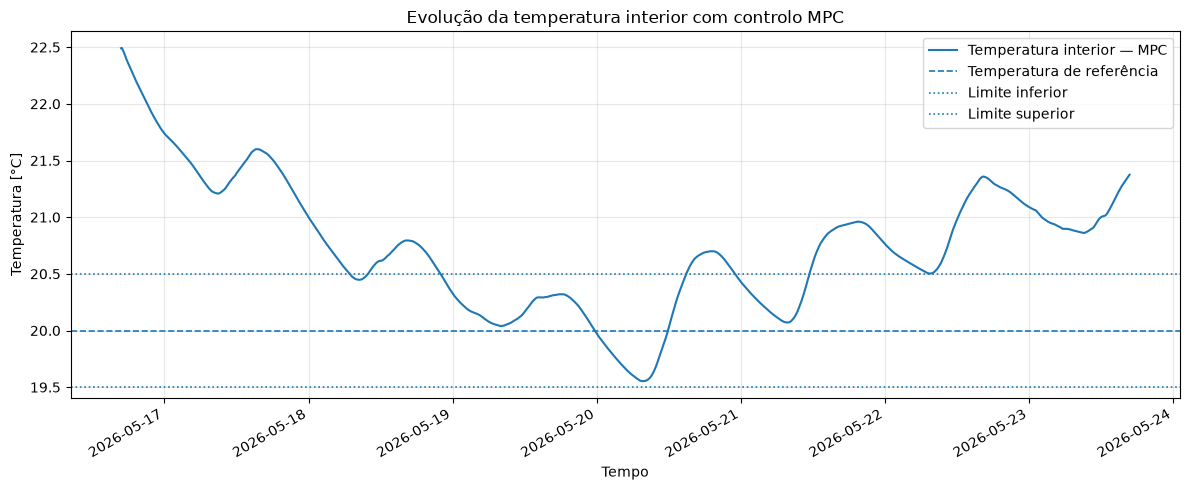

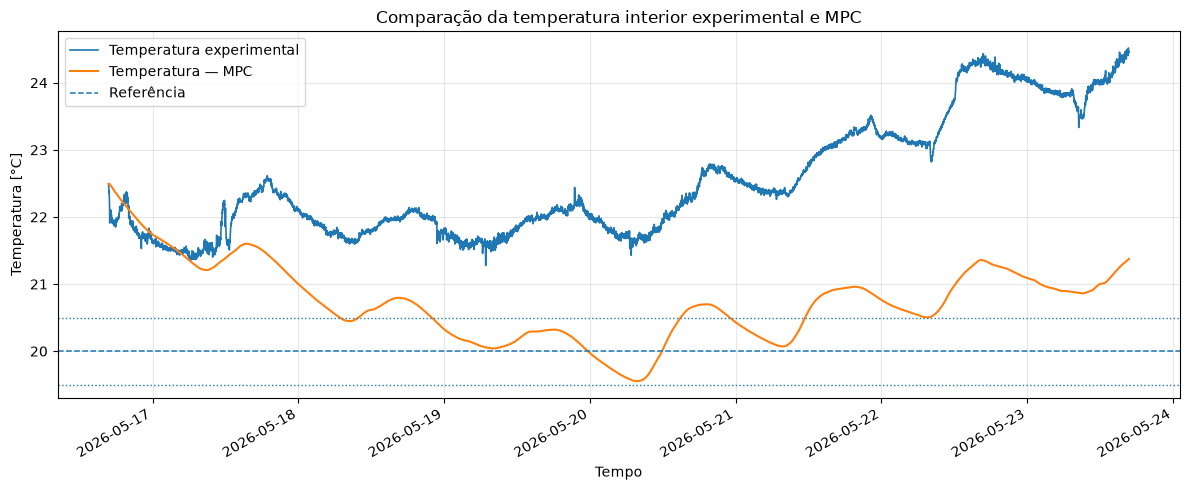

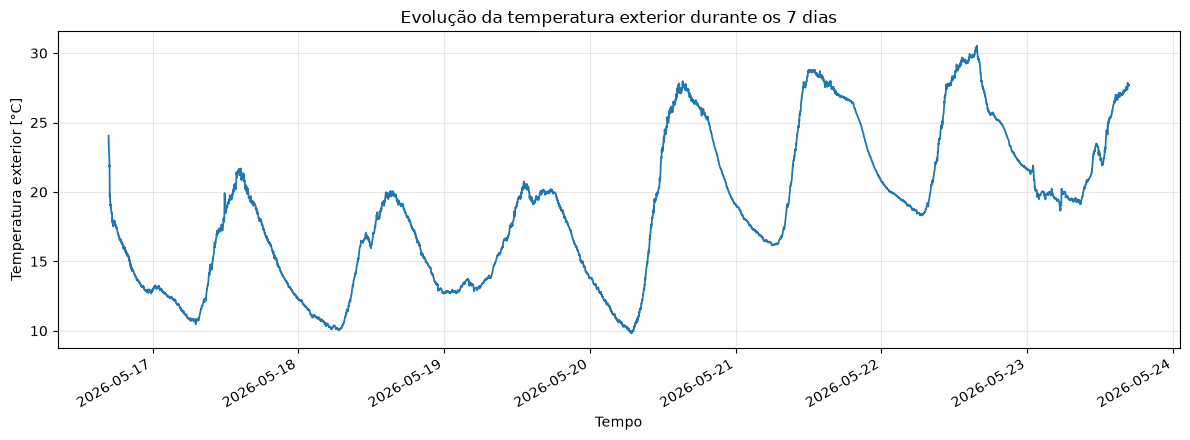

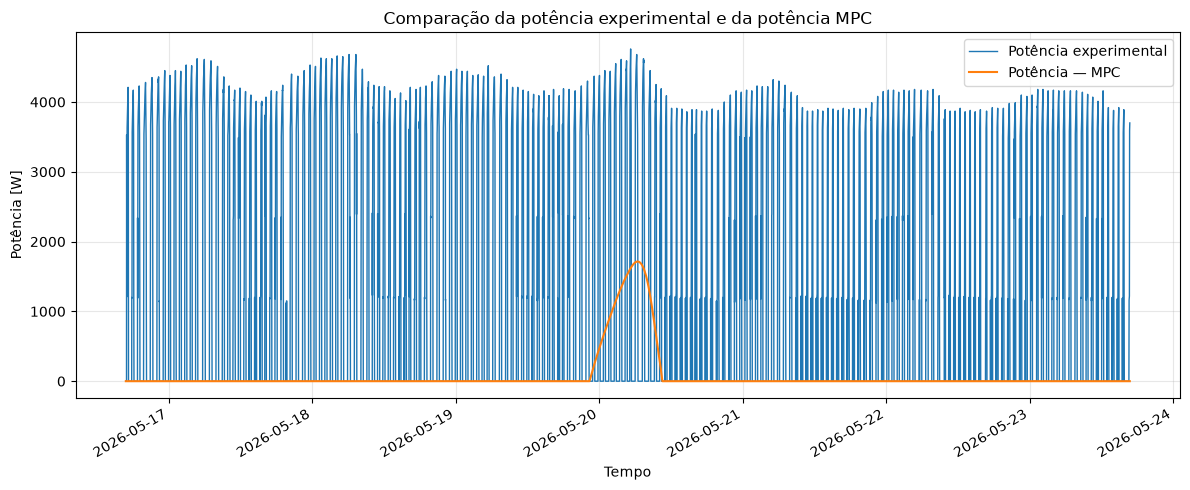

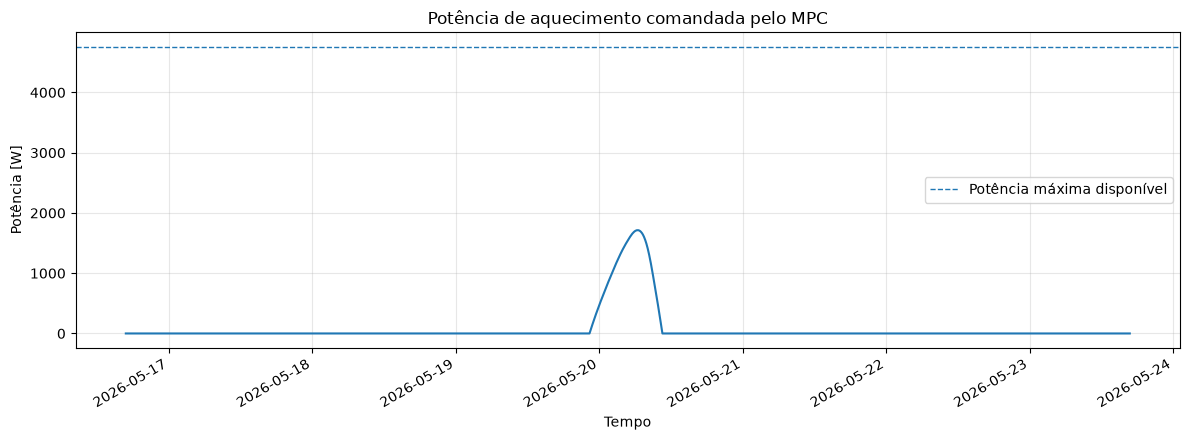

FIGURAS FINAIS DO MPC — 7 DIAS
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Temperatura_Interior.png
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Temperatura_Comparacao.png
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Temperatura_Exterior.png
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Potencia_Comparacao.png
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Potencia_MPC.png

Todas as figuras foram guardadas: True

Geração das figuras finais dos 7 dias concluída com sucesso.


In [35]:
# ============================================================
# Célula 34 — Figuras finais do MPC nos 7 dias completos
# ============================================================

# ------------------------------------------------------------
# Eixo temporal
# ------------------------------------------------------------

tempo_7d = (
    dados_experimentais_mpc[
        "DataHora"
    ]
)

tempo_temperatura_mpc_7d = (
    tempo_7d
)

tempo_estado_mpc_7d = (
    tempo_7d
)


# ------------------------------------------------------------
# Figura 1 — Temperatura interior MPC e banda de conforto
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    tempo_estado_mpc_7d,
    temperatura_mpc_controle_7d_c,
    linewidth=1.5,
    label="Temperatura interior — MPC",
)

ax.axhline(
    T_REF_FINAL_C,
    linestyle="--",
    linewidth=1.2,
    label="Temperatura de referência",
)

ax.axhline(
    T_MIN_FINAL_C,
    linestyle=":",
    linewidth=1.2,
    label="Limite inferior",
)

ax.axhline(
    T_MAX_FINAL_C,
    linestyle=":",
    linewidth=1.2,
    label="Limite superior",
)

ax.set_xlabel("Tempo")
ax.set_ylabel("Temperatura [°C]")
ax.set_title(
    "Evolução da temperatura interior com controlo MPC"
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Temperatura_Interior.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figura 2 — Comparação das temperaturas interiores
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    tempo_7d,
    temperatura_interior_experimental_7d_c,
    linewidth=1.2,
    label="Temperatura experimental",
)

ax.plot(
    tempo_estado_mpc_7d,
    temperatura_mpc_controle_7d_c,
    linewidth=1.5,
    label="Temperatura — MPC",
)

ax.axhline(
    T_REF_FINAL_C,
    linestyle="--",
    linewidth=1.1,
    label="Referência",
)

ax.axhline(
    T_MIN_FINAL_C,
    linestyle=":",
    linewidth=1.0,
)

ax.axhline(
    T_MAX_FINAL_C,
    linestyle=":",
    linewidth=1.0,
)

ax.set_xlabel("Tempo")
ax.set_ylabel("Temperatura [°C]")
ax.set_title(
    "Comparação da temperatura interior experimental e MPC"
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Temperatura_Comparacao.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figura 3 — Temperatura exterior
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 4.5)
)

ax.plot(
    tempo_7d,
    temperatura_exterior_experimental_7d_c,
    linewidth=1.3,
)

ax.set_xlabel("Tempo")
ax.set_ylabel("Temperatura exterior [°C]")
ax.set_title(
    "Evolução da temperatura exterior durante os 7 dias"
)

ax.grid(
    True,
    alpha=0.3,
)

fig.autofmt_xdate()
fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Temperatura_Exterior.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figura 4 — Comparação da potência elétrica
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    tempo_7d,
    potencia_experimental_7d_w,
    linewidth=1.0,
    label="Potência experimental",
)

ax.plot(
    tempo_7d,
    potencia_mpc_final_7d_w,
    linewidth=1.5,
    label="Potência — MPC",
)

ax.set_xlabel("Tempo")
ax.set_ylabel("Potência [W]")
ax.set_title(
    "Comparação da potência experimental e da potência MPC"
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Potencia_Comparacao.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figura 5 — Potência comandada pelo MPC
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 4.5)
)

ax.plot(
    tempo_7d,
    potencia_mpc_final_7d_w,
    linewidth=1.5,
)

ax.axhline(
    configuracao_mpc_final.potencia_maxima_w,
    linestyle="--",
    linewidth=1.0,
    label="Potência máxima disponível",
)

ax.set_xlabel("Tempo")
ax.set_ylabel("Potência [W]")
ax.set_title(
    "Potência de aquecimento comandada pelo MPC"
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Potencia_MPC.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Confirmação
# ------------------------------------------------------------

ficheiros_figuras_7d = [
    "MPC_7d_Temperatura_Interior.png",
    "MPC_7d_Temperatura_Comparacao.png",
    "MPC_7d_Temperatura_Exterior.png",
    "MPC_7d_Potencia_Comparacao.png",
    "MPC_7d_Potencia_MPC.png",
]


figuras_guardadas_7d = all(
    (
        PASTA_FIGURAS
        / nome_ficheiro
    ).exists()
    for nome_ficheiro
    in ficheiros_figuras_7d
)


print("=" * 80)
print("FIGURAS FINAIS DO MPC — 7 DIAS")
print("=" * 80)

for nome_ficheiro in ficheiros_figuras_7d:

    print(
        PASTA_FIGURAS
        / nome_ficheiro
    )

print()

print(
    f"Todas as figuras foram guardadas: "
    f"{figuras_guardadas_7d}"
)

if not figuras_guardadas_7d:

    raise RuntimeError(
        "Nem todas as figuras finais dos 7 dias "
        "foram corretamente guardadas."
    )

print()

print(
    "Geração das figuras finais dos 7 dias "
    "concluída com sucesso."
)

print("=" * 80)

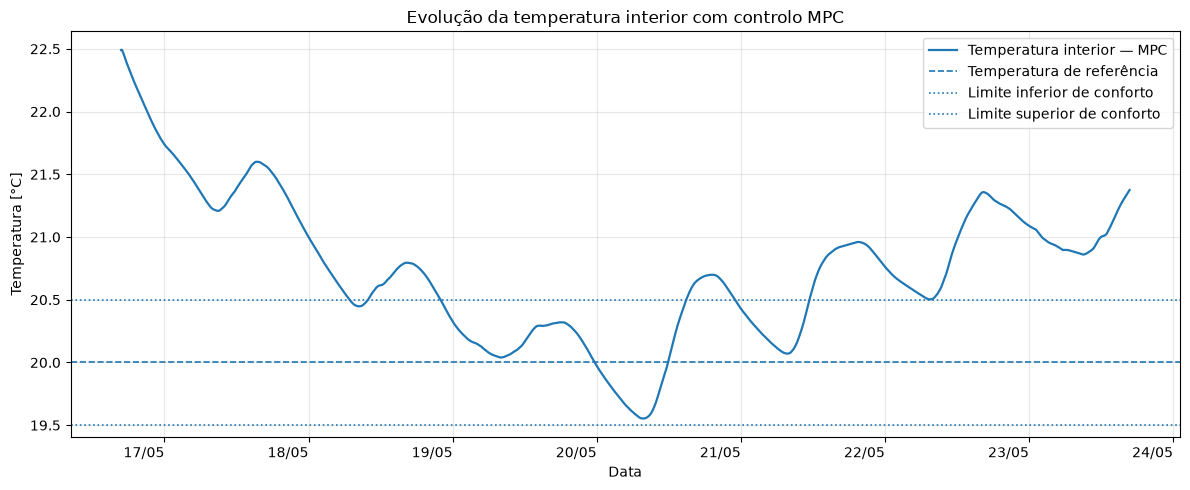

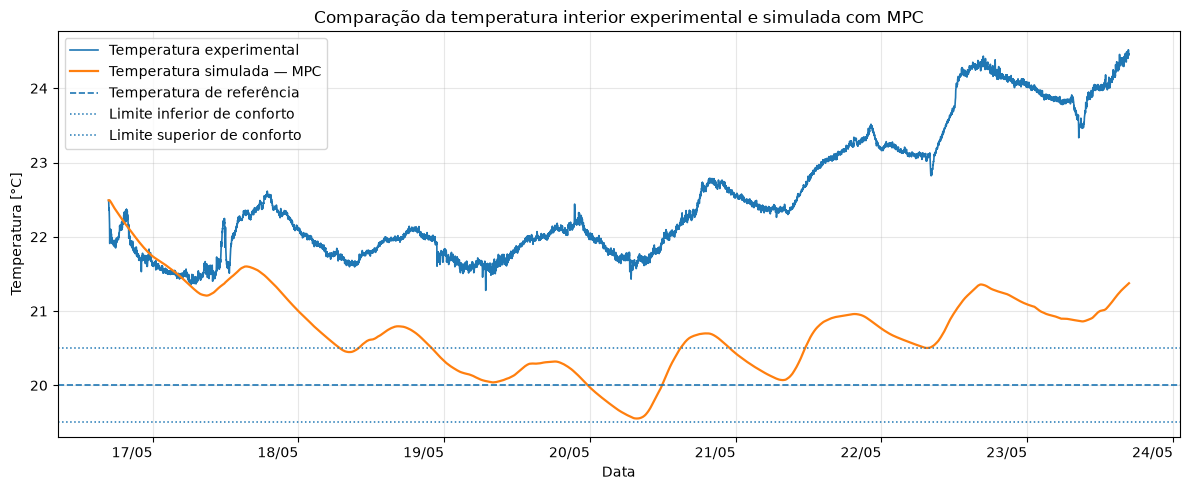

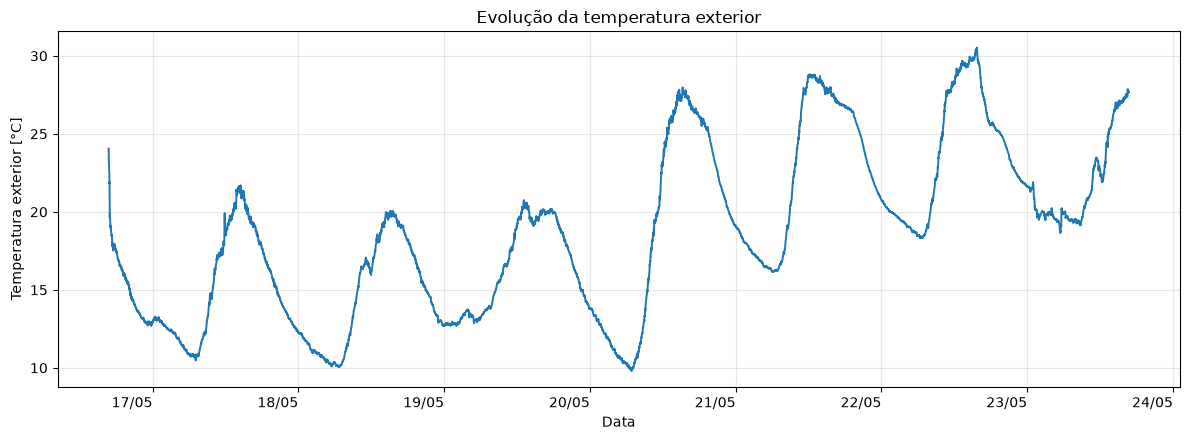

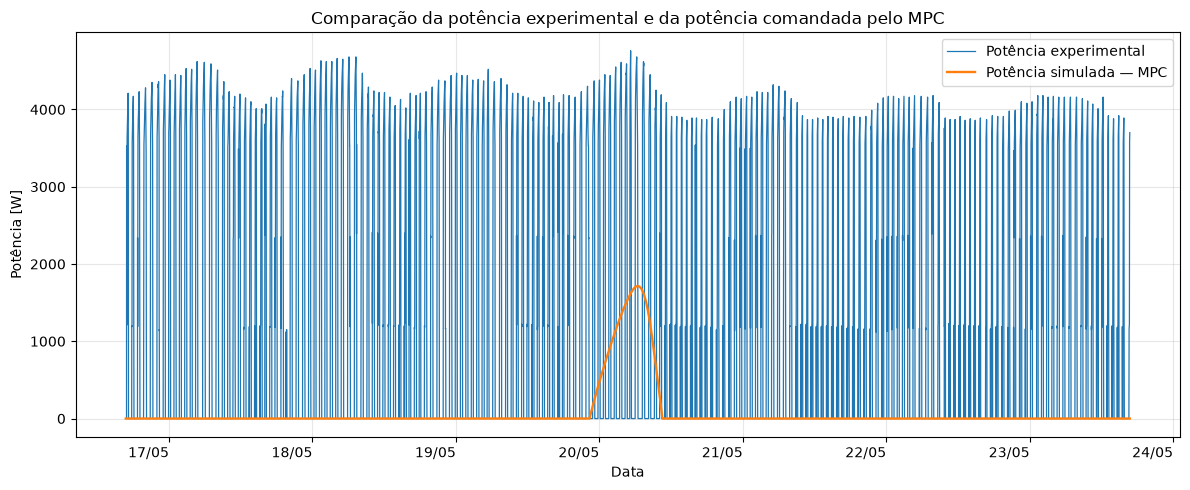

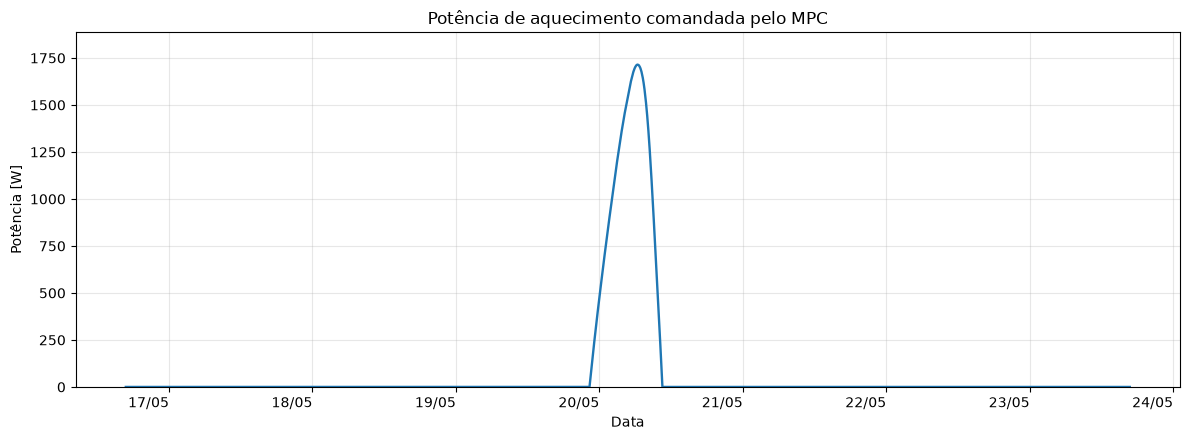

FIGURAS FINAIS FORMATADAS — MPC 7 DIAS
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Temperatura_Interior_Final.png
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Temperatura_Comparacao_Final.png
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Temperatura_Exterior_Final.png
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Potencia_Comparacao_Final.png
C:\Users\ASUS\OneDrive - Instituto Superior de Engenharia do Porto\TESE\Processamento_Python\Figuras\MPC_7d_Potencia_MPC_Final.png

Todas as figuras finais foram guardadas: True

Formatação final das figuras concluída com sucesso.


In [36]:
# ============================================================
# Célula 35 — Figuras finais formatadas para dissertação
# ============================================================

# ------------------------------------------------------------
# Formatação temporal comum
# ------------------------------------------------------------

formatador_data = mdates.DateFormatter(
    "%d/%m"
)

localizador_data = mdates.DayLocator(
    interval=1
)


# ============================================================
# Figura 1 — Temperatura interior com MPC
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    tempo_7d,
    temperatura_mpc_controle_7d_c,
    linewidth=1.6,
    label="Temperatura interior — MPC",
)

ax.axhline(
    T_REF_FINAL_C,
    linestyle="--",
    linewidth=1.2,
    label="Temperatura de referência",
)

ax.axhline(
    T_MIN_FINAL_C,
    linestyle=":",
    linewidth=1.2,
    label="Limite inferior de conforto",
)

ax.axhline(
    T_MAX_FINAL_C,
    linestyle=":",
    linewidth=1.2,
    label="Limite superior de conforto",
)

ax.set_xlabel(
    "Data"
)

ax.set_ylabel(
    "Temperatura [°C]"
)

ax.set_title(
    "Evolução da temperatura interior com controlo MPC"
)

ax.xaxis.set_major_locator(
    localizador_data
)

ax.xaxis.set_major_formatter(
    formatador_data
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend(
    loc="best"
)

fig.autofmt_xdate(
    rotation=0
)

fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Temperatura_Interior_Final.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# Figura 2 — Comparação das temperaturas interiores
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    tempo_7d,
    temperatura_interior_experimental_7d_c,
    linewidth=1.2,
    label="Temperatura experimental",
)

ax.plot(
    tempo_7d,
    temperatura_mpc_controle_7d_c,
    linewidth=1.6,
    label="Temperatura simulada — MPC",
)

ax.axhline(
    T_REF_FINAL_C,
    linestyle="--",
    linewidth=1.2,
    label="Temperatura de referência",
)

ax.axhline(
    T_MIN_FINAL_C,
    linestyle=":",
    linewidth=1.1,
    label="Limite inferior de conforto",
)

ax.axhline(
    T_MAX_FINAL_C,
    linestyle=":",
    linewidth=1.1,
    label="Limite superior de conforto",
)

ax.set_xlabel(
    "Data"
)

ax.set_ylabel(
    "Temperatura [°C]"
)

ax.set_title(
    "Comparação da temperatura interior experimental e simulada com MPC"
)

ax.xaxis.set_major_locator(
    localizador_data
)

ax.xaxis.set_major_formatter(
    formatador_data
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend(
    loc="best"
)

fig.autofmt_xdate(
    rotation=0
)

fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Temperatura_Comparacao_Final.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# Figura 3 — Temperatura exterior
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 4.5)
)

ax.plot(
    tempo_7d,
    temperatura_exterior_experimental_7d_c,
    linewidth=1.4,
)

ax.set_xlabel(
    "Data"
)

ax.set_ylabel(
    "Temperatura exterior [°C]"
)

ax.set_title(
    "Evolução da temperatura exterior"
)

ax.xaxis.set_major_locator(
    localizador_data
)

ax.xaxis.set_major_formatter(
    formatador_data
)

ax.grid(
    True,
    alpha=0.3,
)

fig.autofmt_xdate(
    rotation=0
)

fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Temperatura_Exterior_Final.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# Figura 4 — Comparação das potências
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    tempo_7d,
    potencia_experimental_7d_w,
    linewidth=0.9,
    label="Potência experimental",
)

ax.plot(
    tempo_7d,
    potencia_mpc_final_7d_w,
    linewidth=1.7,
    label="Potência simulada — MPC",
)

ax.set_xlabel(
    "Data"
)

ax.set_ylabel(
    "Potência [W]"
)

ax.set_title(
    "Comparação da potência experimental e da potência comandada pelo MPC"
)

ax.xaxis.set_major_locator(
    localizador_data
)

ax.xaxis.set_major_formatter(
    formatador_data
)

ax.grid(
    True,
    alpha=0.3,
)

ax.legend(
    loc="best"
)

fig.autofmt_xdate(
    rotation=0
)

fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Potencia_Comparacao_Final.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# Figura 5 — Potência comandada pelo MPC
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 4.5)
)

ax.plot(
    tempo_7d,
    potencia_mpc_final_7d_w,
    linewidth=1.7,
)

ax.set_xlabel(
    "Data"
)

ax.set_ylabel(
    "Potência [W]"
)

ax.set_title(
    "Potência de aquecimento comandada pelo MPC"
)

ax.xaxis.set_major_locator(
    localizador_data
)

ax.xaxis.set_major_formatter(
    formatador_data
)

ax.grid(
    True,
    alpha=0.3,
)

# Escala ajustada à atuação efetiva do MPC
limite_superior_potencia_grafico_w = (
    1.10
    * potencia_mpc_final_7d_w.max()
)

ax.set_ylim(
    bottom=0.0,
    top=limite_superior_potencia_grafico_w,
)

fig.autofmt_xdate(
    rotation=0
)

fig.tight_layout()

caminho_figura = (
    PASTA_FIGURAS
    / "MPC_7d_Potencia_MPC_Final.png"
)

fig.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# Verificação dos ficheiros gerados
# ============================================================

ficheiros_figuras_finais_7d = [
    "MPC_7d_Temperatura_Interior_Final.png",
    "MPC_7d_Temperatura_Comparacao_Final.png",
    "MPC_7d_Temperatura_Exterior_Final.png",
    "MPC_7d_Potencia_Comparacao_Final.png",
    "MPC_7d_Potencia_MPC_Final.png",
]


figuras_finais_guardadas_7d = all(
    (
        PASTA_FIGURAS
        / nome_ficheiro
    ).exists()
    for nome_ficheiro
    in ficheiros_figuras_finais_7d
)


print("=" * 85)
print("FIGURAS FINAIS FORMATADAS — MPC 7 DIAS")
print("=" * 85)

for nome_ficheiro in ficheiros_figuras_finais_7d:

    print(
        PASTA_FIGURAS
        / nome_ficheiro
    )

print()

print(
    f"Todas as figuras finais foram guardadas: "
    f"{figuras_finais_guardadas_7d}"
)

if not figuras_finais_guardadas_7d:

    raise RuntimeError(
        "Nem todas as figuras finais foram "
        "corretamente guardadas."
    )

print()

print(
    "Formatação final das figuras concluída com sucesso."
)

print("=" * 85)

In [37]:
# ============================================================
# Célula 36 — Comparação quantitativa final entre
#             funcionamento experimental e MPC
# ============================================================

# ------------------------------------------------------------
# Temperatura experimental
# ------------------------------------------------------------

temperatura_experimental_media_7d_c = float(
    np.mean(
        temperatura_interior_experimental_7d_c
    )
)

temperatura_experimental_minima_7d_c = float(
    np.min(
        temperatura_interior_experimental_7d_c
    )
)

temperatura_experimental_maxima_7d_c = float(
    np.max(
        temperatura_interior_experimental_7d_c
    )
)


# ------------------------------------------------------------
# Temperatura MPC
# ------------------------------------------------------------

temperatura_mpc_media_7d_c = float(
    np.mean(
        temperatura_mpc_controle_7d_c
    )
)

temperatura_mpc_minima_7d_c = float(
    np.min(
        temperatura_mpc_controle_7d_c
    )
)

temperatura_mpc_maxima_7d_c = float(
    np.max(
        temperatura_mpc_controle_7d_c
    )
)


# ------------------------------------------------------------
# Classificação térmica experimental
# ------------------------------------------------------------

experimental_dentro_banda_7d = (
    (temperatura_interior_experimental_7d_c >= T_MIN_FINAL_C)
    & (temperatura_interior_experimental_7d_c <= T_MAX_FINAL_C)
)

experimental_abaixo_banda_7d = (
    temperatura_interior_experimental_7d_c
    < T_MIN_FINAL_C
)

experimental_acima_banda_7d = (
    temperatura_interior_experimental_7d_c
    > T_MAX_FINAL_C
)


percentagem_experimental_dentro_banda_7d = (
    100.0
    * np.mean(
        experimental_dentro_banda_7d
    )
)

percentagem_experimental_abaixo_banda_7d = (
    100.0
    * np.mean(
        experimental_abaixo_banda_7d
    )
)

percentagem_experimental_acima_banda_7d = (
    100.0
    * np.mean(
        experimental_acima_banda_7d
    )
)


# ------------------------------------------------------------
# Potência
# ------------------------------------------------------------

potencia_experimental_media_7d_w = float(
    np.mean(
        potencia_experimental_7d_w
    )
)

potencia_experimental_maxima_7d_w = float(
    np.max(
        potencia_experimental_7d_w
    )
)

potencia_mpc_media_7d_w = float(
    np.mean(
        potencia_mpc_final_7d_w
    )
)

potencia_mpc_maxima_7d_w = float(
    np.max(
        potencia_mpc_final_7d_w
    )
)


# ------------------------------------------------------------
# Energia
# ------------------------------------------------------------

energia_experimental_comparacao_7d_kwh = (
    np.sum(
        potencia_experimental_7d_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)

energia_mpc_comparacao_7d_kwh = (
    np.sum(
        potencia_mpc_final_7d_w
    )
    * PERIODO_AMOSTRAGEM_S
    / 3.6e6
)


diferenca_energia_7d_kwh = (
    energia_experimental_comparacao_7d_kwh
    - energia_mpc_comparacao_7d_kwh
)

diferenca_energia_7d_percentagem = (
    100.0
    * diferenca_energia_7d_kwh
    / energia_experimental_comparacao_7d_kwh
)


# ------------------------------------------------------------
# Variação da potência experimental
# ------------------------------------------------------------

variacao_potencia_experimental_7d_w = np.diff(
    potencia_experimental_7d_w,
    prepend=potencia_experimental_7d_w[0],
)

delta_p_experimental_7d_w = np.abs(
    variacao_potencia_experimental_7d_w
)


delta_p_experimental_medio_7d_w = float(
    np.mean(
        delta_p_experimental_7d_w
    )
)

delta_p_experimental_maximo_7d_w = float(
    np.max(
        delta_p_experimental_7d_w
    )
)


# ------------------------------------------------------------
# Variação da potência MPC
# ------------------------------------------------------------

delta_p_mpc_medio_comparacao_7d_w = float(
    np.mean(
        delta_p_absoluto_mpc_7d_w
    )
)

delta_p_mpc_maximo_comparacao_7d_w = float(
    np.max(
        delta_p_absoluto_mpc_7d_w
    )
)


# ------------------------------------------------------------
# Atuação significativa
# ------------------------------------------------------------

experimental_ativo_7d = (
    potencia_experimental_7d_w
    > LIMIAR_ATUACAO_MPC_W
)

mpc_ativo_comparacao_7d = (
    potencia_mpc_final_7d_w
    > LIMIAR_ATUACAO_MPC_W
)


percentagem_experimental_ativo_7d = (
    100.0
    * np.mean(
        experimental_ativo_7d
    )
)

percentagem_mpc_ativo_comparacao_7d = (
    100.0
    * np.mean(
        mpc_ativo_comparacao_7d
    )
)


# ------------------------------------------------------------
# Construção da tabela comparativa
# ------------------------------------------------------------

tabela_comparacao_final_7d = pd.DataFrame(
    {
        "Indicador": [
            "Temperatura média [°C]",
            "Temperatura mínima [°C]",
            "Temperatura máxima [°C]",
            "Tempo dentro da banda [%]",
            "Tempo abaixo da banda [%]",
            "Tempo acima da banda [%]",
            "Potência média [W]",
            "Potência máxima [W]",
            "Energia [kWh]",
            "|Delta P| médio [W]",
            "|Delta P| máximo [W]",
            "Tempo com P > 100 W [%]",
        ],

        "Experimental": [
            temperatura_experimental_media_7d_c,
            temperatura_experimental_minima_7d_c,
            temperatura_experimental_maxima_7d_c,
            percentagem_experimental_dentro_banda_7d,
            percentagem_experimental_abaixo_banda_7d,
            percentagem_experimental_acima_banda_7d,
            potencia_experimental_media_7d_w,
            potencia_experimental_maxima_7d_w,
            energia_experimental_comparacao_7d_kwh,
            delta_p_experimental_medio_7d_w,
            delta_p_experimental_maximo_7d_w,
            percentagem_experimental_ativo_7d,
        ],

        "MPC": [
            temperatura_mpc_media_7d_c,
            temperatura_mpc_minima_7d_c,
            temperatura_mpc_maxima_7d_c,
            percentagem_dentro_banda_mpc_7d,
            percentagem_abaixo_banda_mpc_7d,
            percentagem_acima_banda_mpc_7d,
            potencia_mpc_media_7d_w,
            potencia_mpc_maxima_7d_w,
            energia_mpc_comparacao_7d_kwh,
            delta_p_mpc_medio_comparacao_7d_w,
            delta_p_mpc_maximo_comparacao_7d_w,
            percentagem_mpc_ativo_comparacao_7d,
        ],
    }
)


# ------------------------------------------------------------
# Validação
# ------------------------------------------------------------

comparacao_final_valida_7d = (
    np.isfinite(
        tabela_comparacao_final_7d[
            [
                "Experimental",
                "MPC",
            ]
        ].to_numpy()
    ).all()
    and energia_experimental_comparacao_7d_kwh > 0.0
    and energia_mpc_comparacao_7d_kwh >= 0.0
)


# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("=" * 100)
print(
    "COMPARAÇÃO QUANTITATIVA FINAL — "
    "FUNCIONAMENTO EXPERIMENTAL VS. MPC"
)
print("=" * 100)

print()

print(
    tabela_comparacao_final_7d.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.3f}",
    )
)

print()

print("DIFERENÇA ENERGÉTICA OBSERVADA:")

print(
    f"Experimental = "
    f"{energia_experimental_comparacao_7d_kwh:.3f} kWh"
)

print(
    f"MPC = "
    f"{energia_mpc_comparacao_7d_kwh:.3f} kWh"
)

print(
    f"Diferença absoluta = "
    f"{diferenca_energia_7d_kwh:.3f} kWh"
)

print(
    f"Diferença relativa = "
    f"{diferenca_energia_7d_percentagem:.2f} %"
)

print()

print(
    "Nota metodológica: a diferença energética calculada "
    "representa uma comparação entre o consumo experimental "
    "medido e o consumo obtido na simulação com MPC. "
    "Não é interpretada diretamente como uma poupança "
    "energética experimental."
)

print()

print(
    f"Comparação final numericamente válida: "
    f"{comparacao_final_valida_7d}"
)

if not comparacao_final_valida_7d:

    raise RuntimeError(
        "A comparação quantitativa final apresentou "
        "resultados numéricos inválidos."
    )

print()

print(
    "Comparação quantitativa final concluída com sucesso."
)

print("=" * 100)

COMPARAÇÃO QUANTITATIVA FINAL — FUNCIONAMENTO EXPERIMENTAL VS. MPC

                Indicador  Experimental      MPC
   Temperatura média [°C]        22.513   20.741
  Temperatura mínima [°C]        21.279   19.553
  Temperatura máxima [°C]        24.518   22.493
Tempo dentro da banda [%]         0.000   33.552
Tempo abaixo da banda [%]         0.000    0.000
 Tempo acima da banda [%]       100.000   66.448
       Potência média [W]      1174.553   75.439
      Potência máxima [W]      4760.000 1714.870
            Energia [kWh]       197.325   12.674
      |Delta P| médio [W]       176.788    0.340
     |Delta P| máximo [W]      3810.000   11.140
  Tempo com P > 100 W [%]        34.931    6.974

DIFERENÇA ENERGÉTICA OBSERVADA:
Experimental = 197.325 kWh
MPC = 12.674 kWh
Diferença absoluta = 184.651 kWh
Diferença relativa = 93.58 %

Nota metodológica: a diferença energética calculada representa uma comparação entre o consumo experimental medido e o consumo obtido na simulação com MPC. 

In [38]:
# ============================================================
# Análise da extrapolação térmica do modelo 2R2C
# ============================================================

print("=" * 90)
print("ANÁLISE DA EXTRAPOLAÇÃO TÉRMICA — MODELO 2R2C / MPC")
print("=" * 90)

# Limites observados nos dados experimentais sincronizados
temperatura_minima_identificacao_c = 21.279
temperatura_maxima_identificacao_c = 24.518

# Trajetória de temperatura interior simulada pelo MPC
temperatura_mpc_7d_c = np.asarray(
    resultado_mpc_final_7d.temperatura_interior_c,
    dtype=float,
)

# ------------------------------------------------------------
# Identificação das amostras fora da gama experimental
# ------------------------------------------------------------

abaixo_gama_identificacao = (
    temperatura_mpc_7d_c < temperatura_minima_identificacao_c
)

acima_gama_identificacao = (
    temperatura_mpc_7d_c > temperatura_maxima_identificacao_c
)

fora_gama_identificacao = (
    abaixo_gama_identificacao | acima_gama_identificacao
)

n_amostras = len(temperatura_mpc_7d_c)

percentagem_abaixo = (
    100.0 * np.sum(abaixo_gama_identificacao) / n_amostras
)

percentagem_acima = (
    100.0 * np.sum(acima_gama_identificacao) / n_amostras
)

percentagem_fora = (
    100.0 * np.sum(fora_gama_identificacao) / n_amostras
)

# ------------------------------------------------------------
# Distância máxima à gama experimental
# ------------------------------------------------------------

extrapolacao_inferior_max_c = max(
    0.0,
    temperatura_minima_identificacao_c
    - np.min(temperatura_mpc_7d_c),
)

extrapolacao_superior_max_c = max(
    0.0,
    np.max(temperatura_mpc_7d_c)
    - temperatura_maxima_identificacao_c,
)

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------

print()
print("GAMA EXPERIMENTAL UTILIZADA:")
print(
    f"T_int mínima = "
    f"{temperatura_minima_identificacao_c:.3f} °C"
)
print(
    f"T_int máxima = "
    f"{temperatura_maxima_identificacao_c:.3f} °C"
)

print()
print("TRAJETÓRIA MPC:")
print(
    f"T_int mínima = "
    f"{np.min(temperatura_mpc_7d_c):.3f} °C"
)
print(
    f"T_int máxima = "
    f"{np.max(temperatura_mpc_7d_c):.3f} °C"
)

print()
print("EXTRAPOLAÇÃO:")

print(
    f"Amostras abaixo da gama experimental = "
    f"{np.sum(abaixo_gama_identificacao)} "
    f"({percentagem_abaixo:.2f} %)"
)

print(
    f"Amostras acima da gama experimental = "
    f"{np.sum(acima_gama_identificacao)} "
    f"({percentagem_acima:.2f} %)"
)

print(
    f"Amostras fora da gama experimental = "
    f"{np.sum(fora_gama_identificacao)} "
    f"({percentagem_fora:.2f} %)"
)

print()
print(
    f"Extrapolação máxima abaixo da gama = "
    f"{extrapolacao_inferior_max_c:.3f} °C"
)

print(
    f"Extrapolação máxima acima da gama = "
    f"{extrapolacao_superior_max_c:.3f} °C"
)

# ------------------------------------------------------------
# Validação numérica
# ------------------------------------------------------------

analise_extrapolacao_valida = (
    np.all(np.isfinite(temperatura_mpc_7d_c))
    and 0.0 <= percentagem_fora <= 100.0
)

print()
print(
    f"Análise numericamente válida: "
    f"{analise_extrapolacao_valida}"
)

print("=" * 90)

ANÁLISE DA EXTRAPOLAÇÃO TÉRMICA — MODELO 2R2C / MPC

GAMA EXPERIMENTAL UTILIZADA:
T_int mínima = 21.279 °C
T_int máxima = 24.518 °C

TRAJETÓRIA MPC:
T_int mínima = 19.553 °C
T_int máxima = 22.493 °C

EXTRAPOLAÇÃO:
Amostras abaixo da gama experimental = 8305 (82.38 %)
Amostras acima da gama experimental = 0 (0.00 %)
Amostras fora da gama experimental = 8305 (82.38 %)

Extrapolação máxima abaixo da gama = 1.726 °C
Extrapolação máxima acima da gama = 0.000 °C

Análise numericamente válida: True


In [39]:
# ============================================================
# Diagnóstico definitivo das classes e funções MPC carregadas
# ============================================================

import inspect

print("=" * 90)
print("DIAGNÓSTICO DA CONFIGURAÇÃO MPC")
print("=" * 90)

print()
print("1. ASSINATURA DE criar_configuracao_mpc_padrao")
print("-" * 90)

print(
    inspect.signature(
        criar_configuracao_mpc_padrao
    )
)

print()
print("2. CLASSE DA CONFIGURAÇÃO ATUAL")
print("-" * 90)

print(
    type(configuracao_mpc_final)
)

print()
print("3. MÓDULO DA CLASSE DA CONFIGURAÇÃO ATUAL")
print("-" * 90)

print(
    type(configuracao_mpc_final).__module__
)

print()
print("4. IDENTIDADE DA CLASSE")
print("-" * 90)

print(
    id(type(configuracao_mpc_final))
)

print()
print("5. ASSINATURA DE simular_mpc_horizonte_deslizante")
print("-" * 90)

print(
    inspect.signature(
        simular_mpc_horizonte_deslizante
    )
)

print()
print("=" * 90)

DIAGNÓSTICO DA CONFIGURAÇÃO MPC

1. ASSINATURA DE criar_configuracao_mpc_padrao
------------------------------------------------------------------------------------------
() -> Codigos.MPC_2R2C.ConfiguracaoMPC2R2C

2. CLASSE DA CONFIGURAÇÃO ATUAL
------------------------------------------------------------------------------------------
<class 'Codigos.MPC_2R2C.ConfiguracaoMPC2R2C'>

3. MÓDULO DA CLASSE DA CONFIGURAÇÃO ATUAL
------------------------------------------------------------------------------------------
Codigos.MPC_2R2C

4. IDENTIDADE DA CLASSE
------------------------------------------------------------------------------------------
1287166181776

5. ASSINATURA DE simular_mpc_horizonte_deslizante
------------------------------------------------------------------------------------------
(matrizes, estado_inicial: 'np.ndarray', temperatura_exterior_c: 'np.ndarray', configuracao: 'ConfiguracaoMPC2R2C', temperatura_referencia=None, potencia_inicial_w: 'float' = 0.0, numero_passo

In [40]:
# ============================================================
# Cenário complementar MPC — referência de 22,5 °C
# Recarregamento consistente dos módulos e simulação de 7 dias
# ============================================================

import importlib
import numpy as np

from dataclasses import replace

import Codigos.MPC_2R2C as modulo_mpc
import Codigos.Simulacao_MPC_2R2C as modulo_simulacao_mpc


# ============================================================
# 1. Recarregamento dos módulos pela ordem correta
# ============================================================

# O módulo MPC deve ser recarregado primeiro porque contém
# ConfiguracaoMPC2R2C e as funções utilizadas pela simulação.

importlib.reload(modulo_mpc)
importlib.reload(modulo_simulacao_mpc)


# ============================================================
# 2. Atualização das referências utilizadas no notebook
# ============================================================

criar_configuracao_mpc_padrao = (
    modulo_mpc.criar_configuracao_mpc_padrao
)

validar_configuracao_mpc = (
    modulo_mpc.validar_configuracao_mpc
)

simular_mpc_horizonte_deslizante = (
    modulo_simulacao_mpc.simular_mpc_horizonte_deslizante
)

validar_resultado_simulacao_mpc = (
    modulo_simulacao_mpc.validar_resultado_simulacao_mpc
)

mostrar_resumo_simulacao_mpc = (
    modulo_simulacao_mpc.mostrar_resumo_simulacao_mpc
)


# ============================================================
# 3. Reconstrução da configuração principal
# ============================================================

# A função cria_configuracao_mpc_padrao não recebe argumentos.
# Primeiro é criada a configuração padrão e depois são
# definidos explicitamente os parâmetros finais selecionados.

configuracao_mpc_final = criar_configuracao_mpc_padrao()

configuracao_mpc_final = replace(
    configuracao_mpc_final,
    horizonte_predicao=120,
    horizonte_controlo=12,
    temperatura_referencia=20.0,
    temperatura_minima=19.5,
    temperatura_maxima=20.5,
    potencia_minima_w=0.0,
    potencia_maxima_w=4760.0,
    peso_temperatura=0.5,
    peso_potencia=0.05,
    peso_variacao_potencia=0.1,
    peso_violacao_conforto=100.0,
)


# ============================================================
# 4. Configuração do cenário complementar
# ============================================================

# Temperatura média interior experimental ≈ 22,513 °C.
#
# É adotada:
#
# T_ref = 22,5 °C
# T_min = 22,0 °C
# T_max = 23,0 °C
#
# Todos os restantes parâmetros permanecem iguais ao
# cenário principal.

configuracao_mpc_22_5 = replace(
    configuracao_mpc_final,
    temperatura_referencia=22.5,
    temperatura_minima=22.0,
    temperatura_maxima=23.0,
)


# ============================================================
# 5. Validação das configurações
# ============================================================

validar_configuracao_mpc(
    configuracao_mpc_final
)

validar_configuracao_mpc(
    configuracao_mpc_22_5
)


# ============================================================
# 6. Verificação das classes carregadas
# ============================================================

print("=" * 90)
print("VERIFICAÇÃO DAS CONFIGURAÇÕES MPC")
print("=" * 90)

print()
print(
    "Classe da configuração principal:"
)
print(
    type(configuracao_mpc_final)
)

print()
print(
    "Classe da configuração complementar:"
)
print(
    type(configuracao_mpc_22_5)
)

print()
print(
    "Configuração principal:"
)

print(
    f"T_ref = "
    f"{configuracao_mpc_final.temperatura_referencia:.1f} °C"
)

print(
    f"Banda = "
    f"[{configuracao_mpc_final.temperatura_minima:.1f}, "
    f"{configuracao_mpc_final.temperatura_maxima:.1f}] °C"
)

print()
print(
    "Configuração complementar:"
)

print(
    f"T_ref = "
    f"{configuracao_mpc_22_5.temperatura_referencia:.1f} °C"
)

print(
    f"Banda = "
    f"[{configuracao_mpc_22_5.temperatura_minima:.1f}, "
    f"{configuracao_mpc_22_5.temperatura_maxima:.1f}] °C"
)

print()
print(
    f"Np = {configuracao_mpc_22_5.horizonte_predicao}"
)

print(
    f"Nc = {configuracao_mpc_22_5.horizonte_controlo}"
)

print(
    f"qT = {configuracao_mpc_22_5.peso_temperatura}"
)

print(
    f"qP = {configuracao_mpc_22_5.peso_potencia}"
)

print(
    f"qDeltaP = "
    f"{configuracao_mpc_22_5.peso_variacao_potencia}"
)

print(
    f"qEpsilon = "
    f"{configuracao_mpc_22_5.peso_violacao_conforto}"
)

print("=" * 90)


# ============================================================
# 7. Simulação MPC — 7 dias
# ============================================================

print()
print("=" * 90)
print("SIMULAÇÃO MPC — REFERÊNCIA DE 22,5 °C")
print("=" * 90)

resultado_mpc_22_5_7d = (
    simular_mpc_horizonte_deslizante(
        matrizes_discretas_2r2c_selecionadas,
        estado_inicial_mpc_final_7d,
        temperatura_exterior_7d_c,
        configuracao_mpc_22_5,
        potencia_inicial_w=0.0,
    )
)


# ============================================================
# 8. Validação numérica
# ============================================================

try:
    validar_resultado_simulacao_mpc(
        resultado_mpc_22_5_7d,
        configuracao_mpc_22_5,
    )

    simulacao_22_5_valida = True

except Exception as erro:
    simulacao_22_5_valida = False

    print()
    print("Erro detetado durante a validação:")
    print(erro)


# ============================================================
# 9. Resumo dos resultados
# ============================================================

print()
print("=" * 90)
print("RESUMO DO CENÁRIO COMPLEMENTAR")
print("=" * 90)

mostrar_resumo_simulacao_mpc(
    resultado_mpc_22_5_7d,
    configuracao_mpc_22_5,
)


# ============================================================
# 10. Resultado final
# ============================================================

print()
print("=" * 90)

print(
    f"Simulação numericamente válida: "
    f"{simulacao_22_5_valida}"
)

if simulacao_22_5_valida:
    print(
        "Cenário complementar de 22,5 °C "
        "concluído com sucesso."
    )
else:
    print(
        "ATENÇÃO: a simulação complementar "
        "não passou todas as validações."
    )

print("=" * 90)

VERIFICAÇÃO DAS CONFIGURAÇÕES MPC

Classe da configuração principal:
<class 'Codigos.MPC_2R2C.ConfiguracaoMPC2R2C'>

Classe da configuração complementar:
<class 'Codigos.MPC_2R2C.ConfiguracaoMPC2R2C'>

Configuração principal:
T_ref = 20.0 °C
Banda = [19.5, 20.5] °C

Configuração complementar:
T_ref = 22.5 °C
Banda = [22.0, 23.0] °C

Np = 120
Nc = 12
qT = 0.5
qP = 0.05
qDeltaP = 0.1
qEpsilon = 100.0

SIMULAÇÃO MPC — REFERÊNCIA DE 22,5 °C

RESUMO DO CENÁRIO COMPLEMENTAR
SIMULAÇÃO MPC EM HORIZONTE DESLIZANTE
Número de passos simulados: 10080
Taxa de convergência: 100.00 %

Temperatura interior:
Inicial = 22.490 °C
Final = 23.111 °C
Mínima = 21.999 °C
Máxima = 23.311 °C

Potência aplicada:
Mínima = 0.00 W
Máxima = 4535.63 W
Média = 896.33 W

Esforço computacional:
Iterações médias = 2.63
Avaliações médias = 34.65
Tempo médio por otimização = 0.0530 s
Tempo acumulado de otimização = 534.3333 s

Simulação numericamente válida: True
Cenário complementar de 22,5 °C concluído com sucesso.


In [41]:
# ============================================================
# Cenário complementar MPC — referência de 22,5 °C
# Simulação, validação e resumo final
# ============================================================

print("=" * 90)
print("CENÁRIO COMPLEMENTAR — MPC COM REFERÊNCIA DE 22,5 °C")
print("=" * 90)


# ============================================================
# 1. Apresentação da configuração utilizada
# ============================================================

print()
print("CONFIGURAÇÃO DO CENÁRIO COMPLEMENTAR:")
print("-" * 90)

print(
    f"Temperatura de referência = "
    f"{configuracao_mpc_22_5.temperatura_referencia:.2f} °C"
)

print(
    f"Limite inferior = "
    f"{configuracao_mpc_22_5.temperatura_minima:.2f} °C"
)

print(
    f"Limite superior = "
    f"{configuracao_mpc_22_5.temperatura_maxima:.2f} °C"
)

print()
print("HORIZONTES:")

print(
    f"Np = "
    f"{configuracao_mpc_22_5.horizonte_predicao}"
)

print(
    f"Nc = "
    f"{configuracao_mpc_22_5.horizonte_controlo}"
)

print()
print("PESOS DA FUNÇÃO OBJETIVO:")

print(
    f"qT = "
    f"{configuracao_mpc_22_5.peso_temperatura:.3f}"
)

print(
    f"qP = "
    f"{configuracao_mpc_22_5.peso_potencia:.3f}"
)

print(
    f"qDeltaP = "
    f"{configuracao_mpc_22_5.peso_variacao_potencia:.3f}"
)

print(
    f"qEpsilon = "
    f"{configuracao_mpc_22_5.peso_violacao_conforto:.3f}"
)

print()
print("LIMITES DE POTÊNCIA:")

print(
    f"P_min = "
    f"{configuracao_mpc_22_5.potencia_minima_w:.2f} W"
)

print(
    f"P_max = "
    f"{configuracao_mpc_22_5.potencia_maxima_w:.2f} W"
)


# ============================================================
# 2. Simulação MPC em horizonte deslizante — 7 dias
# ============================================================

print()
print("=" * 90)
print("SIMULAÇÃO MPC — REFERÊNCIA DE 22,5 °C")
print("=" * 90)

resultado_mpc_22_5_7d = simular_mpc_horizonte_deslizante(
    matrizes_discretas_2r2c_selecionadas,
    estado_inicial_mpc_final_7d,
    temperatura_exterior_7d_c,
    configuracao_mpc_22_5,
    potencia_inicial_w=0.0,
)


# ============================================================
# 3. Validação numérica correta
# ============================================================

print()
print("=" * 90)
print("VALIDAÇÃO NUMÉRICA")
print("=" * 90)

try:

    validar_resultado_simulacao_mpc(
        resultado_mpc_22_5_7d,
        configuracao_mpc_22_5,
    )

    simulacao_22_5_valida = True

except Exception as erro:

    simulacao_22_5_valida = False

    print()
    print("Erro detetado durante a validação:")
    print(erro)


# ============================================================
# 4. Resumo da simulação
# ============================================================

print()
print("=" * 90)
print("RESUMO DO CENÁRIO COMPLEMENTAR")
print("=" * 90)

mostrar_resumo_simulacao_mpc(
    resultado_mpc_22_5_7d,
    configuracao_mpc_22_5,
)


# ============================================================
# 5. Resultado final da validação
# ============================================================

print()
print("=" * 90)

print(
    f"Simulação numericamente válida: "
    f"{simulacao_22_5_valida}"
)

if simulacao_22_5_valida:

    print(
        "Cenário complementar de 22,5 °C "
        "validado com sucesso."
    )

else:

    print(
        "ATENÇÃO: o cenário complementar "
        "não passou todas as validações."
    )

print("=" * 90)

CENÁRIO COMPLEMENTAR — MPC COM REFERÊNCIA DE 22,5 °C

CONFIGURAÇÃO DO CENÁRIO COMPLEMENTAR:
------------------------------------------------------------------------------------------
Temperatura de referência = 22.50 °C
Limite inferior = 22.00 °C
Limite superior = 23.00 °C

HORIZONTES:
Np = 120
Nc = 12

PESOS DA FUNÇÃO OBJETIVO:
qT = 0.500
qP = 0.050
qDeltaP = 0.100
qEpsilon = 100.000

LIMITES DE POTÊNCIA:
P_min = 0.00 W
P_max = 4760.00 W

SIMULAÇÃO MPC — REFERÊNCIA DE 22,5 °C

VALIDAÇÃO NUMÉRICA

RESUMO DO CENÁRIO COMPLEMENTAR
SIMULAÇÃO MPC EM HORIZONTE DESLIZANTE
Número de passos simulados: 10080
Taxa de convergência: 100.00 %

Temperatura interior:
Inicial = 22.490 °C
Final = 23.111 °C
Mínima = 21.999 °C
Máxima = 23.311 °C

Potência aplicada:
Mínima = 0.00 W
Máxima = 4535.63 W
Média = 896.33 W

Esforço computacional:
Iterações médias = 2.63
Avaliações médias = 34.65
Tempo médio por otimização = 0.0518 s
Tempo acumulado de otimização = 522.3664 s

Simulação numericamente válida: True

In [42]:
# ============================================================
# Verificação dos campos da configuração MPC
# ============================================================

from dataclasses import fields

print("=" * 80)
print("CAMPOS DA CONFIGURAÇÃO MPC")
print("=" * 80)

for campo in fields(configuracao_mpc_final):
    valor = getattr(configuracao_mpc_final, campo.name)
    print(f"{campo.name} = {valor}")

print("=" * 80)

CAMPOS DA CONFIGURAÇÃO MPC
horizonte_predicao = 120
horizonte_controlo = 12
temperatura_referencia = 20.0
temperatura_minima = 19.5
temperatura_maxima = 20.5
potencia_minima_w = 0.0
potencia_maxima_w = 4760.0
peso_temperatura = 0.5
peso_potencia = 0.05
peso_variacao_potencia = 0.1
peso_violacao_conforto = 100.0


In [43]:
# ============================================================
# Verificação da assinatura da função de simulação MPC
# ============================================================

import inspect

print("=" * 90)
print("ASSINATURA DA FUNÇÃO DE SIMULAÇÃO MPC")
print("=" * 90)

print(
    inspect.signature(
        simular_mpc_horizonte_deslizante
    )
)

print("=" * 90)

ASSINATURA DA FUNÇÃO DE SIMULAÇÃO MPC
(matrizes, estado_inicial: 'np.ndarray', temperatura_exterior_c: 'np.ndarray', configuracao: 'ConfiguracaoMPC2R2C', temperatura_referencia=None, potencia_inicial_w: 'float' = 0.0, numero_passos: 'int | None' = None, maximo_iteracoes: 'int' = 300, utilizar_warm_start: 'bool' = True, interromper_em_falha: 'bool' = True) -> 'ResultadoSimulacaoMPC2R2C'


In [44]:
# ============================================================
# Comparação quantitativa final dos cenários MPC
#
# Cenário principal:
#     T_ref = 20,0 °C
#     Banda de conforto = [19,5 ; 20,5] °C
#
# Cenário complementar:
#     T_ref = 22,5 °C
#     Banda de conforto = [22,0 ; 23,0] °C
#
# Objetivo:
#     Comparar conforto térmico, utilização de potência,
#     energia, esforço de controlo, desempenho computacional
#     e extrapolação relativamente à gama experimental.
# ============================================================

print("=" * 100)
print("COMPARAÇÃO QUANTITATIVA FINAL DOS CENÁRIOS MPC")
print("=" * 100)


# ============================================================
# 1. Gama experimental utilizada como referência
# ============================================================

temperatura_experimental_min_c = 21.279
temperatura_experimental_max_c = 24.518


# ============================================================
# 2. Extração das séries de temperatura interior
# ============================================================

temperatura_mpc_20_c = np.asarray(
    resultado_mpc_final_7d.estados[:, 0],
    dtype=float,
)

temperatura_mpc_22_5_c = np.asarray(
    resultado_mpc_22_5_7d.estados[:, 0],
    dtype=float,
)


# A série de estados contém normalmente o estado inicial,
# enquanto a potência contém apenas os instantes de controlo.
# Para as métricas temporais utilizamos o mesmo número de
# amostras das séries de potência.

potencia_mpc_20_w = np.asarray(
    resultado_mpc_final_7d.potencia_aplicada_w,
    dtype=float,
)

potencia_mpc_22_5_w = np.asarray(
    resultado_mpc_22_5_7d.potencia_aplicada_w,
    dtype=float,
)

numero_passos_20 = len(potencia_mpc_20_w)
numero_passos_22_5 = len(potencia_mpc_22_5_w)

temperatura_mpc_20_c = temperatura_mpc_20_c[
    :numero_passos_20
]

temperatura_mpc_22_5_c = temperatura_mpc_22_5_c[
    :numero_passos_22_5
]


# ============================================================
# 3. Função auxiliar para cálculo dos indicadores
# ============================================================

def calcular_indicadores_cenario(
    temperatura_c,
    potencia_w,
    temperatura_referencia_c,
    temperatura_minima_c,
    temperatura_maxima_c,
    periodo_amostragem_s=60.0,
):
    """
    Calcula os principais indicadores quantitativos de um
    cenário MPC.
    """

    temperatura_c = np.asarray(
        temperatura_c,
        dtype=float,
    )

    potencia_w = np.asarray(
        potencia_w,
        dtype=float,
    )

    # --------------------------------------------------------
    # Indicadores térmicos
    # --------------------------------------------------------

    temperatura_media_c = np.mean(
        temperatura_c
    )

    temperatura_min_c = np.min(
        temperatura_c
    )

    temperatura_max_c = np.max(
        temperatura_c
    )

    temperatura_final_c = temperatura_c[-1]

    dentro_banda = (
        (temperatura_c >= temperatura_minima_c)
        &
        (temperatura_c <= temperatura_maxima_c)
    )

    abaixo_banda = (
        temperatura_c < temperatura_minima_c
    )

    acima_banda = (
        temperatura_c > temperatura_maxima_c
    )

    percentagem_dentro_banda = (
        100.0 * np.mean(dentro_banda)
    )

    percentagem_abaixo_banda = (
        100.0 * np.mean(abaixo_banda)
    )

    percentagem_acima_banda = (
        100.0 * np.mean(acima_banda)
    )

    erro_referencia_c = (
        temperatura_c - temperatura_referencia_c
    )

    rmse_referencia_c = np.sqrt(
        np.mean(
            erro_referencia_c ** 2
        )
    )

    mae_referencia_c = np.mean(
        np.abs(
            erro_referencia_c
        )
    )

    # --------------------------------------------------------
    # Indicadores de potência
    # --------------------------------------------------------

    potencia_media_w = np.mean(
        potencia_w
    )

    potencia_maxima_w = np.max(
        potencia_w
    )

    potencia_minima_w = np.min(
        potencia_w
    )

    percentagem_potencia_superior_100_w = (
        100.0 * np.mean(
            potencia_w > 100.0
        )
    )

    # --------------------------------------------------------
    # Energia
    # --------------------------------------------------------

    energia_kwh = (
        np.sum(potencia_w)
        * periodo_amostragem_s
        / 3_600_000.0
    )

    # --------------------------------------------------------
    # Variação da potência
    # --------------------------------------------------------

    variacao_potencia_w = np.diff(
        potencia_w,
        prepend=potencia_w[0],
    )

    variacao_absoluta_potencia_w = np.abs(
        variacao_potencia_w
    )

    delta_p_medio_w = np.mean(
        variacao_absoluta_potencia_w
    )

    delta_p_maximo_w = np.max(
        variacao_absoluta_potencia_w
    )

    # --------------------------------------------------------
    # Extrapolação relativamente à gama experimental
    # --------------------------------------------------------

    abaixo_gama_experimental = (
        temperatura_c
        <
        temperatura_experimental_min_c
    )

    acima_gama_experimental = (
        temperatura_c
        >
        temperatura_experimental_max_c
    )

    fora_gama_experimental = (
        abaixo_gama_experimental
        |
        acima_gama_experimental
    )

    percentagem_abaixo_gama = (
        100.0
        * np.mean(
            abaixo_gama_experimental
        )
    )

    percentagem_acima_gama = (
        100.0
        * np.mean(
            acima_gama_experimental
        )
    )

    percentagem_fora_gama = (
        100.0
        * np.mean(
            fora_gama_experimental
        )
    )

    extrapolacao_inferior_max_c = max(
        0.0,
        temperatura_experimental_min_c
        -
        temperatura_min_c,
    )

    extrapolacao_superior_max_c = max(
        0.0,
        temperatura_max_c
        -
        temperatura_experimental_max_c,
    )

    return {
        "Temperatura média [°C]":
            temperatura_media_c,

        "Temperatura mínima [°C]":
            temperatura_min_c,

        "Temperatura máxima [°C]":
            temperatura_max_c,

        "Temperatura final [°C]":
            temperatura_final_c,

        "Tempo dentro da banda [%]":
            percentagem_dentro_banda,

        "Tempo abaixo da banda [%]":
            percentagem_abaixo_banda,

        "Tempo acima da banda [%]":
            percentagem_acima_banda,

        "RMSE face à referência [°C]":
            rmse_referencia_c,

        "MAE face à referência [°C]":
            mae_referencia_c,

        "Potência média [W]":
            potencia_media_w,

        "Potência mínima [W]":
            potencia_minima_w,

        "Potência máxima [W]":
            potencia_maxima_w,

        "Energia [kWh]":
            energia_kwh,

        "|Delta P| médio [W]":
            delta_p_medio_w,

        "|Delta P| máximo [W]":
            delta_p_maximo_w,

        "Tempo com P > 100 W [%]":
            percentagem_potencia_superior_100_w,

        "Abaixo da gama experimental [%]":
            percentagem_abaixo_gama,

        "Acima da gama experimental [%]":
            percentagem_acima_gama,

        "Fora da gama experimental [%]":
            percentagem_fora_gama,

        "Extrapolação inferior máxima [°C]":
            extrapolacao_inferior_max_c,

        "Extrapolação superior máxima [°C]":
            extrapolacao_superior_max_c,
    }


# ============================================================
# 4. Cálculo dos indicadores — cenário de 20,0 °C
# ============================================================

indicadores_mpc_20 = calcular_indicadores_cenario(
    temperatura_c=temperatura_mpc_20_c,
    potencia_w=potencia_mpc_20_w,
    temperatura_referencia_c=20.0,
    temperatura_minima_c=19.5,
    temperatura_maxima_c=20.5,
    periodo_amostragem_s=60.0,
)


# ============================================================
# 5. Cálculo dos indicadores — cenário de 22,5 °C
# ============================================================

indicadores_mpc_22_5 = calcular_indicadores_cenario(
    temperatura_c=temperatura_mpc_22_5_c,
    potencia_w=potencia_mpc_22_5_w,
    temperatura_referencia_c=22.5,
    temperatura_minima_c=22.0,
    temperatura_maxima_c=23.0,
    periodo_amostragem_s=60.0,
)


# ============================================================
# 6. Apresentação da tabela comparativa
# ============================================================

print()
print(
    f"Gama experimental de T_int considerada: "
    f"[{temperatura_experimental_min_c:.3f}, "
    f"{temperatura_experimental_max_c:.3f}] °C"
)

print()
print("-" * 100)

print(
    f"{'Indicador':<45}"
    f"{'MPC 20,0 °C':>20}"
    f"{'MPC 22,5 °C':>20}"
)

print("-" * 100)

for indicador in indicadores_mpc_20:

    valor_20 = indicadores_mpc_20[indicador]

    valor_22_5 = indicadores_mpc_22_5[indicador]

    print(
        f"{indicador:<45}"
        f"{valor_20:>20.3f}"
        f"{valor_22_5:>20.3f}"
    )

print("-" * 100)


# ============================================================
# 7. Comparação energética entre os dois cenários
# ============================================================

energia_20_kwh = (
    indicadores_mpc_20["Energia [kWh]"]
)

energia_22_5_kwh = (
    indicadores_mpc_22_5["Energia [kWh]"]
)

diferenca_energia_kwh = (
    energia_22_5_kwh
    -
    energia_20_kwh
)

if energia_20_kwh > 0.0:

    aumento_relativo_energia_percentagem = (
        diferenca_energia_kwh
        /
        energia_20_kwh
        *
        100.0
    )

else:

    aumento_relativo_energia_percentagem = np.nan


print()
print("=" * 100)
print("COMPARAÇÃO ENERGÉTICA")
print("=" * 100)

print(
    f"Energia — MPC 20,0 °C: "
    f"{energia_20_kwh:.3f} kWh"
)

print(
    f"Energia — MPC 22,5 °C: "
    f"{energia_22_5_kwh:.3f} kWh"
)

print(
    f"Diferença absoluta: "
    f"{diferenca_energia_kwh:.3f} kWh"
)

print(
    f"Aumento relativo do cenário de 22,5 °C "
    f"face ao cenário de 20,0 °C: "
    f"{aumento_relativo_energia_percentagem:.2f} %"
)


# ============================================================
# 8. Validação estrutural da comparação
# ============================================================

comparacao_cenarios_valida = (
    len(temperatura_mpc_20_c)
    == len(potencia_mpc_20_w)
    and
    len(temperatura_mpc_22_5_c)
    == len(potencia_mpc_22_5_w)
    and
    len(potencia_mpc_20_w)
    == len(potencia_mpc_22_5_w)
    and
    np.all(np.isfinite(temperatura_mpc_20_c))
    and
    np.all(np.isfinite(temperatura_mpc_22_5_c))
    and
    np.all(np.isfinite(potencia_mpc_20_w))
    and
    np.all(np.isfinite(potencia_mpc_22_5_w))
    and
    np.min(potencia_mpc_20_w) >= -1e-9
    and
    np.min(potencia_mpc_22_5_w) >= -1e-9
    and
    np.max(potencia_mpc_20_w) <= 4760.0 + 1e-6
    and
    np.max(potencia_mpc_22_5_w) <= 4760.0 + 1e-6
)


print()
print("=" * 100)
print("VALIDAÇÃO FINAL")
print("=" * 100)

print(
    f"Comparação quantitativa válida: "
    f"{comparacao_cenarios_valida}"
)

if comparacao_cenarios_valida:

    print(
        "Comparação dos cenários MPC concluída "
        "com sucesso."
    )

print("=" * 100)

COMPARAÇÃO QUANTITATIVA FINAL DOS CENÁRIOS MPC

Gama experimental de T_int considerada: [21.279, 24.518] °C

----------------------------------------------------------------------------------------------------
Indicador                                             MPC 20,0 °C         MPC 22,5 °C
----------------------------------------------------------------------------------------------------
Temperatura média [°C]                                     20.741              22.490
Temperatura mínima [°C]                                    19.553              21.999
Temperatura máxima [°C]                                    22.493              23.311
Temperatura final [°C]                                     21.374              23.110
Tempo dentro da banda [%]                                  33.552              83.948
Tempo abaixo da banda [%]                                   0.000               0.188
Tempo acima da banda [%]                                   66.448              15.863
R

In [45]:
# ============================================================
# Avaliação final do desempenho computacional do MPC
#
# Cenários analisados:
#     - MPC com T_ref = 20,0 °C
#     - MPC com T_ref = 22,5 °C
#
# Objetivo:
#     Avaliar se o tempo necessário para resolver o problema
#     de otimização é compatível com o período de amostragem
#     adotado de 60 segundos.
# ============================================================


# ============================================================
# 1. Definições gerais
# ============================================================

print("=" * 110)
print("AVALIAÇÃO FINAL DO DESEMPENHO COMPUTACIONAL DO MPC")
print("=" * 110)

periodo_amostragem_s = 60.0


# ============================================================
# 2. Função auxiliar para obtenção dos tempos de otimização
# ============================================================

def obter_tempos_otimizacao(resultado):
    """
    Obtém a série dos tempos de otimização armazenada no
    resultado da simulação MPC.

    A função procura os nomes de atributo mais prováveis,
    permitindo manter compatibilidade com a estrutura atual
    do módulo de simulação.
    """

    atributos_resultado = vars(resultado)

    nomes_possiveis = [
        "tempos_otimizacao_s",
        "tempo_otimizacao_s",
        "tempos_execucao_s",
        "tempo_execucao_s",
    ]

    for nome in nomes_possiveis:

        if nome in atributos_resultado:

            tempos = np.asarray(
                atributos_resultado[nome],
                dtype=float,
            )

            return tempos, nome

    raise AttributeError(
        "Não foi possível localizar a série dos tempos "
        "de otimização no resultado da simulação MPC."
    )


# ============================================================
# 3. Extração dos tempos de otimização
# ============================================================

tempos_mpc_20_s, atributo_tempos_20 = (
    obter_tempos_otimizacao(
        resultado_mpc_final_7d
    )
)

tempos_mpc_22_5_s, atributo_tempos_22_5 = (
    obter_tempos_otimizacao(
        resultado_mpc_22_5_7d
    )
)


# ============================================================
# 4. Validação inicial das séries
# ============================================================

tempos_mpc_20_validos = (
    tempos_mpc_20_s[
        np.isfinite(tempos_mpc_20_s)
    ]
)

tempos_mpc_22_5_validos = (
    tempos_mpc_22_5_s[
        np.isfinite(tempos_mpc_22_5_s)
    ]
)


if len(tempos_mpc_20_validos) == 0:

    raise ValueError(
        "A série de tempos do cenário de 20,0 °C "
        "não contém valores válidos."
    )


if len(tempos_mpc_22_5_validos) == 0:

    raise ValueError(
        "A série de tempos do cenário de 22,5 °C "
        "não contém valores válidos."
    )


# ============================================================
# 5. Função de cálculo dos indicadores computacionais
# ============================================================

def calcular_indicadores_computacionais(
    tempos_s,
    periodo_amostragem_s,
):
    """
    Calcula os principais indicadores de desempenho
    computacional do controlador MPC.
    """

    tempos_s = np.asarray(
        tempos_s,
        dtype=float,
    )

    tempos_s = tempos_s[
        np.isfinite(tempos_s)
    ]

    tempo_medio_s = np.mean(
        tempos_s
    )

    tempo_mediano_s = np.median(
        tempos_s
    )

    tempo_p95_s = np.percentile(
        tempos_s,
        95
    )

    tempo_p99_s = np.percentile(
        tempos_s,
        99
    )

    tempo_maximo_s = np.max(
        tempos_s
    )

    tempo_minimo_s = np.min(
        tempos_s
    )

    tempo_total_s = np.sum(
        tempos_s
    )


    # --------------------------------------------------------
    # Relação com o período de amostragem
    # --------------------------------------------------------

    utilizacao_media_percentagem = (
        100.0
        * tempo_medio_s
        / periodo_amostragem_s
    )

    utilizacao_p95_percentagem = (
        100.0
        * tempo_p95_s
        / periodo_amostragem_s
    )

    utilizacao_p99_percentagem = (
        100.0
        * tempo_p99_s
        / periodo_amostragem_s
    )

    utilizacao_maxima_percentagem = (
        100.0
        * tempo_maximo_s
        / periodo_amostragem_s
    )


    # --------------------------------------------------------
    # Margem temporal disponível
    # --------------------------------------------------------

    margem_media_s = (
        periodo_amostragem_s
        -
        tempo_medio_s
    )

    margem_p99_s = (
        periodo_amostragem_s
        -
        tempo_p99_s
    )

    margem_minima_s = (
        periodo_amostragem_s
        -
        tempo_maximo_s
    )


    # --------------------------------------------------------
    # Verificação de incumprimentos do período de amostragem
    # --------------------------------------------------------

    incumprimentos = (
        tempos_s
        >=
        periodo_amostragem_s
    )

    numero_incumprimentos = np.sum(
        incumprimentos
    )

    percentagem_incumprimentos = (
        100.0
        * np.mean(
            incumprimentos
        )
    )


    return {

        "Número de otimizações":
            len(tempos_s),

        "Tempo mínimo [s]":
            tempo_minimo_s,

        "Tempo médio [s]":
            tempo_medio_s,

        "Tempo mediano [s]":
            tempo_mediano_s,

        "Tempo P95 [s]":
            tempo_p95_s,

        "Tempo P99 [s]":
            tempo_p99_s,

        "Tempo máximo [s]":
            tempo_maximo_s,

        "Tempo acumulado [s]":
            tempo_total_s,

        "Utilização média de Ts [%]":
            utilizacao_media_percentagem,

        "Utilização P95 de Ts [%]":
            utilizacao_p95_percentagem,

        "Utilização P99 de Ts [%]":
            utilizacao_p99_percentagem,

        "Utilização máxima de Ts [%]":
            utilizacao_maxima_percentagem,

        "Margem média [s]":
            margem_media_s,

        "Margem P99 [s]":
            margem_p99_s,

        "Margem mínima [s]":
            margem_minima_s,

        "Otimizações >= Ts":
            numero_incumprimentos,

        "Otimizações >= Ts [%]":
            percentagem_incumprimentos,
    }


# ============================================================
# 6. Cálculo dos indicadores dos dois cenários
# ============================================================

indicadores_computacionais_20 = (
    calcular_indicadores_computacionais(
        tempos_mpc_20_validos,
        periodo_amostragem_s,
    )
)


indicadores_computacionais_22_5 = (
    calcular_indicadores_computacionais(
        tempos_mpc_22_5_validos,
        periodo_amostragem_s,
    )
)


# ============================================================
# 7. Apresentação dos resultados
# ============================================================

print()
print(
    f"Período de amostragem considerado: "
    f"{periodo_amostragem_s:.2f} s"
)

print()

print(
    f"Atributo utilizado — MPC 20,0 °C: "
    f"{atributo_tempos_20}"
)

print(
    f"Atributo utilizado — MPC 22,5 °C: "
    f"{atributo_tempos_22_5}"
)


print()
print("=" * 110)
print("INDICADORES DE TEMPO DE OTIMIZAÇÃO")
print("=" * 110)

indicadores_tempo = [
    "Número de otimizações",
    "Tempo mínimo [s]",
    "Tempo médio [s]",
    "Tempo mediano [s]",
    "Tempo P95 [s]",
    "Tempo P99 [s]",
    "Tempo máximo [s]",
    "Tempo acumulado [s]",
]


print(
    f"{'Indicador':<48}"
    f"{'MPC 20,0 °C':>25}"
    f"{'MPC 22,5 °C':>25}"
)

print("-" * 110)


for indicador in indicadores_tempo:

    print(
        f"{indicador:<48}"
        f"{indicadores_computacionais_20[indicador]:>25.4f}"
        f"{indicadores_computacionais_22_5[indicador]:>25.4f}"
    )


# ============================================================
# 8. Relação com o período de amostragem
# ============================================================

print()
print("=" * 110)
print("RELAÇÃO ENTRE O TEMPO DE OTIMIZAÇÃO E O PERÍODO DE AMOSTRAGEM")
print("=" * 110)

indicadores_periodo = [
    "Utilização média de Ts [%]",
    "Utilização P95 de Ts [%]",
    "Utilização P99 de Ts [%]",
    "Utilização máxima de Ts [%]",
    "Margem média [s]",
    "Margem P99 [s]",
    "Margem mínima [s]",
    "Otimizações >= Ts",
    "Otimizações >= Ts [%]",
]


print(
    f"{'Indicador':<48}"
    f"{'MPC 20,0 °C':>25}"
    f"{'MPC 22,5 °C':>25}"
)

print("-" * 110)


for indicador in indicadores_periodo:

    print(
        f"{indicador:<48}"
        f"{indicadores_computacionais_20[indicador]:>25.4f}"
        f"{indicadores_computacionais_22_5[indicador]:>25.4f}"
    )


# ============================================================
# 9. Validação da compatibilidade temporal
# ============================================================

compatibilidade_temporal_20 = (
    indicadores_computacionais_20[
        "Tempo máximo [s]"
    ]
    <
    periodo_amostragem_s
)


compatibilidade_temporal_22_5 = (
    indicadores_computacionais_22_5[
        "Tempo máximo [s]"
    ]
    <
    periodo_amostragem_s
)


compatibilidade_temporal_global = (
    compatibilidade_temporal_20
    and
    compatibilidade_temporal_22_5
)


# ============================================================
# 10. Resultado final
# ============================================================

print()
print("=" * 110)
print("VALIDAÇÃO COMPUTACIONAL FINAL")
print("=" * 110)

print(
    f"Compatibilidade temporal — MPC 20,0 °C: "
    f"{compatibilidade_temporal_20}"
)

print(
    f"Compatibilidade temporal — MPC 22,5 °C: "
    f"{compatibilidade_temporal_22_5}"
)

print()

print(
    f"Compatibilidade temporal global: "
    f"{compatibilidade_temporal_global}"
)


if compatibilidade_temporal_global:

    print()
    print(
        "Todas as otimizações foram concluídas "
        "dentro do período de amostragem de 60 s."
    )

    print(
        "A implementação MPC apresenta, nas simulações "
        "realizadas, desempenho computacional compatível "
        "com a execução em horizonte deslizante."
    )

else:

    print()
    print(
        "ATENÇÃO: pelo menos uma otimização excedeu "
        "o período de amostragem definido."
    )


print("=" * 110)

AVALIAÇÃO FINAL DO DESEMPENHO COMPUTACIONAL DO MPC

Período de amostragem considerado: 60.00 s

Atributo utilizado — MPC 20,0 °C: tempo_otimizacao_s
Atributo utilizado — MPC 22,5 °C: tempo_otimizacao_s

INDICADORES DE TEMPO DE OTIMIZAÇÃO
Indicador                                                     MPC 20,0 °C              MPC 22,5 °C
--------------------------------------------------------------------------------------------------------------
Número de otimizações                                          10080.0000               10080.0000
Tempo mínimo [s]                                                   0.0195                   0.0194
Tempo médio [s]                                                    0.0252                   0.0518
Tempo mediano [s]                                                  0.0212                   0.0557
Tempo P95 [s]                                                      0.0721                   0.0988
Tempo P99 [s]                                            